In [1]:
import os
import sys
import subprocess
import pybedtools
import pandas as pd
import logging
from Bio import Entrez
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib_venn import venn2, venn3
import statistics
from scipy.stats import chi2_contingency
from scipy.stats import fisher_exact
from all_function_py3 import calc_enr, calc_OR, horizontal_bar_graph, bar_graph, consequence2varclass_coding, bino2test
from collections import defaultdict
from helpers import overlap_tre_snps

sys.path.append("/local/storage/yz2676/data/STARR-seq/")
from src.helpers import safe_sort

pd.set_option('display.max_columns', None)
import matplotlib.font_manager as font_manager
prop = font_manager.FontProperties(fname = "/home/yz2296/bin/arial.ttf")

In [5]:
df = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/yutong_linked_enhancers.txt", sep="\t").dropna(subset = ["Linked_genes"])
df[df["Linked_genes"].apply(lambda x: "JUN" in x.split(","))]

,chr,start,end,Overlapped_elements,Linked_genes
2920,chr1,58779786,58780532,"chr1:58780072-58780572,chr1:58779810-58780310","JUN,LINC01135,MYSM1"
2921,chr1,58780876,58781490,chr1:58781033-58781533,"JUN,LINC01135"
2922,chr1,58781631,58783539,"chr1:58781756-58782256,chr1:58782989-58783489,...","CYP2J2,HSD52,JUN,LINC01135,LINC01358,MYSM1,NFI..."
2924,chr1,58814928,58815705,chr1:58815171-58815671,"CYP2J2,HOOK1,HSD52,JUN,LINC01135,LINC01358,MYS..."
2925,chr1,58816155,58816737,"chr1:58816168-58816668,chr1:58816198-58816698,...","DAB1-AS1,HSD52,JUN,LINC01135,LINC01358,MYSM1,OMA1"
2929,chr1,58903430,58904521,"chr1:58903960-58904460,chr1:58903533-58904342,...","C1orf168,CYP2J2,DAB1-AS1,FGGY,HOOK1,HSD52,JUN,..."


### Epigenome information

#### Astrocyte
- Reference genome: ENCSR362MQF

- DNase-seq accession: ENCSR000EPM, bam (MYO, FWV)

- ChIP-seq H3K27ac accession: ENCSR000AOQ, bam; can be bigwig; ENCFF759CXE.bam

- RNA-seq: ENCFF026WTQ, download tsv file

- Hi-C: ENCSR011GNI, hic

#### Cerebral cortex
- DNase: ENCFF529PQJ_rep2, ENCFF443RWV_rep1

- H3K27ac: ENCFF406PAL.bam; (82yrs male) dorsolateral prefrontal cortex available

- RNA-seq: ENCFF389KXF; (75yrs) dorsolateral prefrontal cortex available (MOSTLY are 75yrs or above)

- Hi-C: ENCFF925QIF (intact Hi-C)

#### Cerebellum
- DNase: Daoy cell line (polygonal cell from cerebellum, desmoplastic cerebellar medulloblastoma) ENCFF542ZXZ_rep2.bam, ENCFF044XTP_rep1.bam

- H3K27ac: ENCFF088CUP.hg38.bigWig

- RNA-seq: ENCFF668ZPO.tsv

- Hi-C: astrocyte of cerebellum, same as above

#### Excitatory neurons
- DNase: not available

- ATAC-seq: motor neurons, pair-ended, ENCFF333UUT_rep1, ENCFF379GTS_rep2

- H3K27ac: ENCFF698JFN_rep1

- RNA-seq: ENCFF761SHW.tsv

- Hi-C: ENCFF860TRU

#### Neuronal stem cell
- DNase: ENCFF224MAE_hg38_rep1.bam

- H3K27ac: ENCFF805URT_H3K27ac_rep1.bam

- RNA-seq: ENCFF567GQW

- Hi-C: no

#### K562
- DNase: ENCFF205FNC_hg38_DNaseSeq_rep1

- H3K27ac: ENCFF600THN_hg38_H3K27ac_rep1

- RNA-seq: ENCFF928NYA.tsv

- Hi-C: ENCFF080DPJ

In [ ]:
def judge_files_for_input(asd_typ):
    """
    Supply the pipeline with the corresponding files for the specified type of ASD-associated cells/tissues.

    Parameter asd_typ: String, one of [Astrocyte, Cerebral_cortex, Cerebellum, Excitatory_neurons, Neuronal_stem_cell, K562]
    """
    assert asd_typ in ["Astrocyte", "Cerebral_cortex", "Cerebellum", "Excitatory_neurons", "Neuronal_stem_cell", "K562"], "Please input one of the following ASD-associated cell or tissue types: [Astrocyte, Cerebral_cortex, Cerebellum, Excitatory_neurons, Neuronal_stem_cell, K562]"
    
    if asd_typ == "Astrocyte":
        dnase_file_rep1 = "ENCFF636MYO.bam"
        dnase_file_rep2 = "ENCFF688FWV.bam"
        atac_file_rep1 = None
        atac_file_rep2 = None
        h3k27ac = "ENCFF759CXE.bam"
        tpm = "ENCFF026WTQ"
    elif asd_typ == "Cerebral_cortex":
        dnase_file_rep1 = "ENCFF443RWV.bam"
        dnase_file_rep2 = "ENCFF529PQJ.bam"
        atac_file_rep1 = None
        atac_file_rep2 = None
        h3k27ac = "ENCFF406PAL.bam"
        tpm = "ENCFF389KXF" 
    elif asd_typ == "Cerebellum":
        dnase_file_rep1 = "ENCFF044XTP.bam"
        dnase_file_rep2 = "ENCFF542ZXZ.bam"
        atac_file_rep1 = None
        atac_file_rep2 = None
        h3k27ac = "ENCFF088CUP.hg38.bigWig"
        tpm = "ENCFF668ZPO"
    elif asd_typ == "Excitatory_neurons":
        dnase_file_rep1 = None
        dnase_file_rep2 = None
        atac_file_rep1 = "ENCFF333UUT.bam"
        atac_file_rep2 = "ENCFF379GTS.bam"
        h3k27ac = "ENCFF698JFN.bam"
        tpm = "ENCFF761SHW"
    elif asd_typ == "Neuronal_stem_cell":
        dnase_file_rep1 = "ENCFF224MAE.bam"
        dnase_file_rep2 = None
        atac_file_rep1 = None
        atac_file_rep2 = None
        h3k27ac = "ENCFF805URT.bam"
        tpm = "ENCFF567GQW"
    else:
        dnase_file_rep1 = "ENCFF205FNC.bam"
        dnase_file_rep2 = None
        atac_file_rep1 = None
        atac_file_rep2 = None
        h3k27ac = "ENCFF600THN.bam"
        tpm = "ENCFF928NYA"
    return [asd_typ, dnase_file_rep1, dnase_file_rep2, atac_file_rep1, atac_file_rep2, h3k27ac, tpm]

In [ ]:
cell_line, dnase_file_rep1, dnase_file_rep2, atac_file_rep1, atac_file_rep2, h3k27ac, tpm = judge_files_for_input("Astrocyte")

### Define candidate elements

#### Call peak using macs2 and sort peaks

In [ ]:
# conda env: macs2-py2.7
## replaced their chr.sizes file with ours (hg38)
macs2_file = "EncodeUwDnaseCerebellumAlnRep1"
cmds = ["macs2 callpeak -t ../input_data/Epigenome/"+cell_line+"/"+dnase_file_rep1+" \
-n "+macs2_file+".macs2 \
-f BAM \
-g hs \
-p .1 \
--call-summits \
--outdir ../candidate_regions/macs2_results/"+cell_line+"/", \

"bedtools sort -faidx ../reference/chrom.sizes -i ../candidate_regions/macs2_results/"+cell_line+"/"+macs2_file+".macs2_peaks.narrowPeak > ../candidate_regions/macs2_results/"+cell_line+"/"+macs2_file+".macs2_peaks.narrowPeak.sorted"]

for cmd in cmds:
    print("Executing command:", cmd)

    process = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.PIPE)

    for line in process.stdout:
        print(line.decode("utf-8"), end="")

    # Wait for the process to finish and capture any errors
    stdout, stderr = process.communicate()

    # Print any errors
    if stderr:
        print("Error:", stderr.decode("utf-8"))

In [ ]:
### peak calling for ATAC-seq is a little different
macs2_file = "EncodeStanfATACMotorNeuronAlnRep1"
cmds = ["macs2 callpeak -t ../input_data/Epigenome/"+cell_line+"/"+atac_file_rep1+" \
-n "+macs2_file+".macs2 \
-f BAMPE \
--nomodel \
--keep-dup all \
--nolambda \
-g hs \
-p .1 \
--call-summits \
--outdir ../candidate_regions/macs2_results/"+cell_line+"/", \

"bedtools sort -faidx ../reference/chrom.sizes -i ../candidate_regions/macs2_results/"+cell_line+"/"+macs2_file+".macs2_peaks.narrowPeak > ../candidate_regions/macs2_results/"+cell_line+"/"+macs2_file+".macs2_peaks.narrowPeak.sorted"]

for cmd in cmds:
    print("Executing command:", cmd)

    process = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.PIPE)

    for line in process.stdout:
        print(line.decode("utf-8"), end="")

    # Wait for the process to finish and capture any errors
    stdout, stderr = process.communicate()

    # Print any errors
    if stderr:
        print("Error:", stderr.decode("utf-8"))

#### Make candidate regions
Note that there are regions to exclude and to include. \
Also, they resized the elements to 500bp around the summit, and selected the top 150,000 peaks

In [ ]:
process.kill()

In [ ]:
### index the bamfiles
cmd = "samtools index -faidx ../input_data/Epigenome/"+cell_line+"/"+dnase_file_rep1

In [ ]:
### env: STARR
macs2_file = "EncodeUwDnaseCerebellumAlnRep2"
cmd = "python makeCandidateRegions.py \
--narrowPeak ../candidate_regions/macs2_results/"+cell_line+"/"+macs2_file+".macs2_peaks.narrowPeak.sorted \
--bam ../input_data/Epigenome/"+cell_line+"/"+dnase_file_rep1+" \
--outDir ../candidate_regions/"+cell_line+"/ \
--chrom_sizes ../reference/chrom.sizes \
--regions_blocklist ../reference/hg38/hg38_lft_genome_ConsensusSignalArtifactRegions.bed \
--regions_includelist ../reference/hg38/RefSeqCurated.170308.bed.CollapsedGeneBounds.hg38.TSS500bp.bed  \
--peakExtendFromSummit 250 \
--nStrongestPeaks 150000"

process = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.PIPE)

for line in process.stdout:
    print(line.decode("utf-8"), end="")

# Wait for the process to finish and capture any errors
stdout, stderr = process.communicate()

# Print any errors
if stderr:
    print("Error:", stderr.decode("utf-8"))

#### Resize the PRO-cap defined enhancers to 500bp & add TSS to the list

In [ ]:
### if use PINTS called enhancers - should resize them to 500bp around the summit + combine with include + remove the exclude list
def extending_500bp_from_summit(enhancer):
    """ 
    Resize the PROcap defined enhancer (divergent/unidirectional) to 500bp.
    
    Parameter enhancer: Dataframe from pybedtools
    """
    summit_index = ((enhancer[1]+enhancer[2])/2).astype("int64")
    start = summit_index - 250
    end = summit_index + 250
    enhancer[1] = start
    enhancer[2] = end
    return enhancer

def merge_overlapping_rows(df):
    merged_rows = []
    previous_row = None

    for _, row in df.iterrows():
        if previous_row is None:
            previous_row = row
        else:
            if row[0] == previous_row[0]:
                if previous_row[2] > row[1]: # should be bigger instead of bigger than bc bed files are half-open, which means that [0,2), [2,3)
                    previous_row[1] = min(previous_row[1], row[1])
                    previous_row[2] = max(previous_row[2], row[2])
                else:
                    merged_rows.append(previous_row)
                    previous_row = row
            else:
                merged_rows.append(previous_row)
                previous_row = row

    if previous_row is not None:
        merged_rows.append(previous_row)
    return pd.DataFrame(merged_rows)

In [ ]:
### extra step to merge
file1 = pybedtools.BedTool("../candidate_regions/Cerebral_cortex/CHTN22_v43_coding_200bp_e.bed").to_dataframe(disable_auto_names=True, header=None)
file2 = pybedtools.BedTool("../candidate_regions/Cerebral_cortex/HN21_v43_coding_200bp_e.bed").to_dataframe(disable_auto_names=True, header=None)
procap_enh = file1.merge(file2, how="outer",on=[0,1,2]).sort_values(by=[0,1,2])
print(procap_enh)

In [ ]:
procap_enh = pybedtools.BedTool("/fs/cbsuhy02/storage/yz2676/ASD/pints/Neuron_4R/all_peaks_element_200bp_e.bed").to_dataframe(disable_auto_names=True, header=None)
print(procap_enh)

output = extending_500bp_from_summit(procap_enh)

include_list = pybedtools.BedTool("../reference/hg38/RefSeqCurated.170308.bed.CollapsedGeneBounds.hg38.TSS500bp.bed").to_dataframe(disable_auto_names=True, header=None)
output = output.merge(include_list, how="outer",on=[0,1,2]).iloc[:,0:3].sort_values(by=[0,1,2])
# print(output)

result = merge_overlapping_rows(output)
full_file = pybedtools.BedTool.from_dataframe(result)
# print(full_file)

### still need to exclude the exclude list
exclude_list = pybedtools.BedTool("../reference/hg38/hg38_lft_genome_ConsensusSignalArtifactRegions.bed")
cov = full_file.coverage(exclude_list).to_dataframe()
print(len(cov))
overlapped = cov[cov["name"] == 0].iloc[:,0:3]
print(len(overlapped))
overlapped.to_csv("../candidate_regions/"+cell_line+"/PINTS_"+cell_line+"_candidate_regions.bed", sep='\t', index=False, header=False)

### Quantify enhancer activity

#### Generate the gene expression table from RNA-seq tsv files

In [ ]:
### read the expression tsv file
file_path = "../input_data/Expression/"+cell_line+"/"+tpm+".tsv"
df = pd.read_csv(file_path, sep='\t')
# print(df)

gene_ids = df["gene_id"].to_list()
# print(gene_ids)
# print(len(gene_ids))

tpm_values = df["TPM"].to_list()
# print(len(tpm_values))

dic = {}
for i in range(len(gene_ids)):
    gname = gene_ids[i]
    if "." in gname:
        gname = gname.split(".")[0]
    dic[gname] = tpm_values[i]
# dic

In [ ]:
with open('my_list.txt', 'w') as file:
    # Iterate over the list and write each item on a new line
    for item in list(dic.keys()):
        file.write(item+"\n")

In [ ]:
def check_in_dict(key, dictionary):
    return dictionary.get(key, None)

In [ ]:
file3 = pd.read_csv("../input_data/Expression/"+cell_line+"/gProfiler_hsapiens_4-12-2024_11-06-09 AM.csv", sep=",", header=0)
file3 = file3.dropna(subset="name")
file3["TPM"] = file3["initial_alias"].apply(check_in_dict, args=(dic,))
file3.rename(columns={"name":"TargetGene"}, inplace=True)
file3 = file3.groupby("TargetGene",as_index=False)["TPM"].max()
file3 = file3.sort_values(by=["TargetGene"])
file3.to_csv("../input_data/Expression/"+cell_line+"/"+cell_line+"."+tpm+".TPM.txt", sep="\t", index=False, header=False)

In [ ]:
from all_function_py3 import gene_ID_conversion
test = gene_ID_conversion(gene_ids)
test

In [ ]:
print(len(test))
print(len(dic))

In [ ]:
output = pd.DataFrame(columns=["TargetGene", "TPM"])
for key in test.keys():
    if len(test[key]) >= 1:
        gene_name = list(test[key])[0]
        if "." in key:
            key = key.split(".")[0]
        output = output.append({"TargetGene":gene_name, "TPM": dic[key]}, ignore_index=True)
    else:
        continue
print(output)

In [ ]:
output = output.groupby("TargetGene",as_index=False)["TPM"].max()
output.to_csv("../input_data/Expression/"+cell_line+"/"+cell_line+".yingying.TPM.txt", sep="\t", index=False, header=False)
output

In [ ]:
output = pd.read_csv("../input_data/Expression/"+cell_line+"/"+cell_line+".yingying.TPM.txt", sep="\t", header=None)
output.rename(columns={0:"TargetGene", 1:"TPM"}, inplace=True)
output = output.sort_values(by=["TargetGene"])
output

In [ ]:
example_ref = pd.read_csv("../input_data/Expression/"+cell_line+"/K562.ENCFF934YBO.TPM.txt", sep = "\t", header=None)
example_ref.rename(columns={0:"TargetGene", 1:"TPM"}, inplace=True)
example_ref = example_ref.sort_values(by=["TargetGene"]).drop_duplicates(subset="TargetGene")
example_ref

In [ ]:
print(example_ref.merge(file3, how="inner", on="TargetGene"))

In [ ]:
tpm_file = pd.read_csv("../input_data/Expression/"+cell_line+"/"+cell_line+"."+tpm+".TPM.txt", sep = "\t", header=None)
tpm_file.rename(columns={0:"TargetGene", 1:"TPM"}, inplace=True)
tpm_file = tpm_file.sort_values(by=["TargetGene"]).drop_duplicates(subset="TargetGene")
print(tpm_file)
print(output.merge(tpm_file, how="inner", on="TargetGene"))

#### Count DNase-seq and H3K27ac ChIP-seq reads in candidate enhancer regions
Also makes GeneList.txt, which counts reads in gene bodies and promoter regions.

In [ ]:
# change the candidate_enhancer_regions accordingly
# pints: --candidate_enhancer_regions ../candidate_regions/"+cell_line+"/PINTS_"+cell_line+"_candidate_regions.bed \
# DHS: --candidate_enhancer_regions ../candidate_regions/"+cell_line+"/"+macs2_file+".macs2_peaks.narrowPeak.sorted.candidateRegions.bed \

# if H3K27ac doesn't exist, use DNase only - according to manual
# --H3K27ac ../input_data/Epigenome/"+cell_line+"/"+h3k27ac+" \

# if only one replicate of DNase file: then use only one:
# --DHS ../input_data/Epigenome/"+cell_line+"/"+dnase_file_rep1+",../input_data/Epigenome/"+cell_line+"/"+dnase_file_rep2+" \

# if DHS is not available, use ATAC peaks:
# --ATAC ../input_data/Epigenome/"+cell_line+"/"+atac_file_rep1+",../input_data/Epigenome/"+cell_line+"/"+atac_file_rep2+" \

# macs2_file = "EncodeUwDnaseNeuronalStemAlnRep1"
typ = "pints"

cmd = "python run.neighborhoods.py \
--candidate_enhancer_regions ../candidate_regions/"+cell_line+"/PINTS_"+cell_line+"_candidate_regions.bed \
--genes ../reference/hg38/RefSeqCurated.170308.bed.CollapsedGeneBounds.hg38.bed \
--DHS ../input_data/Epigenome/"+cell_line+"/"+dnase_file_rep1+" \
--H3K27ac ../input_data/Epigenome/"+cell_line+"/"+h3k27ac+" \
--expression_table ../input_data/Expression/"+cell_line+"/"+cell_line+"."+tpm+".TPM.txt \
--chrom_sizes ../reference/chrom.sizes \
--ubiquitously_expressed_genes ../reference/UbiquitouslyExpressedGenesHG19.txt \
--cellType "+cell_line+" \
--outdir ../ABC_output/Neighborhoods/"+cell_line+"/"+typ+"/"

process = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.PIPE)

for line in process.stdout:
    print(line.decode("utf-8"), end="")

# Wait for the process to finish and capture any errors
stdout, stderr = process.communicate()

# Print any errors
if stderr:
    print("Error:", stderr.decode("utf-8"))

In [ ]:
process.kill()

### Compute the ABC score

#### Download HiC data

In [ ]:
### Download hic matrix file from juicebox - used VC normalization
cmd = "python juicebox_dump.py \
--hic_file https://www.encodeproject.org/files/ENCFF311CLH/@@download/ENCFF311CLH.hic \
--juicebox 'java -jar juicer_tools_2.13.06.jar' \
--outdir ../input_data/HiC/Excitatory_neurons \
--chromosome-prefix chr"

process = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.PIPE)

for line in process.stdout:
    print(line.decode("utf-8"), end="")

# Wait for the process to finish and capture any errors
stdout, stderr = process.communicate()

# Print any errors
if stderr:
    print("Error:", stderr.decode("utf-8"))

In [ ]:
#Fit HiC data to powerlaw model and extract parameters
cmd = "python compute_powerlaw_fit_from_hic.py \
--hicDir ../input_data/HiC/Excitatory_neurons/ \
--outDir ../input_data/HiC/Excitatory_neurons/powerlaw/ \
--maxWindow 1000000 \
--minWindow 5000 \
--resolution 5000"

process = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.PIPE)

for line in process.stdout:
    print(line.decode("utf-8"), end="")

# Wait for the process to finish and capture any errors
stdout, stderr = process.communicate()

# Print any errors
if stderr:
    print("Error:", stderr.decode("utf-8"))

#### Prediction

In [ ]:
### takes up a long time to run, try to do this step in command line
enh_infer_type = "pints"
threshold = "0.05"
cmd = "python predict.py \
--enhancers ../ABC_output/Neighborhoods/"+cell_line+"/"+enh_infer_type+"/EnhancerList.txt \
--genes ../ABC_output/Neighborhoods/"+cell_line+"/"+enh_infer_type+"/GeneList.txt \
--HiCdir ../input_data/HiC/"+cell_line+"/ \
--chrom_sizes ../reference/chrom.sizes \
--hic_resolution 5000 \
--scale_hic_using_powerlaw \
--threshold "+threshold+" \
--cellType "+cell_line+" \
--outdir ../ABC_output/Predictions/"+cell_line+"/"+enh_infer_type+"/"+threshold+"/ \
--make_all_putative | tee -ai ../ABC_output/Predictions/"+cell_line+"/"+enh_infer_type+"/"+threshold+"/predict_output.log"

process = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.PIPE)

for line in process.stdout:
    print(line.decode("utf-8"), end="")

# Wait for the process to finish and capture any errors
stdout, stderr = process.communicate()

# Print any errors
if stderr:
    print("Error:", stderr.decode("utf-8"))

#### Adjusting for ABC threshold

In [ ]:
def adjust_abc_threshold(cell_line, typ):
    """
    Disect the ABC score threshold more 
    """
    pred = pd.read_csv("../ABC_output/Predictions/"+cell_line+"/"+typ+"/0.01/EnhancerPredictions.txt", delimiter="\t")
    start = 0.018
    end = 0.032
    step = 0.002
    num_steps = int((end-start)/step)

    for i in range(num_steps):
        thr = round(start + i*step, 3)
        print(thr)
        if thr == 0.02:
            continue
        else:
            cmd = "mkdir ../ABC_output/Predictions/"+cell_line+"/"+typ+"/"+str(thr)
            os.system(cmd)

            data = pred[pred["ABC.Score"]>=thr]
            # print(data)
            data.to_csv("../ABC_output/Predictions/"+cell_line+"/"+typ+"/"+str(thr)+"/EnhancerPredictions.txt", sep="\t", index=False, header=False)
             

In [ ]:
adjust_abc_threshold(cell_line, "pints")

#### Merge EG-linkages from different Hi-C

In [ ]:
EG_linkage_1 = pd.read_csv("../ABC_output/Predictions/"+cell_line+"/pints/Astrocyte/EnhancerPredictions.txt", delimiter="\t")
EG_linkage_2 = pd.read_csv("../ABC_output/Predictions/"+cell_line+"/pints/Cerebral_cortex/EnhancerPredictions.txt", delimiter="\t")
EG_linkage_3 = pd.read_csv("../ABC_output/Predictions/"+cell_line+"/pints/Excitatory_neurons/0.02/EnhancerPredictions.txt", delimiter="\t")
# EG_linkage_2
output = EG_linkage_1.merge(EG_linkage_2, on=["chr", "start", "end", "TargetGene"], how="outer").merge(EG_linkage_3, on=["chr", "start", "end", "TargetGene"], how="outer")

output['new_name'] = output.apply(lambda row: row['name_x'] if pd.notnull(row['name_x']) else (row['name_y'] if pd.notnull(row["name_y"]) else row["name"]), axis=1)
output['new_CellType'] = output.apply(lambda row: row['CellType_x'] if pd.notnull(row['CellType_x']) else (row['CellType_y'] if pd.notnull(row["CellType_y"]) else row["CellType"]), axis=1)
output['new_TargetGeneTSS'] = output.apply(lambda row: row['TargetGeneTSS_x'] if pd.notnull(row['TargetGeneTSS_x']) else (row['TargetGeneTSS_y'] if pd.notnull(row["TargetGeneTSS_y"]) else row["TargetGeneTSS"]), axis=1)
output['new_ABC.Score'] = output[['ABC.Score_x', 'ABC.Score_y', "ABC.Score"]].max(axis=1)

# Now select only the columns you want to keep
new_df = output[['chr', 'start', 'end', 'new_name', 'TargetGene', 'new_TargetGeneTSS', 'new_CellType', 'new_ABC.Score']]
new_df.rename(columns={"new_name":"name", "new_TargetGeneTSS": "TargetGeneTSS", "new_CellType": "CellType", "new_ABC.Score": "ABC.Score"}, inplace=True)
new_df
new_df.to_csv("../ABC_output/Predictions/"+cell_line+"/pints/EnhancerPredictions.txt", sep="\t", index=False, header=True)


### Plotting data

#### ABC candidate regions

In [ ]:
import matplotlib.pyplot as plt

# Example data
categories = ['Astrocytes', 'Neuronal Progenitor Cells', 'Excitatory Cortical Neurons', 'Cerebellum', 'Cerebral Cortex']
values_dhs = [151686, 135976, 223156, 142519, 150515]
values_pints = [30620, 38681, 42307, 36334, 49879]

colors_dhs = ["moccasin" if category in ["Cerebral Cortex", "Cerebellum"] else "lightblue" for category in categories]
colors_pints = ["orange" if category in ["Cerebral Cortex", "Cerebellum"] else "deepskyblue" for category in categories]

# Create figure and axis
fig, ax = plt.subplots()

# Create horizontal bar chart
# Set the bar positions
bar_width = 0.35
indices = np.arange(len(categories))

# Create horizontal bar charts
bars_pints = ax.barh(indices + bar_width, values_pints, bar_width, label='PINTS', color=colors_pints)
bars_dhs = ax.barh(indices, values_dhs, bar_width, label='DHS', color=colors_dhs)

# Add labels and title
ax.set_xlabel('Number of Candidate Enhancer Elements', fontsize=14)
ax.set_title('Candidate Enhancer Elements in ASD-associated Brain Cells and Tissues', fontsize=16)

def add_bar_labels(bars):
    for bar in bars:
        width = bar.get_width()
        label_x_pos = 16000
        text_color = 'black'
        ax.text(label_x_pos, bar.get_y() + bar.get_height() / 2, f'{width}', ha='center', va='center', fontsize=12, color=text_color)

add_bar_labels(bars_dhs)
add_bar_labels(bars_pints)

# Add the legend with a larger font size
ax.legend(fontsize=12)

ax.set_yticks([r + bar_width/2 for r in indices])
ax.set_yticklabels(categories, fontsize=14)
# Display the plot
plt.show()

In [16]:
### total genomic coverage
astro_file = pd.read_csv("../ABC_output/Predictions/Astrocyte/pints/EnhancerPredictions.txt", delimiter="\t")
cere_file = pd.read_csv("../ABC_output/Predictions/Cerebellum/pints/EnhancerPredictions.txt", delimiter="\t")
cortex_file = pd.read_csv("../ABC_output/Predictions/Cerebral_cortex/pints/EnhancerPredictions.txt", delimiter="\t")
neuron_file = pd.read_csv("../ABC_output/Predictions/Excitatory_neurons/pints/EnhancerPredictions.txt", delimiter="\t")
stem_file = pd.read_csv("../ABC_output/Predictions/Neuronal_stem_cell/pints/EnhancerPredictions.txt", delimiter="\t")

merged_pre = pd.concat([astro_file, cere_file, cortex_file, neuron_file, stem_file])
# merged_pre = merged_pre.drop_duplicates(subset=["chr", "start", "end"]).reset_index(drop=True).loc[:,["chr", "start", "end"]].sort_values(by=["chr", "start", "end"])
print(merged_pre)

# astro_enh = pybedtools.BedTool("../candidate_regions/Astrocytes/SC3_200bp_e.bed").to_dataframe()
# cere_enh = pybedtools.BedTool("../candidate_regions/Cerebellum/CHTN13_v43_coding_200bp_e.bed").to_dataframe()
# cortex_enh = pybedtools.BedTool("../candidate_regions/Cerebral_cortex/CHTN22_v43_coding_200bp_e.bed").to_dataframe()
# cortex_enh_2 = pybedtools.BedTool("../candidate_regions/Cerebral_cortex/HN21_v43_coding_200bp_e.bed").to_dataframe()
# neuron_enh = pybedtools.BedTool("../candidate_regions/Cerebellum/CHTN13_v43_coding_200bp_e.bed").to_dataframe()
# stem_enh = pybedtools.BedTool("/fs/cbsuhy02/storage/yz2676/ASD/pints/Neuron_4R/all_peaks_element_200bp_e.bed").to_dataframe()
# merged_enh = pd.concat([astro_enh, cere_enh, cortex_enh, cortex_enh_2, neuron_enh, stem_enh]).drop_duplicates(subset=["chrom", "start", "end"]).reset_index(drop=True).loc[:,["chrom", "start", "end"]].sort_values(by=["chrom", "start", "end"])
# merged_enh = merged_enh[merged_enh["chrom"]!="chrY"]
# print(merged_enh)

         chr     start       end                                name  \
0       chr1    998159    998659       intergenic|chr1:998159-998659   
1       chr1    998696    999196            genic|chr1:998696-999196   
2       chr1    998696    999196            genic|chr1:998696-999196   
3       chr1   1001744   1002244     intergenic|chr1:1001744-1002244   
4       chr1   1001744   1002244     intergenic|chr1:1001744-1002244   
...      ...       ...       ...                                 ...   
30071  chr15  98865233  98866899       genic|chr15:98865233-98866899   
30072  chr15  99058849  99059349  intergenic|chr15:99058849-99059349   
30073  chr15  99058849  99059349  intergenic|chr15:99058849-99059349   
30074  chr15  99058849  99059349  intergenic|chr15:99058849-99059349   
30075  chr15  99511604  99512259  intergenic|chr15:99511604-99512259   

      TargetGene  TargetGeneTSS            CellType  ABC.Score  
0           HES4      1000172.0           astrocyte   0.029622  
1    

In [17]:
all_gene_file = pd.DataFrame()
all_gene_file["nDistalEnhancersPredicted"] = merged_pre.groupby("TargetGene").size()
all_gene_file["TargetGene"] = all_gene_file.index.to_list()
all_gene_file.reset_index(drop=True, inplace=True)
all_gene_file

,nDistalEnhancersPredicted,TargetGene
0,2,A1BG
1,2,A1BG-AS1
2,12,A2M
3,7,A2M-AS1
4,13,A2MP1
...,...,...
18263,5,ZYG11A
18264,7,ZYG11B
18265,4,ZYX
18266,16,ZZEF1


#### Comparison of different predicted E-G linkage using different parameters

##### using average Hi-C vs using cell-type specific Hi-C

In [ ]:
avg_content = pd.read_csv("../ABC_output/Predictions/average/GenePredictionStats.txt", delimiter="\t")
# print(avg_content)
mean_enh = avg_content["nDistalEnhancersPredicted"].mean()
median_enh = avg_content["nDistalEnhancersPredicted"].median()
# max_enh = avg_content["nDistalEnhancersPredicted"].max()

# Plot the distribution using seaborn and matplotlib
sns.histplot(avg_content["nDistalEnhancersPredicted"])  # kde=True adds a kernel density estgmate
plt.text(avg_content["nDistalEnhancersPredicted"].max()*0.8, 8000, f'Mean: {mean_enh:.1f}', verticalalignment='bottom', horizontalalignment='right')
plt.text(avg_content["nDistalEnhancersPredicted"].max()*0.8, 7000, f'Median: {median_enh}', verticalalignment='bottom', horizontalalignment='right')
plt.title('Distribution of Predicted Distal Enhancers in avg-HiC')
plt.xlabel('Number of enhancers per gene')
plt.ylabel('Number of genes')
plt.show()

In [ ]:
def plot_distribution_enhancers_per_gene(cell_line, enh_infer_typ, threshold):
    """
    """
    sc_content = pd.read_csv("../ABC_output/Predictions/"+cell_line+"/"+enh_infer_typ+"/"+threshold+"/GenePredictionStats.txt", delimiter="\t")
    # print(sc_content)
    mean_enh = sc_content["nDistalEnhancersPredicted"].mean()
    median_enh = sc_content["nDistalEnhancersPredicted"].median()
    # max_enh = sc_content["nDistalEnhancersPredicted"].max()

    # Plot the distribution using seaborn and matplotlib
    ax = sns.histplot(sc_content["nDistalEnhancersPredicted"])  # kde=True adds a kernel density estgmate
    plt.text(sc_content["nDistalEnhancersPredicted"].max()*0.8, max([p.get_height() for p in ax.patches])*0.8, f'Mean: {mean_enh:.1f}', verticalalignment='bottom', horizontalalignment='right')
    plt.text(sc_content["nDistalEnhancersPredicted"].max()*0.8, max([p.get_height() for p in ax.patches])*0.7, f'Median: {median_enh}', verticalalignment='bottom', horizontalalignment='right')
    plt.title('Distribution of Predicted Distal Enhancers in '+cell_line+'-HiC')
    plt.xlabel('Number of enhancers per gene')
    plt.ylabel('Number of genes')
    plt.show()

plot_distribution_enhancers_per_gene("Astrocyte", "macs2", "0.02")

##### ABC score threshold - number of EG linkages

In [ ]:
def load_distributions_ABC_diff_threshold(cell_type, enh_infer_typ):
    """ 
    Return a dictionary of enhancer-linked genes for different ABC thresholds.
    """
    dic = {}
    thresholds = [0.01, 0.015, 0.018, 0.02, 0.022, 0.024, 0.026, 0.028, 0.03, 0.05, 0.1]
    for i in thresholds:
        dic[i] = pd.read_csv("../ABC_output/Predictions/"+cell_type+"/"+enh_infer_typ+"/"+str(i)+"/EnhancerPredictions.txt", delimiter="\t")

    return dic

In [ ]:
### draw the EG-linkage changes in astrocytes from DHS/PINTS-identified enhancers
def plot_number_of_EG_linkage(plt_typ):
    """
    """
    df_dhs = load_distributions_ABC_diff_threshold(plt_typ, "macs2")
    df_pints = load_distributions_ABC_diff_threshold(plt_typ, "pints")
    
    data_to_plot_dhs = [len(df_dhs[0.01]), len(df_dhs[0.015]), len(df_dhs[0.018]), len(df_dhs[0.02]), len(df_dhs[0.022]), len(df_dhs[0.024]), len(df_dhs[0.026]),len(df_dhs[0.028]), len(df_dhs[0.03]),len(df_dhs[0.05]), len(df_dhs[0.1])]
    data_to_plot_pints = [len(df_pints[0.01]), len(df_pints[0.015]), len(df_pints[0.018]), len(df_pints[0.02]), len(df_pints[0.022]), len(df_pints[0.024]), len(df_pints[0.026]),len(df_pints[0.028]), len(df_pints[0.03]), len(df_pints[0.05]), len(df_pints[0.1])]
    return data_to_plot_dhs, data_to_plot_pints

x = [0.01, 0.015, 0.018, 0.02, 0.022, 0.024, 0.026, 0.028, 0.03, 0.05, 0.1]
groups = ["Astrocyte"]
color_palette = {
    "Astrocyte": {"DHS": "bisque", "PINTS": "darkorange"},  
    # "K562": {"DHS": "limegreen", "PINTS": "darkgreen"},
    # "Cerebral_cortex": {"DHS": "lightblue", "PINTS": "steelblue"}
}

for group_name in groups:
    data = plot_number_of_EG_linkage(group_name)
    plt.plot(x, data[0], color=color_palette[group_name]["DHS"], label=f"{group_name} DHS identified")
    plt.plot(x, data[1], color=color_palette[group_name]["PINTS"], label=f"{group_name} PINTS identified")


plt.legend()
plt.show()

##### Number of enhancers per gene comparison between cell/tissue types

In [ ]:
dis_astro = pd.read_csv("../ABC_output/Predictions/Astrocyte/macs2/0.02/GenePredictionStats.txt", delimiter="\t")["nDistalEnhancersPredicted"]
dis_cerebral = pd.read_csv("../ABC_output/Predictions/Cerebral_cortex/macs2/0.02/GenePredictionStats.txt", delimiter="\t")["nDistalEnhancersPredicted"]

# Assuming dis_astro and dis_cerebral are pandas Series or single-column DataFrames
# First, convert them to DataFrames with a 'group' column
df_astro = pd.DataFrame({
    'Value': dis_astro,
    'Group': 'Astrocyte'
})

df_cerebral = pd.DataFrame({
    'Value': dis_cerebral,
    'Group': 'Cerebral_Cortex'
})

# Concatenate the two DataFrames into one
combined_df = pd.concat([df_astro, df_cerebral], ignore_index=True)

# Now use seaborn to create side-by-side boxplots
sns.boxplot(x='Group', y='Value', data=combined_df, showfliers=False)

# Set the labels and title
plt.xlabel('Group')
plt.ylabel('Value')
plt.title('Side-by-Side Boxplots for Astrocyte and Cerebral Cortex')

# Display the plot
plt.show()

In [ ]:
# Read in distributions for each of the cell types given different ABC score threshold value
def load_distributions_ABC_diff_threshold(cell_type, enh_infer_typ):
    """ 
    """
    dic = {}
    thresholds = [0.01, 0.015, 0.02, 0.05, 0.1]
    for i in thresholds:
        dic[i] = pd.read_csv("../ABC_output/Predictions/"+cell_type+"/"+enh_infer_typ+"/"+str(i)+"/GenePredictionStats.txt", delimiter="\t")["nDistalEnhancersPredicted"]

    return dic

dic_astro = load_distributions_ABC_diff_threshold("Astrocyte", "macs2")
dic_cerebral = load_distributions_ABC_diff_threshold("Cerebral_cortex", "macs2")

data_to_plot = []

for i, key in enumerate(dic_astro):
    temp_df = pd.DataFrame({'Cell_Type': 'Astrocyte', 'Distribution': f'Astro_{i+1}', 'Value': dic_astro[key]})
    data_to_plot.append(temp_df)

for i, key in enumerate(dic_cerebral):
    temp_df = pd.DataFrame({'Cell_Type': 'Cerebral_Cortex', 'Distribution': f'Cerebral_{i+1}', 'Value': dic_cerebral[key]})
    data_to_plot.append(temp_df)

combined_df = pd.concat(data_to_plot, ignore_index=True)

# Define your custom palette for each group
blue_palette = sns.color_palette("Blues", n_colors=5)

# Create the boxplot with seaborn
plt.figure(figsize=(10, 6))  # You can adjust the figure size as needed

sns.boxplot(x='Distribution', y='Value', hue='Cell_Type', data=combined_df, 
            palette=blue_palette, showfliers=False)

# Set the labels and title
plt.xlabel('Distribution')
plt.ylabel('Value')
plt.title('Adjusted Boxplots for Astrocyte and Cerebral Cortex')

# You can further customize tick positions and labels if necessary
# Adjust x-tick positions to make the first 5 boxes closer together
xticks = np.arange(combined_df['Distribution'].nunique())
plt.xticks(ticks=xticks, labels=combined_df['Distribution'].unique(), rotation=45)

# Remove the legend if it's not needed
plt.legend().remove()

# Show the plot
plt.tight_layout()  # Adjust layout to fit all labels
plt.show()

In [ ]:
# sc_enh = pd.read_csv("../ABC_output/Predictions/"+cell_line+"/pints/Excitatory_neurons/EnhancerPredictions.txt", delimiter="\t")
sc_enh = pd.read_csv("../ABC_output/Predictions/"+cell_line+"/pints/EnhancerPredictions.txt", delimiter="\t")
gene_file = pd.DataFrame()
gene_file["nDistalEnhancersPredicted"] = sc_enh.groupby("TargetGene").size()
file = pd.merge(sc_enh, gene_file, on="TargetGene", how="inner").loc[:,["chr", "TargetGene", "TargetGeneTSS", "nDistalEnhancersPredicted"]].drop_duplicates()
print(file["nDistalEnhancersPredicted"].mean())

##### Number of enhancers per gene

In [ ]:
# sc_enh = pd.read_csv("../ABC_output/Predictions/"+cell_line+"/pints/Excitatory_neurons/EnhancerPredictions.txt", delimiter="\t")
sc_enh = pd.read_csv("../ABC_output/Predictions/"+cell_line+"/pints/EnhancerPredictions.txt", delimiter="\t")
# print(sc_enh)

grouped = sc_enh.groupby(['chr', 'start', 'end'])
count_sc_enh = grouped.size().reset_index(name='Count')
print(count_sc_enh)

mean_gen = count_sc_enh["Count"].mean()
median_gen = count_sc_enh["Count"].median()
# print("max:", count_sc_enh["Count"].max())

## how to plot this: separate 1-5, 6+ or together
subset_data = count_sc_enh[(count_sc_enh["Count"] >=0) & (count_sc_enh["Count"] <=5)]
# print(subset_data)
bin_edges = [0.5, 1.5, 2.5, 3.5, 4.5, 5.5]
plt.hist(count_sc_enh["Count"], bins=count_sc_enh["Count"].nunique(),edgecolor='black', align="mid") # kde=True adds a kernel density estgmate
plt.text(count_sc_enh["Count"].max()*0.8, 1000, f'Mean: {mean_gen:.1f}', verticalalignment='bottom', horizontalalignment='right')
plt.text(count_sc_enh["Count"].max()*0.8, 750, f'Median: {median_gen}', verticalalignment='bottom', horizontalalignment='right')
plt.title('Distribution of Genes for Predicted Enhancers in astrocyte-HiC')
plt.xlabel('Number of genes per enhancer')
plt.ylabel('Number of enhancers')
plt.show()

# rest_data = count_sc_enh[~((count_sc_enh["Count"] >=0) & (count_sc_enh["Count"] <=5))]
# sns.histplot(rest_data["Count"]) # kde=True adds a kernel density estgmate
# # plt.text(sc_content["nDistalEnhancersPredicted"].max()*0.8, 8000, f'Mean: {mean_enh:.1f}', verticalalignment='bottom', horizontalalignment='right')
# # plt.text(sc_content["nDistalEnhancersPredicted"].max()*0.8, 7000, f'Median: {median_enh}', verticalalignment='bottom', horizontalalignment='right')
# plt.title('Distribution of Genes for Predicted Enhancers in astrocyte-HiC')
# plt.xlabel('Number of genes per enhancer')
# plt.ylabel('Number of enhancers')
# plt.show()

#### Gene expression level and number of enhancers

In [ ]:
### Transform the enhancer file to gene-centric
enh_file = pd.read_csv("/fs/cbsuhy01/storage/yz2676/data/ABC/ABC_output/Predictions/"+cell_line+"/pints/EnhancerPredictions.txt", sep="\t")
gene_file = pd.DataFrame()
gene_file["nDistalEnhancersPredicted"] = enh_file.groupby("TargetGene").size()
expressed_gene = pd.merge(enh_file, gene_file, on="TargetGene", how="inner").loc[:,["chr", "TargetGene", "TargetGeneTSS", "nDistalEnhancersPredicted"]].drop_duplicates()
expressed_gene

In [5]:
### get the merged list of the ASD genes
text1 = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/ASD_GeneList/MA/13229_2016_103_MOESM4_ESM.txt", sep="\t")
text2 = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/ASD_GeneList/Cell/ASD_genes_FDR01.txt", sep="\t", encoding="ISO-8859-1")
text3 = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/ASD_GeneList/Kathyrn/gene_association_results.txt", sep="\t")
text4 = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/ASD_GeneList/Neuron/1-s2.0-S0896627315007734-mmc7.txt", sep="\t")

### filtering based on FDR
text2 = text2[text2["ASD_vs_DDID"]=="ASD"] # still need to filter based on q-value?
text3 = text3[text3["FDR_TADA_ASD"]<0.05]
text4 = text4.dropna(subset=["dnLoF"])[text4["tadaFdrAscSscExome"]<0.05]

ASD_ls = set(text1["Gene"].to_list() + text2["gene"].to_list() + text3["gene38"].str[2:].to_list() + text4.dropna(subset=["RefSeqGeneName"])["RefSeqGeneName"].to_list())
ASD_ls = list(ASD_ls)
print(len(ASD_ls))
# print(ASD_ls)

606


/tmp/ipykernel_3931205/206580007.py:5: DtypeWarning: Columns (16,18) have mixed types. Specify dtype option on import or set low_memory=False.
  text4 = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/ASD_GeneList/Neuron/1-s2.0-S0896627315007734-mmc7.txt", sep="\t")
/tmp/ipykernel_3931205/206580007.py:10: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  text4 = text4.dropna(subset=["dnLoF"])[text4["tadaFdrAscSscExome"]<0.05]


In [2]:
sfari = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/ASD_Genelist/SFARI/SFARI-Gene_genes_03-28-2024release_07-22-2024export.csv", sep=",")
# print(len(sfari))
# sfari_syn = sfari[sfari["syndromic"]==1]
# sfari_high_conf = sfari[(sfari["syndromic"]!=1) & ((sfari["gene-score"]==1) | (sfari["gene-score"]==2))]
# sfari_asd_ls = pd.concat([sfari_syn, sfari_high_conf])
sfari_high_conf = sfari[(sfari["gene-score"]==1) | (sfari["gene-score"]==2)]
sfari_first = sfari[(sfari["gene-score"]==1)]
sfari_second = sfari[(sfari["gene-score"]==2)]
sfari_asd_ls = sfari_high_conf["gene-symbol"].to_list()
# sfari_asd_ls
sfari_first_ls = sfari_first["gene-symbol"].to_list()
sfari_second_ls = sfari_second["gene-symbol"].to_list()
len(sfari_second_ls)

706

In [2]:
siwei_ls = pd.read_csv("/fs/cbsuhy02/storage/yz2296/Burden_test_for_Autism/Paper/SFARI_GeneList/Siwei_GeneList.txt", sep="\t", header=None)[0].to_list()
len(siwei_ls)

511

In [ ]:
not_asd_gene =  expressed_gene[-expressed_gene["TargetGene"].isin(ASD_ls)]
not_asd_gene

In [ ]:
### Plot the ASD associated gene expression
# ASD_expressed_gene = expressed_gene[expressed_gene["TargetGene"].isin(ASD_ls)]
# ASD_expressed_gene

ASD_expressed_gene = all_gene_file[all_gene_file["TargetGene"].isin(ASD_ls)]
ASD_expressed_gene

In [ ]:
tpm_file = pd.read_csv("../input_data/Expression/"+cell_line+"/"+cell_line+"."+tpm+".TPM.txt", delimiter="\t", header=None)
tpm_file.rename(columns={0:"TargetGene",1:"Expression"}, inplace=True)

merged_df = pd.merge(ASD_expressed_gene, tpm_file, on="TargetGene", how="inner")
merged_df = merged_df[merged_df["Expression"]>0]

sns.violinplot(x=merged_df["nDistalEnhancersPredicted"], y=np.log2(merged_df["Expression"]), color="skyblue")
plt.xlabel("Number of enhancers predicted for expressed ASD gene", fontsize=11, fontweight="bold")
plt.ylabel("Log2 TPM normalized expression", fontsize=11, fontweight="bold")
plt.text(x=max(merged_df["nDistalEnhancersPredicted"])*0.75, y=np.log2(max(merged_df["Expression"]))*0.9, s=f"N = {len(merged_df)}", ha='center')
plt.title(cell_line+" with Average Brain Hi-C", fontsize=14, fontweight="bold")

plt.show()

#### LOEUF

In [22]:
loeuf = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/supplementary_dataset_11_full_constraint_metrics.tsv", sep="\t", header=0)
pd.set_option('display.max_columns', None)
loeuf

,gene,transcript,canonical,obs_mis,exp_mis,oe_mis,mu_mis,possible_mis,obs_mis_pphen,exp_mis_pphen,oe_mis_pphen,possible_mis_pphen,obs_syn,exp_syn,oe_syn,mu_syn,possible_syn,obs_lof,mu_lof,possible_lof,exp_lof,pLI,pNull,pRec,oe_lof,oe_syn_lower,oe_syn_upper,oe_mis_lower,oe_mis_upper,oe_lof_lower,oe_lof_upper,constraint_flag,syn_z,mis_z,lof_z,oe_lof_upper_rank,oe_lof_upper_bin,oe_lof_upper_bin_6,n_sites,classic_caf,max_af,no_lofs,obs_het_lof,obs_hom_lof,defined,p,exp_hom_lof,classic_caf_afr,classic_caf_amr,classic_caf_asj,classic_caf_eas,classic_caf_fin,classic_caf_nfe,classic_caf_oth,classic_caf_sas,p_afr,p_amr,p_asj,p_eas,p_fin,p_nfe,p_oth,p_sas,transcript_type,gene_id,transcript_level,cds_length,num_coding_exons,gene_type,gene_length,exac_pLI,exac_obs_lof,exac_exp_lof,exac_oe_lof,brain_expression,chromosome,start_position,end_position
0,A1BG,ENST00000263100,True,298.0,293.850,1.01410,0.000019,3115.0,104.0,101.3900,1.02570,1127.0,141.0,136.900,1.02990,9.203700e-06,1080.0,15.0,9.128500e-07,209.0,19.119000,4.991700e-09,0.613070,0.38693,0.78457,0.897,1.184,0.922,1.116,0.524,1.208,NaN,-0.27523,-0.086130,0.87287,51390.0,6.0,3.0,37.0,0.000610,0.000279,125607.0,141.0,0.0,125748.0,0.000561,0.039548,0.000496,0.000419,0.005958,0.000829,0.000000,0.000399,0.000820,0.000262,0.000492,0.000376,0.005970,0.000816,0.000000,0.000281,0.000815,0.000261,protein_coding,ENSG00000121410,2,1485,8,protein_coding,8322,0.000091,8.0,12.301,0.65033,NaN,19,58856544,58864865
1,A1BG,ENST00000600966,False,180.0,176.690,1.01870,0.000012,1941.0,66.0,57.9780,1.13840,633.0,82.0,79.983,1.02520,5.637900e-06,660.0,8.0,5.530400e-07,124.0,10.849000,3.741800e-05,0.380060,0.61990,0.73739,0.857,1.232,0.901,1.153,0.432,1.328,NaN,-0.17733,-0.088413,0.80156,56093.0,7.0,4.0,20.0,0.000440,0.000279,125644.0,103.0,0.0,125747.0,0.000410,0.021101,0.000123,0.000145,0.005958,0.000221,0.000000,0.000258,0.000652,0.000163,0.000123,0.000145,0.005970,0.000163,0.000000,0.000211,0.000652,0.000163,protein_coding,ENSG00000121410,2,917,5,protein_coding,8322,NaN,NaN,NaN,NaN,NaN,19,58856544,58864865
2,A1CF,ENST00000282641,False,282.0,329.520,0.85578,0.000017,3828.0,85.0,114.1900,0.74437,1316.0,131.0,123.400,1.06160,6.639700e-06,1185.0,19.0,2.118400e-06,365.0,33.268000,3.440000e-09,0.016996,0.98300,0.57113,0.920,1.227,0.776,0.944,0.397,0.838,NaN,-0.53765,0.930330,2.29220,34149.0,4.0,2.0,37.0,0.000241,0.000048,125686.0,60.0,0.0,125746.0,0.000239,0.007159,0.000185,0.000377,0.000000,0.000164,0.000046,0.000276,0.000163,0.000271,0.000185,0.000376,0.000000,0.000163,0.000046,0.000273,0.000163,0.000261,protein_coding,ENSG00000148584,3,1782,11,protein_coding,86267,NaN,NaN,NaN,NaN,NaN,10,52559169,52645435
3,A1CF,ENST00000373993,False,282.0,329.520,0.85578,0.000017,3828.0,85.0,114.1900,0.74437,1316.0,131.0,123.400,1.06160,6.639700e-06,1185.0,19.0,2.118400e-06,365.0,33.268000,3.440000e-09,0.016996,0.98300,0.57113,0.920,1.227,0.776,0.944,0.397,0.838,NaN,-0.53765,0.930330,2.29220,34150.0,4.0,2.0,37.0,0.000241,0.000048,125686.0,60.0,0.0,125746.0,0.000239,0.007159,0.000185,0.000377,0.000000,0.000164,0.000046,0.000276,0.000163,0.000271,0.000185,0.000376,0.000000,0.000163,0.000046,0.000273,0.000163,0.000261,protein_coding,ENSG00000148584,2,1782,11,protein_coding,86267,NaN,NaN,NaN,NaN,NaN,10,52559169,52645435
4,A1CF,ENST00000373995,True,274.0,324.180,0.84521,0.000016,3829.0,100.0,138.3900,0.72259,1659.0,125.0,120.720,1.03550,6.326000e-06,1183.0,20.0,2.110000e-06,362.0,33.037000,5.921800e-10,0.040544,0.95946,0.60537,0.895,1.201,0.765,0.934,0.425,0.880,NaN,-0.30642,0.990350,2.10190,36224.0,4.0,2.0,36.0,0.000194,0.000017,125698.0,48.0,0.0,125746.0,0.000191,0.004581,0.000185,0.000029,0.000000,0.000164,0.000046,0.000276,0.000163,0.000271,0.000185,0.000029,0.000000,0.000163,0.000046,0.000273,0.000163,0.000261,protein_coding,ENSG00000148584,2,1782,11,protein_coding,86267,0.003620,9.0,25.937,0.34700,NaN,10,52559169,52645435
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,

In [ ]:
loeuf_info = loeuf[loeuf["gene"].isin(ASD_ls)]
loeuf_info = loeuf_info[loeuf_info["canonical"]==True].loc[:,["gene","oe_lof_upper","oe_lof_upper_bin"]]
# loeuf_info = loeuf[loeuf["canonical"]==True].loc[:,["gene","oe_lof_upper","oe_lof_upper_bin"]]
loeuf_info.rename(columns={"gene": "TargetGene"}, inplace=True)
loeuf_info
# deduplicate - take the min LOEUF - different transcript 

In [ ]:
enhancers_all_loeuf=loeuf_info.groupby('oe_lof_upper_bin').size().reset_index(name="count")
enhancers_all_loeuf["percentage"]=enhancers_all_loeuf["count"].apply(lambda x: (x/enhancers_all_loeuf["count"].sum())*100)

bin_centers = np.arange(5,100,10)

fig, ax = plt.subplots()

# Plot the data. The align='center' parameter will center the bars on the bin_centers.
ax.bar(bin_centers, enhancers_all_loeuf["percentage"], align='center', width=5) # Width can be adjusted as needed

# Set x limits to add some space on the sides if you want
ax.set_xlim(0, 100)

# Set labels and title as needed
ax.set_xlabel('LOEUF decile (%)', fontsize=12, fontweight="bold")
ax.set_ylabel('Percentage of '+cell_line+' \nenhancer-linked genes (%)', fontsize=12, fontweight="bold")

plt.show()

In [ ]:
merged_df = pd.merge(expressed_gene, loeuf_info, on="TargetGene", how="inner")
merged_df['oe_lof_upper_bin'] = merged_df['oe_lof_upper_bin'] * 10
# print(merged_df)

# sns.barplot(x='oe_lof_upper_bin', y='nDistalEnhancersPredicted', data=merged_df, errorbar="sd")
# Calculate the mean and standard deviation of predicted enhancers for each bin
stats_df = merged_df.groupby('oe_lof_upper_bin')['nDistalEnhancersPredicted'].agg(['mean', 'std']).reset_index()

# Determine the offset (this is an example, you may need to adjust this value)
offset = 5  # adjust the offset value as needed to align with your specific bin width

# Add the offset to the x-axis values for plotting
stats_df['oe_lof_upper_bin'] += offset
print(stats_df)
# Plot the means with error bars using plt.errorbar
plt.errorbar(x=stats_df['oe_lof_upper_bin'], y=stats_df['mean'], yerr=stats_df['std'], fmt='o', capsize=5)

# Setting the x-axis limits if necessary
plt.xlim(0, 100)

plt.xlabel('LOEUF decile (%)')
plt.ylabel('Mean Number of Predicted Enhancers')
# plt.title('Predicted Enhancers per Bin')
plt.show()

In [ ]:
merged_df = pd.merge(expressed_gene, loeuf_info, on="TargetGene", how="inner")

print(merged_df)
enhancers_per_bin= merged_df.groupby('oe_lof_upper_bin').size().reset_index(name="count")
enhancers_per_bin["percentage"]=enhancers_per_bin["count"].apply(lambda x: (x/enhancers_per_bin["count"].sum())*100)

bin_centers = np.arange(5,100,10)

fig, ax = plt.subplots()

# Plot the data. The align='center' parameter will center the bars on the bin_centers.
ax.bar(bin_centers, enhancers_per_bin["percentage"], align='center', width=5) # Width can be adjusted as needed

# Set x limits to add some space on the sides if you want
ax.set_xlim(0, 100)

# Set labels and title as needed
ax.set_xlabel('LOEUF decile (%)', fontsize=12, fontweight="bold")
ax.set_ylabel('Percentage of '+cell_line+' \nenhancer-linked genes (%)', fontsize=12, fontweight="bold")

plt.show()

In [ ]:
merged_df = pd.merge(all_gene_file, loeuf_info, on="TargetGene", how="inner")

print(merged_df)
enhancers_per_bin= merged_df.groupby('oe_lof_upper_bin').size().reset_index(name="count")
enhancers_per_bin["percentage"]=enhancers_per_bin["count"].apply(lambda x: (x/enhancers_per_bin["count"].sum())*100)

bin_centers = np.arange(5,100,10)

fig, ax = plt.subplots()

# Plot the data. The align='center' parameter will center the bars on the bin_centers.
ax.bar(bin_centers, enhancers_per_bin["percentage"], align='center', width=5) # Width can be adjusted as needed

# Set x limits to add some space on the sides if you want
ax.set_xlim(0, 100)

# Set labels and title as needed
ax.set_xlabel('LOEUF decile (%)', fontsize=12, fontweight="bold")
ax.set_ylabel('Percentage of enhancer-linked genes (%)', fontsize=12, fontweight="bold")

plt.show()

#### Enrichment

In [ ]:
protein_coding_gene_ref = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Week8_429/Promoters/promoters_1kb_tss_centered.coding.v43.bed", sep="\t",header=None)
protein_coding_gene_ref.rename(columns={6:"TargetGene"},inplace=True)
protein_coding_gene_ref

In [ ]:
protein_coding_gene = protein_coding_gene_ref.drop_duplicates(subset="TargetGene")
protein_coding_gene = protein_coding_gene[protein_coding_gene[0]!="chrM"]
protein_coding_gene

In [ ]:
# protein_coding = pd.merge(expressed_gene, protein_coding_gene_ref, on="TargetGene", how="inner").loc[:,["chr", "TargetGene", "TargetGeneTSS", "nDistalEnhancersPredicted"]].drop_duplicates()
# protein_coding
protein_coding = pd.merge(all_gene_file, protein_coding_gene_ref, on="TargetGene", how="inner").loc[:,["TargetGene","nDistalEnhancersPredicted"]].drop_duplicates(subset="TargetGene")
protein_coding

In [ ]:
protein_coding["known"] = protein_coding["TargetGene"].isin(ASD_ls)
# print(protein_coding)

contingency_tables = {}

# Iterate over each group in 'nDistalEnhancerPredicted'
for group in protein_coding['nDistalEnhancersPredicted'].unique():
    # Subset the dataframe for the current group
    subgroup = protein_coding[protein_coding['nDistalEnhancersPredicted'] == group]
    
    # Calculate the counts for 'known' and 'not known' in this subgroup
    known_count = subgroup['known'].sum()
    not_known_count = subgroup['known'].count() - known_count
    
    # Calculate the remaining counts for the contingency table
    upper_right = len(ASD_ls) - known_count
    lower_right = len(protein_coding_gene) - (known_count + not_known_count + upper_right)
    
    # Create the contingency table for this group
    contingency_table = pd.DataFrame({
        'ASD_Gene': [known_count, not_known_count],
        'Not_ASD_Gene': [upper_right, lower_right]
    }, index=['Known', 'Not_Known'])
    
    # Add the table to the list
    contingency_tables[group] = contingency_table

# print(contingency_tables)
for key in contingency_tables.keys():
    chi2, p, dof, expected = chi2_contingency(contingency_tables[key])

    # Step 3: Output the results.
    print(f"Number of predicted enhancers: {key}")
    print(f"Chi-squared: {chi2}")
    print(f"p-value: {p}")
    print(f"Degrees of freedom: {dof}")
    print(f"Expected frequencies:\n{expected}")
    

    # odds_ratio, p_value = fisher_exact(contingency_tables[key])
    # # Print the results
    # print(f"P-value: {p_value}, Odds ratio: {odds_ratio}")

In [ ]:
# output = calc_enr(307,9289,606,20000) # stem cell
# output = calc_enr(369, 10451, 606, 20000) # astrocyte
# output = calc_enr(279, 8569, 606, 20000) # cerebellum
# output = calc_enr(384, 9813, 606, 20000) # Cerebral_cortex
output = calc_enr(254, 5590, 606, 20000) # Excitatory_neurons

### total number
output = calc_enr(512, 14506, 606, 20000)
print(output)

In [ ]:
stem_OR = calc_OR(307,9289,606,20000) # stem cell
astro_OR = calc_OR(369, 10451, 606, 20000) # astrocyte
cerebellum_OR = calc_OR(279, 8569, 606, 20000) # cerebellum
cortex_OR = calc_OR(384, 9813, 606, 20000) # Cerebral_cortex
neuron_OR = calc_OR(254, 5590, 606, 20000) # Excitatory_neurons
total_OR = calc_OR(512, 14056, 606, 20000)

categories = ['Total', "Cerebral cortex", "Cerebellum", 'Astrocytes', "Excitatory\nneurons", "Neuronal\nprogenitor cells"]
means = [total_OR[0], cortex_OR[0], cerebellum_OR[0], astro_OR[0], neuron_OR[0], stem_OR[0]]
confidence_intervals = [(total_OR[0]-total_OR[1][0], cortex_OR[0]-cortex_OR[1][0], cerebellum_OR[0]-cerebellum_OR[1][0], astro_OR[0]-astro_OR[1][0], neuron_OR[0]-neuron_OR[1][0], stem_OR[0]-stem_OR[1][0]),
                        (total_OR[1][1]-total_OR[0], cortex_OR[1][1]-cortex_OR[0], cerebellum_OR[1][1]-cerebellum_OR[0], astro_OR[1][1]-astro_OR[0], neuron_OR[1][1]-neuron_OR[0], stem_OR[1][1]-stem_OR[0])]

# Plotting the barplot with error bars that represent the confidence intervals
plt.figure(figsize=(15, 6))
barplot = plt.bar(categories, means, yerr=confidence_intervals, alpha=0.7, color='skyblue', capsize=10)

def get_sig_levels(p_value):
    """ 
    """
    if p_value < 0.001:
        return '***'
    elif 0.001 < p_value < 0.01:
        return '**'
    elif 0.01 < p_value < 0.05:
        return '*'
    else:
        return ''


significance_levels = [get_sig_levels(total_OR[2]), get_sig_levels(cortex_OR[2]), get_sig_levels(cerebellum_OR[2]), get_sig_levels(astro_OR[2]), get_sig_levels(neuron_OR[2]), get_sig_levels(stem_OR[2])]

for i, rect in enumerate(barplot):
    height = rect.get_height()
    plt.text(rect.get_x() + rect.get_width() / 2.0, height + confidence_intervals[1][i], significance_levels[i], ha='center', va='bottom', fontweight="bold")

plt.xticks(fontsize=16, fontweight='bold')
plt.yticks(fontsize=14)
plt.ylabel('Odds Ratio', fontsize=16, fontweight="bold")
plt.title('Enrichment of ASD associated genes in PROcap enhancers', fontsize=20, fontweight="bold")
plt.show()

#### Proband/sibling enrichment

##### Update DNV file

In [19]:
## add in negative controls (K562+HEK293)
enh_ref_dic = {"Astrocyte": ["SC3"], "Cerebellum": ["CHTN13"], "Cerebral_Cortex": ["CHTN22", "HN21"], "Neuronal_Progenitor_Cells": ["LUHMES.Li"], "Neuron4R": ["Neuron4R"], "Microglia": ["Microglia"], "K562": ["K562"], "HEK293": ["HEK293"]}#, "Excitatory Cortical Neurons": ["SC2"]
# all_var = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Enrichment_analysis_new/UCSF_DNV_ExcludeCoding_damaging.txt", sep="\t", header=0) #yingying's version

## add in indels & negative controls
# all_var = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/Enrichment/UCSF_DNV_ExcludeCoding_damaging.txt", sep="\t", header=0) #yutong's version with indel added
all_var = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/Enrichment/UCSF_DNV_ExcludeCoding_damaging_updated.txt", sep="\t", header=0) #yutong's version with indel added & v3 gnomAD
all_var

/tmp/ipykernel_1578217/2343243115.py:7: DtypeWarning: Columns (7,18,20,21,22,23,30) have mixed types. Specify dtype option on import or set low_memory=False.
  all_var = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/Enrichment/UCSF_DNV_ExcludeCoding_damaging_updated.txt", sep="\t", header=0) #yutong's version with indel added & v3 gnomAD


,chr,pos,ID,ref,alt,TYPE,LEN,FAM,SampleID,Pheno,BATCH,#Uploaded_variation,Consequence,SYMBOL,Gene,Feature_type,Feature,BIOTYPE,EXON,HGVSc,HGVSp,Protein_position,Amino_acids,Codons,ENSP,SIFT,PolyPhen,CADD_PHRED,CADD_RAW,gnomADg_AF,Variant_Classification,start,end,phyloP100way,phastCons100way,sex,gnomAD_AF_genome
0,chr10,7186588,chr10:7186588:T:C,T,C,SNV,0,12071,SSC03607,case,SSC_WGS_9209,10_7186588_T/C,intron_variant,SFMBT2,ENSG00000198879,Transcript,ENST00000361972.8,protein_coding,NaN,ENST00000361972.8:c.1808+2036A>G,NaN,NaN,NaN,NaN,ENSP00000355109,NaN,NaN,0.218,-0.374134,-inf,NaN,7186587,7186588,-1.845,0.000,female,-inf
1,chr10,7186588,chr10:7186588:T:C,T,C,SNV,0,12071,SSC03607,case,SSC_WGS_9209,10_7186588_T/C,intron_variant,SFMBT2,ENSG00000198879,Transcript,ENST00000397167.6,protein_coding,NaN,ENST00000397167.6:c.1808+2036A>G,NaN,NaN,NaN,NaN,ENSP00000380353,NaN,NaN,0.218,-0.374134,-inf,NaN,7186587,7186588,-1.845,0.000,female,-inf
2,chr10,7186588,chr10:7186588:T:C,T,C,SNV,0,12071,SSC03607,case,SSC_WGS_9209,10_7186588_T/C,intron_variant,SFMBT2,ENSG00000198879,Transcript,ENST00000673876.1,protein_coding,NaN,ENST00000673876.1:c.1805+2036A>G,NaN,NaN,NaN,NaN,ENSP00000501299,NaN,NaN,0.218,-0.374134,-inf,NaN,7186587,7186588,-1.845,0.000,female,-inf
3,chr10,7186588,chr10:7186588:T:C,T,C,SNV,0,12071,SSC03607,case,SSC_WGS_9209,10_7186588_T/C,intron_variant&NMD_transcript_variant,SFMBT2,ENSG00000198879,Transcript,ENST00000682896.1,nonsense_mediated_decay,NaN,ENST00000682896.1:c.*1059+2036A>G,NaN,NaN,NaN,NaN,ENSP00000508053,NaN,NaN,0.218,-0.374134,-inf,NaN,7186587,7186588,-1.845,0.000,female,-inf
4,chr10,7186588,chr10:7186588:T:C,T,C,SNV,0,12071,SSC03607,case,SSC_WGS_9209,10_7186588_T/C,intron_variant,SFMBT2,ENSG00000198879,Transcript,ENST00000683762.1,protein_coding,NaN,ENST00000683762.1:c.1313+2036A>G,NaN,NaN,NaN,NaN,ENSP00000507767,NaN,NaN,0.218,-0.374134,-inf,NaN,7186587,7186588,-1.845,0.000,female,-inf
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2359357,chr8,69707927,chr8:69707927:GC:G,GC,G,Indel,1,SF0248880,SP0248880,case,SPARK_WGS_3,8_69707928_C/-,intron_variant,SLCO5A1,ENSG00000137571,Transcript,ENST00000260126.9,protein_coding,NaN,ENST00000260126.9:c.1424-2699del,NaN,NaN,NaN,NaN,ENSP00000260126,NaN,NaN,NaN,NaN,-inf,NaN,69707926,69707928,1.045,0.002,male,-inf
2359358,chr8,69707927,chr8:69707927:GC:G,GC,G,Indel,1,SF0248880,SP0248880,case,SPARK_WGS_3,8_69707928_C/-,intron_variant,SLCO5A1,ENSG00000137571,Transcript,ENST00000524945.5,protein_coding,NaN,ENST00000524945.5:c.1424-2699del,NaN,NaN,NaN,NaN,ENSP00000434422,NaN,NaN,NaN,NaN,-inf,NaN,69707926,69707928,1.045,0.002,male,-inf
2359359,chr8,69707927,chr8:69707927:GC:G,GC,G,Indel,1,SF0248880,SP0248880,case,SPARK_WGS_3,8_69707928_C/-,intron_variant&NMD_transcript_variant,SLCO5A1,ENSG00000137571,Transcript,ENST00000526750.1,nonsense_mediated_decay,NaN,ENST00000526750.1:c.908-25585del,NaN,NaN,NaN,NaN,ENSP00000432676,NaN,NaN,NaN,NaN,-inf,NaN,69707926,69707928,1.045,0.002,male,-inf
2359360,chr8,69707927,chr8:69707927:GC:G,GC,G,Indel,1,SF0248880,SP0248880,case,SPARK_WGS_3,8_69707928_C/-,intron_variant,SLCO5A1,ENSG00000137571,Transcript,ENST00000530307.1,protein_coding,NaN,ENST00000530307.1:c.1259-2699del,NaN,NaN,NaN,NaN,ENSP00000431611,NaN,NaN,NaN,NaN,-inf,NaN,69707926,69707928,1.045,0.002,male,-inf


In [ ]:
all_var_dedup = all_var.drop_duplicates(subset="#Uploaded_variation")
all_var_dedup[["start"]] = (all_var_dedup[["start"]]+1).astype(int)
all_var_dedup[["end"]] = (all_var_dedup[["end"]]+1).astype(int)
all_var_dedup = all_var_dedup[["chr", "start", "end"]]
var_bed_path = "/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/Enrichment/"
var_bed_file = var_bed_path+"UCSF_DNV_ExcludeCoding_damaging_var"
all_var_dedup.to_csv(var_bed_file+".bed", sep="\t", header=True, index=False)
safe_sort(var_bed_file+".bed", var_bed_file+"_sorted.bed")
var_bed = pd.read_csv(var_bed_file+"_sorted.bed", sep="\t", header=0)
# var_bed

# cmds = ["rm "+var_bed_file+".bed", "rm "+var_bed_file+"_sorted.bed"]
# for cmd in cmds:
#     os.system(cmd)

/tmp/ipykernel_1578217/3829219479.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  all_var_dedup[["start"]] = (all_var_dedup[["start"]]+1).astype(int)
/tmp/ipykernel_1578217/3829219479.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  all_var_dedup[["end"]] = (all_var_dedup[["end"]]+1).astype(int)


In [30]:
all_enh_var_overlap = pd.DataFrame()
for enh_typ in enh_ref_dic:
    enh_elements = pd.concat([pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Week8_429/"+enh_acron+"/promoter.v43.coding/all_peaks_element_200bp_e.bed", sep="\t", dtype=str) for enh_acron in enh_ref_dic[enh_typ]])
    enh_elements.to_csv(var_bed_path+enh_typ+".bed", sep="\t", header=True, index=False)
    sorted_enh_name = var_bed_path+enh_typ+"_sorted.bed"
    safe_sort(var_bed_path+enh_typ+".bed", sorted_enh_name)
    enh_bed = pd.read_csv(sorted_enh_name, sep="\t", header=0)
    tre_intersect_snp = overlap_tre_snps(enh_bed, var_bed, enh_typ, exclude_sex_chrom=True)
    print(tre_intersect_snp)
    var_merge_tre = pd.merge(all_var, tre_intersect_snp, how="right", on=["chr", "pos"])
    all_enh_var_overlap = pd.concat([all_enh_var_overlap, var_merge_tre])

    cmds = ["rm "+var_bed_path+enh_typ+".bed", "rm "+sorted_enh_name]
    for cmd in cmds:
        os.system(cmd)
    break

# print(all_enh_var_overlap)
# all_enh_var_overlap.to_csv(var_bed_path+"UCSF_DNV_ExcludeCoding_damaging_enhancer_updated.txt", sep="\t", header=True, index=False) # add in K562 & indel

Astrocyte 1162
        chr       pos Overlapped_elements_enhancer
0      chr1   1017577         chr1:1017383-1017903
1      chr1   5938684         chr1:5938254-5939012
2      chr1   6601564         chr1:6601470-6601872
3      chr1   6601564         chr1:6601531-6602046
4      chr1   6612892         chr1:6612610-6613052
...     ...       ...                          ...
1157  chr22  40332081      chr22:40331861-40332289
1158  chr22  41021797      chr22:41021783-41022376
1159  chr22  41413091      chr22:41412908-41413536
1160  chr22  42661808      chr22:42661592-42662320
1161  chr22  46014038      chr22:46013719-46014211

[1162 rows x 3 columns]


In [ ]:
# Function to transform variant to the desired format
def transform_variant(variant):
    chrom, pos, ref, alt = variant.split(':')
    chrom = chrom.replace('chr', '')
    
    if len(alt) < len(ref):
        # Deletion case
        transformed = f"{chrom}_{str(int(pos)+1)}_{ref[1:]}/-"
    elif len(alt) > len(ref):
        # Insertion case
        transformed = f"{chrom}_{str(int(pos)+1)}_-/{alt[1:]}"
    else:
        # SNP or complex variant
        transformed = f"{chrom}_{pos}_{ref}/{alt}"
    
    return transformed

# Function to exclude siblings with ASD risk
def Exclude_Sib(df, roles):
    # get siblings who are too young for a reliable ASD diagnosis
    unknown_fam = set(roles[roles["family_type"] == "Unknown"]["family_sf_id"].tolist()) - {"SF0153305"} # SF0153305 is a special case, see slides on Mar 7, 2022
    pheno = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Week8_429/SSC+SPARK+KOR-STAR_parsed.txt", sep = "\t", dtype = str)
    young_sib = set(pheno[(pheno["Father"] != "0") & (pheno["Mother"] != "0") & (pheno["Pheno"] == "control") & pheno["Fam"].isin(unknown_fam)]["SampleID"])

    # get siblings with potential developmental concerns	  
    regis = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Week8_429/individuals_registration.csv")
    # regis = pd.read_csv("/fs/cbsuhy02/storage/yz2296/Burden_test_for_Autism/Phenotypes/SPARK_Collection_version5/individuals_registration.csv")
    concern_sib = set(regis[~regis["control_sibling_flag"].isna()]["subject_sp_id"].tolist())

    # exclude siblings with ASD risk
    return df[~df["SampleID"].isin(young_sib.union(concern_sib))]

# Function to exclude Multiplex individuals
def Exclude_Mul(df, roles):
    multiplex_fam = set(roles[roles["family_type"] == "Multiplex"]["family_sf_id"].tolist())
    return df[~df["FAM"].isin(multiplex_fam)]

# Function to parse REVEL scores after annotation
def parse_annotated_Rev(revel):
    s = []

    for x in revel.split(","):
        '''
        x = "ENST1;ENST2;ENST3:0.5"
        '''
        scores = x.split(":")
        if scores[-1] != "NaN":
            s.append(float(scores[-1]))
    if len(s) > 0:
        return max(s)

    else:
        return np.nan

def annotate_conservation_to_element(df, outdir, output = None, chr_col = "chr", start_col = "start", end_col = "end", start_col_index = 0, flag = "max"):
	'''
	df: At least have 3 columns: chr, start, end. Specify the column names through **chr_col**, **start_col**, **end_col**.
	end_col: 0-indexed, not included by the element (hg38)
	start_col: 0-indexed or 1-indexed (hg38). If 1-indexed, sets **start_col_index** to 1. 
	flag: 1. max; 2. min; 3. median; (the way to aggregate the conservation scores of all positions covered by the same element)
	'''
	def get_pos(row):
		for i in range(row[start_col], row[end_col] + 1):
			chr_list.append(row[chr_col])
			pos_list.append(i)
		return True
	def get_conserv(row):
		pos2phylop[(row["chr"], row["pos"])] = row["phyloP100way"]
		pos2phastcons[(row["chr"], row["pos"])] = row["phastCons100way"]
		return True
	def annot_conserv(row, score_dict):
		output = []
		for i in range(row[start_col], row[end_col] + 1):
			output.append(score_dict[(row[chr_col], i)])
		if flag == "max":
			return max(output)
		elif flag == "min":
			return min(output)
		else:
			return statistics.median(output)
	
	if flag not in {"max", "min", "median"}:
		logging.error("Wrong input flag!")
	else:
		# prepare element file for annotation
		df[start_col] = df[start_col].astype(int)
		df[end_col] = df[end_col].astype(int)
		if start_col_index == 0:
			df[start_col] = df[start_col] + 1

		# running conservation annotation pipeline
		idx = (df[start_col] > 0) & (df[end_col] > 0)
		df1 = df[idx]
		df2 = df[~idx]
		df2["phyloP100way"] = -np.inf
		df2["phastCons100way"] = -np.inf
		chr_list = []
		pos_list = []
		df_tmp = df1[[chr_col, start_col, end_col]].drop_duplicates()
		df_tmp["status"] = df_tmp.apply(get_pos, axis = 1)
		tmp_file = outdir+"/var_tmp"
		# pd.DataFrame({"chr": chr_list, "pos": pos_list}).drop_duplicates().to_csv(tmp_file+".txt", sep = "\t", header = True, index = None)
		# os.system("python3 annotate_conserv_score.py -v /fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/Enrichment/var_tmp.txt -g hg38 -o /fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/Enrichment/var_tmp_output.txt")

		# annotate the input element file
		pos2phylop = defaultdict(lambda : -np.inf)
		pos2phastcons = defaultdict(lambda: -np.inf)
		df_output = pd.read_csv(tmp_file + "_output.txt", sep = "\t", dtype = {"pos": int})
		df_output["status"] = df_output.apply(get_conserv, axis = 1)
		df1["phyloP100way"] = df1.apply(lambda row: annot_conserv(row, pos2phylop), axis = 1)
		df1["phastCons100way"] = df1.apply(lambda row: annot_conserv(row, pos2phastcons), axis = 1)
		df = pd.concat([df1, df2])
		if start_col_index == 0:
			df[start_col] = df[start_col] - 1
		if output != None:
			df.to_csv(output, sep = "\t", header = True, index = None)

		# remove intermediate files
		# os.remove(tmp_file + ".txt")
		# os.remove(tmp_file + "_output.txt")
	return df

In [ ]:
# Preprocess de novo variants
def DNV_preprocess(coding_flag = "damaging"):
	'''
	coding_flag: 1. "damaging"; 2. "strict"; 3. "loose"; 4. None.
		1. "damaging": exclude LOF & damaging missense variants
		2. "strict": exclude variants with ANY coding consequences
		3. "loose": exclude variants with ONLY coding consequences
		4. None: do not exclude any coding variants
	'''
	# Load and process VEP output
	UCSF_vep = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Week8_429/UCSF_DNV_vep_output.txt", sep = "\t", dtype = str)
	UCSF_vep["Variant_Classification"] = UCSF_vep["Consequence"].apply(consequence2varclass_coding)
	
	# load and process raw data
	UCSF_hg38 = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Week8_429/UCSF_raw/UCSF_20211001_dnms_WGS_hg38.tsv", sep = "\t", dtype = str)
	UCSF_hg38["CHROM"] = UCSF_hg38["CHROM"].apply(lambda x: x[3:])
	UCSF_hg38 = UCSF_hg38.rename(columns = {"CHROM": "chr", "POS":"pos", "REF":"ref", "ALT":"alt", "STATUS": "Pheno", "SAMPLE": "SampleID"})
	
    # extra processing to make pos/ref/alt the same format as VEP files
	UCSF_hg38["#Uploaded_variation"] = UCSF_hg38["ID"].apply(transform_variant)
	
	# Annotate raw data
	UCSF_merged = pd.merge(UCSF_hg38, UCSF_vep, on = "#Uploaded_variation")
	# print(UCSF_merged)

	# Exclude siblings with ASD risk
	roles = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Week8_429/roles_index.csv", index_col = None)
	UCSF_merged = Exclude_Sib(UCSF_merged, roles)

	# Exclude multiplex families
	UCSF_merged = Exclude_Mul(UCSF_merged, roles)
	# Exclude coding variants
	if coding_flag == "strict":
		coding_var = set(UCSF_merged[~UCSF_merged["Variant_Classification"].isna()]["#Uploaded_variation"])
		UCSF_merged = UCSF_merged[~UCSF_merged["#Uploaded_variation"].isin(coding_var)]
	elif coding_flag == "loose":
		UCSF_merged = UCSF_merged[UCSF_merged["Variant_Classification"].isna()] # any variants with noncoding consequences will be included.
	elif coding_flag == "damaging": 
		# rest of the tags are: missense_mutation, silent, in_frame_del, in_frame_ins; 
		# silent: synonymous mutations, in_frame_del: reading frame of the gene is preserved and not disrupted
		lof = {"Frame_Shift_Del","Frame_Shift_Ins","Nonsense_Mutation","Nonstop_Mutation","Translation_Start_Site","Splice_Site"}
		UCSF_lof = UCSF_merged[UCSF_merged["Variant_Classification"].isin(lof)]
		
		outdir = "/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/Enrichment"
		UCSF_lof.to_csv(outdir+"/UCSF_DNV_preprocessed_LOF.txt", sep = "\t", header = True, index = None)
		UCSF_merged[UCSF_merged["Variant_Classification"] == "Missense_Mutation"].to_csv(outdir+"/mis_tmp.txt", sep = "\t", header = True, index = None)
		# REVEL: rare missense variant pathogenicity prediction
		# the following needs to run on file server directly - not accessible through 01/02
		# copy the files to file server and copy the output back
		# command = "scp "+outdir+"mis_tmp.txt /fs/cbsuhyfs1/storage/yz2676/ASD/variant_effects/"
		# command = "python /fs/cbsuhyfs1/storage/resources/variant_effects/tools/Parse_REVEL.py -m "+outdir+"mis_tmp.txt -c grch38 -o " + outdir + "/mis_tmp_annotated.txt"
		# os.system(command)
		UCSF_mis = pd.read_csv(outdir + "/mis_tmp_annotated.txt", sep = "\t").astype(str)
		UCSF_mis["parsed_revel"] = UCSF_mis["revel"].apply(parse_annotated_Rev)
		UCSF_Dmis = UCSF_mis[UCSF_mis["parsed_revel"] >= 0.5]
		UCSF_Dmis.to_csv(outdir + "/UCSF_DNV_preprocessed_Dmis.txt", sep = "\t", header = True, index = None)
		exclude = set(pd.concat([UCSF_Dmis, UCSF_lof])["#Uploaded_variation"])
		UCSF_merged = UCSF_merged[~UCSF_merged["#Uploaded_variation"].isin(exclude)]
		# os.remove(outdir+"/mis_tmp.txt")
		# os.remove(outdir+"/mis_tmp_annotated.txt")

	# Annotate conservation
	UCSF_merged["chr"] = UCSF_merged["chr"].apply(lambda x: "chr" + str(x))
	UCSF_merged["start"] = UCSF_merged["pos"].apply(lambda x: int(x) - 1)
	UCSF_merged["end"] = UCSF_merged.apply(lambda row: int(row["pos"]) + len(row["ref"]) - 1, axis = 1)
	UCSF_merged = annotate_conservation_to_element(UCSF_merged, outdir, None, chr_col = "chr", start_col = "start", end_col = "end", start_col_index = 0, flag = "max")
	print(UCSF_merged)

	# Annotate sex
	sex = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Week8_429/SSC+SPARK+KOR-STAR_parsed.txt", sep = "\t")
	UCSF_merged = pd.merge(UCSF_merged, sex[["SampleID", "sex"]].drop_duplicates(), on = "SampleID", how = "left")
	
	# Annotate gnomADg_AF
	output = outdir + "/UCSF_DNV_ExcludeCoding_" + coding_flag + ".txt"
	UCSF_merged.to_csv(output, sep = "\t", header = True, index = None)
	# command = "python /fs/cbsuhyfs1/storage/resources/gnomad/tools/gnomAD_grab.py -m " + output + " -g hg38 -v r3.1 -s genome -a " + output
	# os.system(command)
	# pd.read_csv(output, sep = "\t", dtype = str).rename(columns = {"gnomAD_AF_genome": "gnomADg_AF"}).to_csv(output, sep = "\t", header = True, index = None)
	return output
DNV_preprocess() # add in indels

##### Proband/sibling enrichment analysis

In [2]:
# Map variants to enhancers
# enh_ref_dic = {"Astrocyte": ["SC3"], "Cerebellum": ["CHTN13"], "Cerebral_Cortex": ["CHTN22", "HN21"], "Neuronal_Progenitor_Cells": ["LUHMES.Li", "ReNcellCX", "SC8"], "Microglia": ["iMG_WT"], "HEK293": ["HEK293"], "K562": ["K562"], "Excitatory Cortical Neurons": ["SC2", "Neuron_4R"]} # "Combined":["CHTN13_CHTN22_HN21_LUHMES.Li_Microglia_Neuron4R_SC2_SC3"],
# enh_ref_dic = {"Astrocyte": ["SC3"], "Cerebellum": ["CHTN13"], "Cerebral_Cortex": ["CHTN22", "HN21"], "Neuronal_Progenitor_Cells": ["LUHMES.Li", "ReNcellCX", "SC8"], "Neuron4R": ["Neuron4R"], "Microglia": ["Microglia"], "Combined":["CHTN13_CHTN22_HN21_LUHMES.Li_Microglia_Neuron4R_SC2_SC3"], "HEK293": ["HEK293"], "K562": ["K562"], "Excitatory Cortical Neurons": ["SC2"]}
enh_ref_dic = {"Astrocyte": ["SC3"], "Cerebellum": ["CHTN13"], "Cerebral_Cortex": ["CHTN22", "HN21"], "Neuronal_Combined": ["LUHMES.Li", "Neuron4R"], "Microglia": ["Microglia"], "Combined":["CHTN13_CHTN22_HN21_LUHMES.Li_Microglia_Neuron4R_SC2_SC3"], "HEK293": ["HEK293"]}#, "K562": ["K562"], "Excitatory Cortical Neurons": ["SC2"]

# all_var = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Enrichment_analysis_new/UCSF_DNV_ExcludeCoding_damaging.txt", sep="\t", header=0) # yingying's version - without K562 & HEK293
# update with indel included all_var file
# all_var = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/Enrichment/UCSF_DNV_ExcludeCoding_damaging.txt", sep="\t", header=0) #gnomAD v2 
all_var = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/Enrichment/UCSF_DNV_ExcludeCoding_damaging_updated.txt", sep="\t", header=0) #gnomAD v3.1
all_var

/tmp/ipykernel_573536/1286664808.py:9: DtypeWarning: Columns (7,18,20,21,22,23,30) have mixed types. Specify dtype option on import or set low_memory=False.
  all_var = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/Enrichment/UCSF_DNV_ExcludeCoding_damaging_updated.txt", sep="\t", header=0) #gnomAD v3.1


,chr,pos,ID,ref,alt,TYPE,LEN,FAM,SampleID,Pheno,BATCH,#Uploaded_variation,Consequence,SYMBOL,Gene,Feature_type,Feature,BIOTYPE,EXON,HGVSc,HGVSp,Protein_position,Amino_acids,Codons,ENSP,SIFT,PolyPhen,CADD_PHRED,CADD_RAW,gnomADg_AF,Variant_Classification,start,end,phyloP100way,phastCons100way,sex,gnomAD_AF_genome
0,chr10,7186588,chr10:7186588:T:C,T,C,SNV,0,12071,SSC03607,case,SSC_WGS_9209,10_7186588_T/C,intron_variant,SFMBT2,ENSG00000198879,Transcript,ENST00000361972.8,protein_coding,NaN,ENST00000361972.8:c.1808+2036A>G,NaN,NaN,NaN,NaN,ENSP00000355109,NaN,NaN,0.218,-0.374134,-inf,NaN,7186587,7186588,-1.845,0.000,female,-inf
1,chr10,7186588,chr10:7186588:T:C,T,C,SNV,0,12071,SSC03607,case,SSC_WGS_9209,10_7186588_T/C,intron_variant,SFMBT2,ENSG00000198879,Transcript,ENST00000397167.6,protein_coding,NaN,ENST00000397167.6:c.1808+2036A>G,NaN,NaN,NaN,NaN,ENSP00000380353,NaN,NaN,0.218,-0.374134,-inf,NaN,7186587,7186588,-1.845,0.000,female,-inf
2,chr10,7186588,chr10:7186588:T:C,T,C,SNV,0,12071,SSC03607,case,SSC_WGS_9209,10_7186588_T/C,intron_variant,SFMBT2,ENSG00000198879,Transcript,ENST00000673876.1,protein_coding,NaN,ENST00000673876.1:c.1805+2036A>G,NaN,NaN,NaN,NaN,ENSP00000501299,NaN,NaN,0.218,-0.374134,-inf,NaN,7186587,7186588,-1.845,0.000,female,-inf
3,chr10,7186588,chr10:7186588:T:C,T,C,SNV,0,12071,SSC03607,case,SSC_WGS_9209,10_7186588_T/C,intron_variant&NMD_transcript_variant,SFMBT2,ENSG00000198879,Transcript,ENST00000682896.1,nonsense_mediated_decay,NaN,ENST00000682896.1:c.*1059+2036A>G,NaN,NaN,NaN,NaN,ENSP00000508053,NaN,NaN,0.218,-0.374134,-inf,NaN,7186587,7186588,-1.845,0.000,female,-inf
4,chr10,7186588,chr10:7186588:T:C,T,C,SNV,0,12071,SSC03607,case,SSC_WGS_9209,10_7186588_T/C,intron_variant,SFMBT2,ENSG00000198879,Transcript,ENST00000683762.1,protein_coding,NaN,ENST00000683762.1:c.1313+2036A>G,NaN,NaN,NaN,NaN,ENSP00000507767,NaN,NaN,0.218,-0.374134,-inf,NaN,7186587,7186588,-1.845,0.000,female,-inf
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2359357,chr8,69707927,chr8:69707927:GC:G,GC,G,Indel,1,SF0248880,SP0248880,case,SPARK_WGS_3,8_69707928_C/-,intron_variant,SLCO5A1,ENSG00000137571,Transcript,ENST00000260126.9,protein_coding,NaN,ENST00000260126.9:c.1424-2699del,NaN,NaN,NaN,NaN,ENSP00000260126,NaN,NaN,NaN,NaN,-inf,NaN,69707926,69707928,1.045,0.002,male,-inf
2359358,chr8,69707927,chr8:69707927:GC:G,GC,G,Indel,1,SF0248880,SP0248880,case,SPARK_WGS_3,8_69707928_C/-,intron_variant,SLCO5A1,ENSG00000137571,Transcript,ENST00000524945.5,protein_coding,NaN,ENST00000524945.5:c.1424-2699del,NaN,NaN,NaN,NaN,ENSP00000434422,NaN,NaN,NaN,NaN,-inf,NaN,69707926,69707928,1.045,0.002,male,-inf
2359359,chr8,69707927,chr8:69707927:GC:G,GC,G,Indel,1,SF0248880,SP0248880,case,SPARK_WGS_3,8_69707928_C/-,intron_variant&NMD_transcript_variant,SLCO5A1,ENSG00000137571,Transcript,ENST00000526750.1,nonsense_mediated_decay,NaN,ENST00000526750.1:c.908-25585del,NaN,NaN,NaN,NaN,ENSP00000432676,NaN,NaN,NaN,NaN,-inf,NaN,69707926,69707928,1.045,0.002,male,-inf
2359360,chr8,69707927,chr8:69707927:GC:G,GC,G,Indel,1,SF0248880,SP0248880,case,SPARK_WGS_3,8_69707928_C/-,intron_variant,SLCO5A1,ENSG00000137571,Transcript,ENST00000530307.1,protein_coding,NaN,ENST00000530307.1:c.1259-2699del,NaN,NaN,NaN,NaN,ENSP00000431611,NaN,NaN,NaN,NaN,-inf,NaN,69707926,69707928,1.045,0.002,male,-inf


In [3]:
psychENCODE_ALL= pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/PsychENCODE_All/UCSF_DNV/mapped.txt", sep="\t", header=0)
psychENCODE_ASD = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/PsychENCODE_ASD/UCSF_DNV/mapped.txt", sep="\t", header=0)
psychENCODE_HQ = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/PsychENCODE_HQ/UCSF_DNV/mapped.txt", sep="\t", header=0)

def expand_overlap(df):
    """
    """
    df_expanded = df['Overlapped_elements'].str.split(',', expand=True).stack().reset_index(level=1, drop=True)
    df_expanded = df_expanded.to_frame(name='Overlapped_element')

    # Assign original chr and pos to the expanded rows
    df_expanded = df_expanded.merge(df[['chr', 'pos']], left_index=True, right_index=True, how='left')
    return df_expanded

psychENCODE_ALL_expanded = expand_overlap(psychENCODE_ALL)
psychENCODE_ASD_expanded = expand_overlap(psychENCODE_ASD)
psychENCODE_HQ_expanded = expand_overlap(psychENCODE_HQ)
merged_psychENCODE = pd.concat([psychENCODE_ALL_expanded, psychENCODE_ASD_expanded, psychENCODE_HQ_expanded]).drop_duplicates(subset=["chr", "pos", "Overlapped_element"]).reset_index(drop=True)
# merged_psychENCODE.to_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Yutong_output/Enrichment/psychENCODE_all_ASD_HQ.txt", sep="\t", index=False)

In [11]:
psychENCODE_ALL= pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/PsychENCODE_All/UCSF_TV_UltraRare/mapped.txt", sep="\t", header=0)
psychENCODE_ASD = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/PsychENCODE_ASD/UCSF_TV_UltraRare/mapped.txt", sep="\t", header=0)
psychENCODE_HQ = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/PsychENCODE_HQ/UCSF_TV_UltraRare/mapped.txt", sep="\t", header=0)

def expand_overlap(df):
    """
    """
    df_expanded = df['Overlapped_elements'].str.split(',', expand=True).stack().reset_index(level=1, drop=True)
    df_expanded = df_expanded.to_frame(name='Overlapped_element')

    # Assign original chr and pos to the expanded rows
    df_expanded = df_expanded.merge(df[['chr', 'pos']], left_index=True, right_index=True, how='left')
    return df_expanded

psychENCODE_ALL_expanded_trans = expand_overlap(psychENCODE_ALL)
psychENCODE_ASD_expanded_trans = expand_overlap(psychENCODE_ASD)
psychENCODE_HQ_expanded_trans = expand_overlap(psychENCODE_HQ)
merged_psychENCODE_transmitted = pd.concat([psychENCODE_ALL_expanded_trans, psychENCODE_ASD_expanded_trans, psychENCODE_HQ_expanded_trans]).drop_duplicates(subset=["chr", "pos", "Overlapped_element"]).reset_index(drop=True)
# merged_psychENCODE.to_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Yutong_output/Enrichment/psychENCODE_all_ASD_HQ.txt", sep="\t", index=False)

In [28]:
psychENCODE_ALL_expanded_merge = pd.concat([psychENCODE_ALL_expanded, psychENCODE_ALL_expanded_trans])
psychENCODE_ASD_expanded_merge = pd.concat([psychENCODE_ASD_expanded, psychENCODE_ASD_expanded_trans])
psychENCODE_HQ_expanded_merge = pd.concat([psychENCODE_HQ_expanded, psychENCODE_HQ_expanded_trans])

In [13]:
def extract_genome_coordinates(df):
    """
    """
    df['chr'] = df['Overlapped_element'].str.extract(r'(chr[0-9XY]+):')
    df['start'] = df['Overlapped_element'].str.extract(r':([0-9]+)-').astype(int)
    df['end'] = df['Overlapped_element'].str.extract(r'-(\d+)').astype(int)
    df = df.drop(columns=['Overlapped_element', 'pos'])
    return df

# psychENCODE_ALL_expanded = extract_genome_coordinates(psychENCODE_ALL_expanded_merge)
# psychENCODE_ASD_expanded = extract_genome_coordinates(psychENCODE_ASD_expanded_merge)
# psychENCODE_HQ_expanded = extract_genome_coordinates(psychENCODE_HQ_expanded_merge)
psychENCODE_ALL_expanded = extract_genome_coordinates(psychENCODE_ALL_expanded_trans)
psychENCODE_ASD_expanded = extract_genome_coordinates(psychENCODE_ASD_expanded_trans)
psychENCODE_HQ_expanded = extract_genome_coordinates(psychENCODE_HQ_expanded_trans)

psychENCODE_ALL_expanded.to_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Yutong_output/Enrichment/data/PsychENCODE_All_expanded.txt", sep="\t", index=False)
psychENCODE_ASD_expanded.to_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Yutong_output/Enrichment/data/PsychENCODE_ASD_expanded.txt", sep="\t", index=False)
psychENCODE_HQ_expanded.to_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Yutong_output/Enrichment/data/PsychENCODE_HQ_expanded.txt", sep="\t", index=False)

In [14]:
all_var_transmitted = pd.read_csv("/local/storage/NetFlow_ASD/Week8_429/UCSF_Transmitted_ExcludeCoding_damaging.txt", sep="\t", header=0)

/tmp/ipykernel_573536/368109442.py:1: DtypeWarning: Columns (18,23) have mixed types. Specify dtype option on import or set low_memory=False.
  all_var_transmitted = pd.read_csv("/local/storage/NetFlow_ASD/Week8_429/UCSF_Transmitted_ExcludeCoding_damaging.txt", sep="\t", header=0)


In [9]:
all_var

,chr,pos,ID,ref,alt,TYPE,LEN,FAM,SampleID,Pheno,BATCH,#Uploaded_variation,Consequence,SYMBOL,Gene,Feature_type,Feature,BIOTYPE,EXON,HGVSc,HGVSp,Protein_position,Amino_acids,Codons,ENSP,SIFT,PolyPhen,CADD_PHRED,CADD_RAW,gnomADg_AF,Variant_Classification,start,end,phyloP100way,phastCons100way,sex,gnomAD_AF_genome
0,chr10,7186588,chr10:7186588:T:C,T,C,SNV,0,12071,SSC03607,case,SSC_WGS_9209,10_7186588_T/C,intron_variant,SFMBT2,ENSG00000198879,Transcript,ENST00000361972.8,protein_coding,NaN,ENST00000361972.8:c.1808+2036A>G,NaN,NaN,NaN,NaN,ENSP00000355109,NaN,NaN,0.218,-0.374134,-inf,NaN,7186587,7186588,-1.845,0.000,female,-inf
1,chr10,7186588,chr10:7186588:T:C,T,C,SNV,0,12071,SSC03607,case,SSC_WGS_9209,10_7186588_T/C,intron_variant,SFMBT2,ENSG00000198879,Transcript,ENST00000397167.6,protein_coding,NaN,ENST00000397167.6:c.1808+2036A>G,NaN,NaN,NaN,NaN,ENSP00000380353,NaN,NaN,0.218,-0.374134,-inf,NaN,7186587,7186588,-1.845,0.000,female,-inf
2,chr10,7186588,chr10:7186588:T:C,T,C,SNV,0,12071,SSC03607,case,SSC_WGS_9209,10_7186588_T/C,intron_variant,SFMBT2,ENSG00000198879,Transcript,ENST00000673876.1,protein_coding,NaN,ENST00000673876.1:c.1805+2036A>G,NaN,NaN,NaN,NaN,ENSP00000501299,NaN,NaN,0.218,-0.374134,-inf,NaN,7186587,7186588,-1.845,0.000,female,-inf
3,chr10,7186588,chr10:7186588:T:C,T,C,SNV,0,12071,SSC03607,case,SSC_WGS_9209,10_7186588_T/C,intron_variant&NMD_transcript_variant,SFMBT2,ENSG00000198879,Transcript,ENST00000682896.1,nonsense_mediated_decay,NaN,ENST00000682896.1:c.*1059+2036A>G,NaN,NaN,NaN,NaN,ENSP00000508053,NaN,NaN,0.218,-0.374134,-inf,NaN,7186587,7186588,-1.845,0.000,female,-inf
4,chr10,7186588,chr10:7186588:T:C,T,C,SNV,0,12071,SSC03607,case,SSC_WGS_9209,10_7186588_T/C,intron_variant,SFMBT2,ENSG00000198879,Transcript,ENST00000683762.1,protein_coding,NaN,ENST00000683762.1:c.1313+2036A>G,NaN,NaN,NaN,NaN,ENSP00000507767,NaN,NaN,0.218,-0.374134,-inf,NaN,7186587,7186588,-1.845,0.000,female,-inf
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2359357,chr8,69707927,chr8:69707927:GC:G,GC,G,Indel,1,SF0248880,SP0248880,case,SPARK_WGS_3,8_69707928_C/-,intron_variant,SLCO5A1,ENSG00000137571,Transcript,ENST00000260126.9,protein_coding,NaN,ENST00000260126.9:c.1424-2699del,NaN,NaN,NaN,NaN,ENSP00000260126,NaN,NaN,NaN,NaN,-inf,NaN,69707926,69707928,1.045,0.002,male,-inf
2359358,chr8,69707927,chr8:69707927:GC:G,GC,G,Indel,1,SF0248880,SP0248880,case,SPARK_WGS_3,8_69707928_C/-,intron_variant,SLCO5A1,ENSG00000137571,Transcript,ENST00000524945.5,protein_coding,NaN,ENST00000524945.5:c.1424-2699del,NaN,NaN,NaN,NaN,ENSP00000434422,NaN,NaN,NaN,NaN,-inf,NaN,69707926,69707928,1.045,0.002,male,-inf
2359359,chr8,69707927,chr8:69707927:GC:G,GC,G,Indel,1,SF0248880,SP0248880,case,SPARK_WGS_3,8_69707928_C/-,intron_variant&NMD_transcript_variant,SLCO5A1,ENSG00000137571,Transcript,ENST00000526750.1,nonsense_mediated_decay,NaN,ENST00000526750.1:c.908-25585del,NaN,NaN,NaN,NaN,ENSP00000432676,NaN,NaN,NaN,NaN,-inf,NaN,69707926,69707928,1.045,0.002,male,-inf
2359360,chr8,69707927,chr8:69707927:GC:G,GC,G,Indel,1,SF0248880,SP0248880,case,SPARK_WGS_3,8_69707928_C/-,intron_variant,SLCO5A1,ENSG00000137571,Transcript,ENST00000530307.1,protein_coding,NaN,ENST00000530307.1:c.1259-2699del,NaN,NaN,NaN,NaN,ENSP00000431611,NaN,NaN,NaN,NaN,-inf,NaN,69707926,69707928,1.045,0.002,male,-inf


In [10]:
all_var_dv_shortened = all_var[["chr", "pos", "ref", "alt", "TYPE", "FAM", "SampleID", "Pheno", "#Uploaded_variation", "Consequence", "CADD_PHRED", "phyloP100way", "phastCons100way", "sex", "gnomAD_AF_genome"]]
all_var_transmitted_shortened = all_var_transmitted[["chr", "pos", "ref", "alt", "TYPE", "fam_id", "SampleID", "Pheno", "#Uploaded_variation", "Consequence", "CADD_PHRED", "phyloP100way", "phastCons100way", "sex", "gnomADg_AF"]]
all_var_transmitted_shortened.rename(columns={"fam_id":"FAM", "gnomADg_AF": "gnomAD_AF_genome"}, inplace=True)

/tmp/ipykernel_534976/1886912212.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  all_var_transmitted_shortened.rename(columns={"fam_id":"FAM", "gnomADg_AF": "gnomAD_AF_genome"}, inplace=True)


In [19]:
family_info = pd.read_csv("/local/storage/NetFlow_ASD/Week8_429/roles_index.csv", sep=",", header=0)
multiplex_family = set(family_info[family_info["family_type"]=="Multiplex"]["family_sf_id"])

all_var_transmitted_shortened_sp = all_var_transmitted_shortened[all_var_transmitted_shortened["SampleID"].str.startswith("SP") & all_var_transmitted_shortened["FAM"].isin(multiplex_family)]

/tmp/ipykernel_534976/332543013.py:1: DtypeWarning: Columns (13,17,19,20,23,26,29,34) have mixed types. Specify dtype option on import or set low_memory=False.
  family_info = pd.read_csv("/local/storage/NetFlow_ASD/Week8_429/roles_index.csv", sep=",", header=0)


In [20]:
all_var_combined = pd.concat([all_var_dv_shortened, all_var_transmitted_shortened_sp])

In [21]:
merged_psychENCODE_combined = pd.concat([merged_psychENCODE, merged_psychENCODE_transmitted])

In [15]:
# var_merge_psych = pd.merge(all_var, merged_psychENCODE, how="left", on=["chr", "pos"])
# var_merge_psych
var_merge_psych = pd.merge(all_var_transmitted, merged_psychENCODE_transmitted, how="left", on=["chr", "pos"])
var_merge_psych
# var_merge_psych = pd.merge(all_var_combined, merged_psychENCODE_combined, how="left", on=["chr", "pos"])
# var_merge_psych

,locus,ref,alt,qual,filters,num_alleles,SampleID,fam_id,child_GT,father_GT,mother_GT,father_id,mother_id,chr,pos,#Uploaded_variation,start,end,Consequence,CADD_PHRED,phyloP100way,phastCons100way,gnomADg_AF,Variant_Classification,sex,Pheno,TYPE,Overlapped_element
0,chr1:54677,A,G,808.60,[],2,KOR-321-03,KOR-321,0/1,0/1,0/0,KOR-321-01,KOR-321-02,chr1,54677,1_54677_A/G,54676,54677,downstream_gene_variant,5.382,0.848,0.006,-inf,NaN,male,case,SNV,NaN
1,chr1:54677,A,G,808.60,[],2,KOR-321-03,KOR-321,0/1,0/1,0/0,KOR-321-01,KOR-321-02,chr1,54677,1_54677_A/G,54676,54677,upstream_gene_variant,5.382,0.848,0.006,-inf,NaN,male,case,SNV,NaN
2,chr1:55293,C,G,685.53,[],2,KOR-476-04,KOR-476,0/1,0/1,0/0,KOR-476-01,KOR-476-02,chr1,55293,1_55293_C/G,55292,55293,downstream_gene_variant,0.592,-1.092,0.000,-inf,NaN,male,control,SNV,NaN
3,chr1:55293,C,G,685.53,[],2,KOR-476-04,KOR-476,0/1,0/1,0/0,KOR-476-01,KOR-476-02,chr1,55293,1_55293_C/G,55292,55293,upstream_gene_variant,0.592,-1.092,0.000,-inf,NaN,male,control,SNV,NaN
4,chr1:55497,C,G,491.55,[],2,KOR-417-03,KOR-417,0/1,0/0,0/1,KOR-417-01,KOR-417-02,chr1,55497,1_55497_C/G,55496,55497,downstream_gene_variant,3.206,0.193,0.001,-inf,NaN,male,case,SNV,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
276594655,chr22:50792277,A,G,418.54,[],2,SP0156292,SF0156292,0/1,0/1,0/0,SP0157418,SP0156291,chr22,50792277,22_50792277_A/G,50792276,50792277,downstream_gene_variant,2.405,-0.181,0.023,-inf,NaN,male,case,SNV,NaN
276594656,chr22:50792277,A,G,418.54,[],2,SP0156292,SF0156292,0/1,0/1,0/0,SP0157418,SP0156291,chr22,50792277,22_50792277_A/G,50792276,50792277,intron_variant&non_coding_transcript_variant,2.405,-0.181,0.023,-inf,NaN,male,case,SNV,NaN
276594657,chr22:50795645,C,T,789.54,[],2,SP0171171,SF0171168,0/1,0/0,0/1,SP0189543,SP0171167,chr22,50795645,22_50795645_C/T,50795644,50795645,upstream_gene_variant,1.986,0.111,0.918,-inf,NaN,male,control,SNV,NaN
276594658,chr22:50795645,C,T,789.54,[],2,SP0171171,SF0171168,0/1,0/0,0/1,SP0189543,SP0171167,chr22,50795645,22_50795645_C/T,50795644,50795645,intron_variant&non_coding_transcript_variant,1.986,0.111,0.918,-inf,NaN,male,control,SNV,NaN


In [12]:
all_var_dedup = all_var.drop_duplicates(subset="#Uploaded_variation")
# all_var_dedup
all_var_dedup[(all_var_dedup["Pheno"]=="case") & (all_var_dedup["gnomADg_AF"]<0) & (((all_var_dedup["TYPE"]=="SNV") & (all_var_dedup["CADD_PHRED"]>=12))) | ((all_var_dedup["TYPE"]=="Indel") & (all_var_dedup["phyloP100way"]>=2))]

,chr,pos,ID,ref,alt,TYPE,LEN,FAM,SampleID,Pheno,BATCH,#Uploaded_variation,Consequence,SYMBOL,Gene,Feature_type,Feature,BIOTYPE,EXON,HGVSc,HGVSp,Protein_position,Amino_acids,Codons,ENSP,SIFT,PolyPhen,CADD_PHRED,CADD_RAW,gnomADg_AF,Variant_Classification,start,end,phyloP100way,phastCons100way,sex
51,chr13,53058279,chr13:53058279:A:G,A,G,SNV,0,12071,SSC03607,case,SSC_WGS_9209,13_53058279_A/G,intergenic_variant,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.300,2.125363,-inf,NaN,53058278,53058279,1.690,1.000,female
582,chr11,32332804,chr11:32332804:G:T,G,T,SNV,0,11653,SSC04674,case,SSC_WGS_9209,11_32332804_G/T,intron_variant&non_coding_transcript_variant,THEM7P,ENSG00000227160,Transcript,ENST00000525689.2,processed_transcript,NaN,ENST00000525689.2:n.122+10484C>A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16.310,1.590623,-inf,NaN,32332803,32332804,-0.012,0.992,male
583,chr13,58081561,chr13:58081561:T:C,T,C,SNV,0,11653,SSC04674,case,SSC_WGS_9209,13_58081561_T/C,regulatory_region_variant,NaN,NaN,RegulatoryFeature,ENSR00000482915,enhancer,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17.840,1.814682,-inf,NaN,58081560,58081561,1.669,1.000,male
689,chr5,179007875,chr5:179007875:G:A,G,A,SNV,0,11653,SSC04674,case,SSC_WGS_9209,5_179007875_G/A,intergenic_variant,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.290,1.054432,-inf,NaN,179007874,179007875,0.184,0.001,male
710,chr9,13725767,chr9:13725767:T:C,T,C,SNV,0,11653,SSC04674,case,SSC_WGS_9209,9_13725767_T/C,intron_variant&non_coding_transcript_variant,NaN,ENSG00000226197,Transcript,ENST00000664438.1,lncRNA,NaN,ENST00000664438.1:n.163-110546T>C,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16.780,1.662501,-inf,NaN,13725766,13725767,1.553,0.909,male
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2359067,chr11,21441981,chr11:21441981:ATAAC:A,ATAAC,A,Indel,4,SF0161395,SP0161395,case,SPARK_WGS_3,11_21441982_TAAC/-,intron_variant,NELL1,ENSG00000165973,Transcript,ENST00000298925.9,protein_coding,NaN,ENST00000298925.9:c.1729+71041_1729+71044del,NaN,NaN,NaN,NaN,ENSP00000298925,NaN,NaN,NaN,NaN,-inf,NaN,21441980,21441985,2.233,0.988,male
2359173,chr1,147212183,chr1:147212183:CAATGGAA:C,CAATGGAA,C,Indel,7,SF0248390,SP0248390,case,SPARK_WGS_3,1_147212184_AATGGAA/-,intron_variant,FMO5,ENSG00000131781,Transcript,ENST00000254090.9,protein_coding,NaN,ENST00000254090.9:c.630+203_630+209del,NaN,NaN,NaN,NaN,ENSP00000254090,NaN,NaN,NaN,NaN,-inf,NaN,147212182,147212190,2.385,0.218,male
2359218,chr7,101778060,chr7:101778060:G:GCGAC,G,GCGAC,Indel,4,SF0202552,SP0202552,case,SPARK_WGS_3,7_101778061_-/CGAC,intergenic_variant,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-inf,NaN,101778059,101778060,3.159,0.998,female
2359243,chr5,33765732,chr5:33765732:AT:A,AT,A,Indel,1,SF0192525,SP0192525,case,SPARK_WGS_3,5_33765733_T/-,intron_variant,ADAMTS12,ENSG00000151388,Transcript,ENST00000352040.7,protein_coding,NaN,ENST00000352040.7:c.490-14185del,NaN,NaN,NaN,NaN,ENSP00000344847,NaN,NaN,NaN,NaN,-inf,NaN,33765731,33765733,2.044,0.189,male


In [ ]:
# enh_var = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Enrichment_analysis_new/UCSF_DNV_ExcludeCoding_damaging_enhancer.txt", sep="\t", header=0) #without K562
enh_var = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/Enrichment/UCSF_DNV_ExcludeCoding_damaging_enhancer_updated.txt", sep="\t", header=0)

# construct a case/control only variants set: #uploaded_variation is in format chr_pos_ref/alt
case_var = set(all_var[all_var["Pheno"] == "case"]["#Uploaded_variation"])
control_var = set(all_var[all_var["Pheno"] == "control"]["#Uploaded_variation"])
case_only = case_var - control_var
control_only = control_var - case_var

# rare damaging variants are defined as 1) not appear in gnomAD - rare 2) SNV with CADD>12 or Indel with phyloP>=2 - damaging
# v3.1 rare variants - gnomAD_AF_genome <= 0
# enh_var_damage = enh_var[(enh_var["sex"]=="female") & (enh_var["gnomAD_AF_genome"]<=0) & (((enh_var["TYPE"]=="SNV") & (enh_var["CADD_PHRED"]>=12)))]# | ((enh_var["TYPE"]=="Indel") & (enh_var["phyloP100way"]>=2)))]
# all_var_damage = all_var[(all_var["sex"]=="female") & (all_var["gnomAD_AF_genome"]<=0) & (((all_var["TYPE"]=="SNV") & (all_var["CADD_PHRED"]>=12)))]# | ((all_var["TYPE"]=="Indel") & (all_var["phyloP100way"]>=2)))]

enh_var_damage = enh_var[(enh_var["gnomAD_AF_genome"]<=0) & (((enh_var["TYPE"]=="SNV") & (enh_var["CADD_PHRED"]>=12)) | ((enh_var["TYPE"]=="Indel") & (enh_var["phyloP100way"]>=2)))]
all_var_damage = all_var[(all_var["gnomAD_AF_genome"]<=0) & (((all_var["TYPE"]=="SNV") & (all_var["CADD_PHRED"]>=12)) | ((all_var["TYPE"]=="Indel") & (all_var["phyloP100way"]>=2)))]

# enh_var_damage = enh_var[(enh_var["gnomAD_AF_genome"]<=0) & ((enh_var["TYPE"]=="SNV") & (enh_var["CADD_PHRED"]>=12))]
# all_var_damage = all_var[(all_var["gnomAD_AF_genome"]<=0) & ((all_var["TYPE"]=="SNV") & (all_var["CADD_PHRED"]>=12))]
# ver2
# enh_var_damage = enh_var[(enh_var["sex"]=="male") & (enh_var["gnomADg_AF"]<=0) & (((enh_var["TYPE"]=="SNV") & (enh_var["CADD_PHRED"]>=12)) | ((enh_var["TYPE"]=="Indel") & (enh_var["phyloP100way"]>=2)))]
# all_var_damage = all_var[(all_var["sex"]=="male") & (all_var["gnomADg_AF"]<=0) & (((all_var["TYPE"]=="SNV") & (all_var["CADD_PHRED"]>=12)) | ((all_var["TYPE"]=="Indel") & (all_var["phyloP100way"]>=2)))]

# enh_var_damage = enh_var[(enh_var["gnomADg_AF"]<=0) & (((enh_var["TYPE"]=="SNV") & (enh_var["CADD_PHRED"]>=12))) | ((enh_var["TYPE"]=="Indel") & (enh_var["phyloP100way"]>=2))]
# all_var_damage = all_var[(all_var["gnomADg_AF"]<=0) & (((all_var["TYPE"]=="SNV") & (all_var["CADD_PHRED"]>=12))) | ((all_var["TYPE"]=="Indel") & (all_var["phyloP100way"]>=2))]
# ver2 - check with Yingying - same variants counts
# enh_var_damage = enh_var[(enh_var["gnomADg_AF"]<=0) & (((enh_var["TYPE"]=="SNV") & (enh_var["CADD_PHRED"]>=12))) ]
# all_var_damage = all_var[(all_var["gnomADg_AF"]<=0) & (((all_var["TYPE"]=="SNV") & (all_var["CADD_PHRED"]>=12))) ]


b = all_var_damage[all_var_damage["#Uploaded_variation"].isin(case_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
d = all_var_damage[all_var_damage["#Uploaded_variation"].isin(control_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
print(b,d)

# load in different enhancer file and calculate the enrichment of variants in each file
output = {}
for enh_typ in enh_ref_dic:
    # strigent calls
    # enh_elements = pd.concat([pd.read_csv("/fs/cbsuhy02/storage/yz2676/ASD/pints/stringent/"+enh_acron+"/all_peaks_element_200bp_e.bed", sep="\t", dtype=str) for enh_acron in enh_ref_dic[enh_typ]])
    enh_elements = pd.concat([pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Week8_429/"+enh_acron+"/promoter.v43.coding/all_peaks_element_200bp_e.bed", sep="\t", dtype=str) for enh_acron in enh_ref_dic[enh_typ]])
    sample_elements = enh_elements.apply(lambda x: x["chr"] + ":" + x["start"] + "-" + x["end"], axis = 1).unique().tolist()
    element_var = enh_var_damage[enh_var_damage["Overlapped_elements_enhancer"].isin(sample_elements)]
#     print(element_var)
    a = element_var[element_var["#Uploaded_variation"].isin(case_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
    c = element_var[element_var["#Uploaded_variation"].isin(control_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
    print(enh_typ, a, c)
    OR, pval = fisher_exact([[a, b-a], [c, d-c]], alternative = "greater")
#     # table = [[a, b-a],
#     #          [c, d-c]]
#     # OR, pval, dof, expected = chi2_contingency(table)
    SE_log_OR = np.sqrt(1/a + 1/(b-a) + 1/c + 1/(d-c))
    print(enh_typ, OR, np.log(OR), SE_log_OR, pval)
    # print(enh_typ, np.log(OR), SE_log_OR, pval)
    output[enh_typ] = [np.log(OR), SE_log_OR, pval]


/tmp/ipykernel_1205465/2691459096.py:2: DtypeWarning: Columns (21) have mixed types. Specify dtype option on import or set low_memory=False.
  enh_var = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/Enrichment/UCSF_DNV_ExcludeCoding_damaging_enhancer_updated.txt", sep="\t", header=0)


11779 7728
Astrocyte 95 41
Astrocyte 1.5244215562662302 0.4216150307377334 0.18743595327883186 0.013669521032504114
Cerebellum 151 87
Cerebellum 1.140519910323476 0.13148422012914074 0.1354017786598554 0.18294185774247443
Cerebral_Cortex 268 145
(32064, 3) (4832, 38)
Cerebral_Cortex 1.2175723970175454 0.19685903787615566 0.10414721485312757 0.0320589611399528
Neuronal_Combined 215 136
Neuronal_Combined 1.0378812541965938 0.03718137954513784 0.11055449711663753 0.390575076779811
Microglia 171 83
Microglia 1.356869587239378 0.3051802725052008 0.13458490970128587 0.012810901139535869
Combined 574 328
Combined 1.1557340473003124 0.14473568089265645 0.07081893654993741 0.021809211217404513
HEK293 147 103
HEK293 0.9355469010830518 -0.06662399974858764 0.12933899733703152 0.7200763539838078


In [16]:
# grant_dic = {"Cerebral_Cortex": ["CHTN22", "HN21"]}
grant_dic = {"PsychENCODE_All": ["PsychENCODE_All"], "PsychENCODE_HQ": ["PsychENCODE_HQ"], "PsychENCODE_ASD": ["PsychENCODE_ASD"], "Cerebral\nCortex": ["CHTN22", "HN21"], "Microglia": ["Microglia"], "HEK293": ["HEK293"]}#, "Progenitor": ["LUHMES.Li", "ReNcellCX"], "Astrocyte": ["SC3"], "Cerebellum": ["CHTN13"]}#, "HEK293": ["HEK293"]}
# enh_ref_dic = {"Astrocyte": ["SC3"], "Cerebellum": ["CHTN13"], "Cerebral_Cortex": ["CHTN22", "HN21"], "Neuronal_Progenitor_Cells": ["LUHMES.Li", "ReNcellCX", "SC8"], "Neuron4R": ["Neuron4R"], "Microglia": ["Microglia"], "Combined":["CHTN13_CHTN22_HN21_LUHMES.Li_Microglia_Neuron4R_SC2_SC3"], "HEK293": ["HEK293"], "K562": ["K562"], "Excitatory Cortical Neurons": ["SC2"]}

In [17]:
family_info = pd.read_csv("/local/storage/NetFlow_ASD/Week8_429/roles_index.csv", sep=",", header=0)
multiplex_family = set(family_info[family_info["family_type"]=="Multiplex"]["family_sf_id"])

/tmp/ipykernel_573536/2656980753.py:1: DtypeWarning: Columns (13,17,19,20,23,26,29,34) have mixed types. Specify dtype option on import or set low_memory=False.
  family_info = pd.read_csv("/local/storage/NetFlow_ASD/Week8_429/roles_index.csv", sep=",", header=0)


In [18]:
multiplex_family

{'SF0189931',
 'SF0089505',
 'SF0101673',
 'SF0262843',
 'SF0421178',
 'SF0132270',
 'SF0178546',
 'SF0022593',
 'SF0211485',
 'SF0186413',
 'SF0004662',
 'SF0073077',
 'SF0232273',
 'SF0333906',
 'SF0243269',
 'SF0265239',
 'SF0155620',
 'SF0335721',
 'SF0147509',
 'SF0198309',
 'SF0295679',
 'SF0014329',
 'SF0335377',
 'SF0139673',
 'SF0381382',
 'SF0125300',
 'SF0138544',
 'SF0118427',
 'SF0359807',
 'SF0149974',
 'SF0040040',
 'SF0384549',
 'SF0045429',
 'SF0026704',
 'SF0105592',
 'SF0318208',
 'SF0176846',
 'SF0360571',
 'SF0337395',
 'SF0101158',
 'SF0173200',
 'SF0117461',
 'SF0238770',
 'SF0313425',
 'SF0007204',
 'SF0167970',
 'SF0302041',
 'SF0414347',
 'SF0160993',
 'SF0314397',
 'SF0371269',
 'SF0375342',
 'SF0139988',
 'SF0362713',
 'SF0373332',
 'SF0342339',
 'SF0414079',
 'SF0129976',
 'SF0284856',
 'SF0192354',
 'SF0412973',
 'SF0342038',
 'SF0024809',
 'SF0014044',
 'SF0189332',
 'SF0328677',
 'SF0167263',
 'SF0415842',
 'SF0060758',
 'SF0039988',
 'SF0095883',
 'SF02

In [8]:
enh_var = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/Enrichment/UCSF_DNV_ExcludeCoding_damaging_enhancer_updated.txt", sep="\t", header=0)

# construct a case/control only variants set: #uploaded_variation is in format chr_pos_ref/alt
case_var = set(all_var[all_var["Pheno"] == "case"]["#Uploaded_variation"])
control_var = set(all_var[all_var["Pheno"] == "control"]["#Uploaded_variation"])
case_only = case_var - control_var
control_only = control_var - case_var

# rare damaging variants are defined as 1) not appear in gnomAD - rare 2) SNV with CADD>12 or Indel with phyloP>=2 - damaging
# v3.1 rare variants - gnomAD_AF_genome <= 0
psychENCODE_enh_var = var_merge_psych[(var_merge_psych["gnomAD_AF_genome"]<=0) & ((var_merge_psych["TYPE"]=="SNV") & (var_merge_psych["CADD_PHRED"]>=12)) | ((var_merge_psych["TYPE"]=="Indel") & (var_merge_psych["phyloP100way"]>=2))]
enh_var_damage = enh_var[(enh_var["gnomAD_AF_genome"]<=0) & (((enh_var["TYPE"]=="SNV") & (enh_var["CADD_PHRED"]>=12)) | ((enh_var["TYPE"]=="Indel") & (enh_var["phyloP100way"]>=2)))]
all_var_damage = all_var[(all_var["gnomAD_AF_genome"]<=0) & (((all_var["TYPE"]=="SNV") & (all_var["CADD_PHRED"]>=12)) | ((all_var["TYPE"]=="Indel") & (all_var["phyloP100way"]>=2)))]


b = all_var_damage[all_var_damage["#Uploaded_variation"].isin(case_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
d = all_var_damage[all_var_damage["#Uploaded_variation"].isin(control_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
print(b,d)

# load in different enhancer file and calculate the enrichment of variants in each file
output = {}
for enh_typ in grant_dic:
    if "psych" in enh_typ.lower():
        enh_elements = pd.concat([pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Yutong_output/Enrichment/data/"+enh_acron+"_expanded.txt", sep="\t", header=0, dtype=str) for enh_acron in grant_dic[enh_typ]])
    else:
        enh_elements = pd.concat([pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Week8_429/"+enh_acron+"/promoter.v43.coding/all_peaks_element_200bp_e.bed", sep="\t", dtype=str) for enh_acron in grant_dic[enh_typ]])
    sample_elements = enh_elements.apply(lambda x: x["chr"] + ":" + x["start"] + "-" + x["end"], axis = 1).unique().tolist()
    if "psych" in enh_typ.lower():
        element_var = psychENCODE_enh_var[psychENCODE_enh_var["Overlapped_element"].isin(sample_elements)]
    else:
        element_var = enh_var_damage[enh_var_damage["Overlapped_elements_enhancer"].isin(sample_elements)]

    a = element_var[element_var["#Uploaded_variation"].isin(case_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
    c = element_var[element_var["#Uploaded_variation"].isin(control_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
    print(enh_typ, a, c)
    OR, pval = fisher_exact([[a, b-a], [c, d-c]], alternative = "greater")
#     # table = [[a, b-a],
#     #          [c, d-c]]
#     # OR, pval, dof, expected = chi2_contingency(table)
    SE_log_OR = np.sqrt(1/a + 1/(b-a) + 1/c + 1/(d-c))
    print(enh_typ, OR, np.log(OR), SE_log_OR, pval)
    # print(enh_typ, np.log(OR), SE_log_OR, pval)
    if "psych" in enh_typ.lower():
        output[enh_typ[12:]] = [np.log(OR), SE_log_OR, pval]
    else:
        output[enh_typ] = [np.log(OR), SE_log_OR, pval]


/tmp/ipykernel_573536/1973908455.py:1: DtypeWarning: Columns (21) have mixed types. Specify dtype option on import or set low_memory=False.
  enh_var = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/Enrichment/UCSF_DNV_ExcludeCoding_damaging_enhancer_updated.txt", sep="\t", header=0)


11779 7728
PsychENCODE_All 394 264
PsychENCODE_All 0.9784325468119934 -0.021803429819042607 0.08091823740333359 0.6226051591956244
PsychENCODE_HQ 152 110
PsychENCODE_HQ 0.9053660367326833 -0.09941595657619866 0.12604416375703476 0.8033786562275598
PsychENCODE_ASD 2257 1452
PsychENCODE_ASD 1.0245182535094892 0.02422250553125353 0.03736480111298092 0.26462938113483014
Cerebral
Cortex 268 145
Cerebral
Cortex 1.2175723970175454 0.19685903787615566 0.10414721485312757 0.0320589611399528
Microglia 171 83
Microglia 1.356869587239378 0.3051802725052008 0.13458490970128587 0.012810901139535869
HEK293 147 103
HEK293 0.9355469010830518 -0.06662399974858764 0.12933899733703152 0.7200763539838078


In [22]:
### calculate fraction of damaging variants in each group
enh_var_without_hek = pd.read_csv("/local/storage/NetFlow_ASD/Week8_429/CHTN13_CHTN22_HN21_LUHMES.Li_Microglia_Neuron4R_SC2_SC3/promoter.v43.coding/UCSF_Transmitted_ExcludeCoding_damaging_enhancer.txt", sep="\t", header=0)
hek293_enh_var = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Week8_429/HEK293/promoter.v43.coding/UCSF_Transmitted_ExcludeCoding_damaging_enhancer.txt", sep="\t", header=0)
enh_var = pd.concat([enh_var_without_hek, hek293_enh_var])

all_var_ssc = all_var_transmitted[all_var_transmitted["SampleID"].str.startswith("SP") & all_var_transmitted["fam_id"].isin(multiplex_family)]
# construct a case/control only variants set: #uploaded_variation is in format chr_pos_ref/alt
case_var = set(all_var_ssc[all_var_ssc["Pheno"] == "case"]["#Uploaded_variation"])
control_var = set(all_var_ssc[all_var_ssc["Pheno"] == "control"]["#Uploaded_variation"])
case_only = case_var - control_var
control_only = control_var - case_var

# rare damaging variants are defined as 1) not appear in gnomAD - rare 2) SNV with CADD>12 or Indel with phyloP>=2 - damaging
# v3.1 rare variants - gnomAD_AF_genome <= 0]
# enh_var_damage = enh_var_rare[((enh_var_rare["TYPE"]=="SNV") & (enh_var_rare["CADD_PHRED"]>=12)) | ((enh_var_rare["TYPE"]=="Indel") & (enh_var_rare["phyloP100way"]>=2))]
psychENCODE_enh_var = var_merge_psych[(var_merge_psych["gnomADg_AF"]<=0) & ((var_merge_psych["TYPE"]=="SNV") & (var_merge_psych["CADD_PHRED"]>=12))]# | ((var_merge_psych["TYPE"]=="Indel") & (var_merge_psych["phyloP100way"]>=2))]
enh_var_damage = enh_var[enh_var["fam_id"].isin(multiplex_family) & (enh_var["SampleID"].str.startswith("SP")) & (enh_var["gnomADg_AF"]<=0) & ((enh_var["TYPE"]=="SNV") & (enh_var["CADD_PHRED"]>=12))]# | ((enh_var["TYPE"]=="Indel") & (enh_var["phyloP100way"]>=2)))]
all_var_damage = all_var_ssc[(all_var_ssc["gnomADg_AF"]<=0) & ((all_var_ssc["TYPE"]=="SNV") & (all_var_ssc["CADD_PHRED"]>=12))]# | ((all_var_ssc["TYPE"]=="Indel") & (all_var_ssc["phyloP100way"]>=2)))]

b = all_var_damage[all_var_damage["#Uploaded_variation"].isin(case_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
d = all_var_damage[all_var_damage["#Uploaded_variation"].isin(control_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
# b_female = all_var_damage[(all_var_damage["#Uploaded_variation"].isin(case_only)) & (all_var_damage["sex"] == "female")][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
# d_female = all_var_damage[(all_var_damage["#Uploaded_variation"].isin(control_only)) & (all_var_damage["sex"] == "female")][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
# b_male = b - b_female
# d_male = d - d_female
print(b, d)

# load in different enhancer file and calculate the enrichment of variants in each file
output = {}
for enh_typ in grant_dic:
    if "psych" in enh_typ.lower():
        enh_elements = pd.concat([pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Yutong_output/Enrichment/data/"+enh_acron+"_expanded.txt", sep="\t", header=0, dtype=str) for enh_acron in grant_dic[enh_typ]])
    else:
        enh_elements = pd.concat([pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Week8_429/"+enh_acron+"/promoter.v43.coding/all_peaks_element_200bp_e.bed", sep="\t", dtype=str) for enh_acron in grant_dic[enh_typ]])
    sample_elements = enh_elements.apply(lambda x: x["chr"] + ":" + x["start"] + "-" + x["end"], axis = 1).unique().tolist()
    if "psych" in enh_typ.lower():
        element_var = psychENCODE_enh_var[psychENCODE_enh_var["Overlapped_element"].isin(sample_elements)]
    else:
        element_var = enh_var_damage[enh_var_damage["Overlapped_elements_enhancer"].isin(sample_elements)]

    a = element_var[element_var["#Uploaded_variation"].isin(case_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
    c = element_var[element_var["#Uploaded_variation"].isin(control_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]

    # a_female = element_var[(element_var["#Uploaded_variation"].isin(case_only)) & (element_var["sex"] == "female")][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
    # c_female = element_var[(element_var["#Uploaded_variation"].isin(control_only)) & (element_var["sex"] == "female")][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
    # a_male = a - a_female
    # c_male = c - c_female
    print(enh_typ, a, c)
    OR, pval = fisher_exact([[a, b-a], [c, d-c]], alternative = "greater")
#     # table = [[a, b-a],
#     #          [c, d-c]]
#     # OR, pval, dof, expected = chi2_contingency(table)
    SE_log_OR = np.sqrt(1/a + 1/(b-a) + 1/c + 1/(d-c))
    print(enh_typ, OR, np.log(OR), SE_log_OR, pval)
    # print(enh_typ, np.log(OR), SE_log_OR, pval)
    if "psych" in enh_typ.lower():
        output[enh_typ[12:]] = [np.log(OR), SE_log_OR, pval]
    else:
        output[enh_typ] = [np.log(OR), SE_log_OR, pval]

#     OR, pval = fisher_exact([[a_female, b_female-a_female], [c_female, d_female-c_female]], alternative = "greater")
# #     # table = [[a, b-a],
# #     #          [c, d-c]]
# #     # OR, pval, dof, expected = chi2_contingency(table)
#     SE_log_OR = np.sqrt(1/a_female + 1/(b_female-a_female) + 1/c_female + 1/(d_female-c_female))
#     print(enh_typ+"_female", OR, np.log(OR), SE_log_OR, pval)
#     # print(enh_typ, np.log(OR), SE_log_OR, pval)
#     output[enh_typ+"_female"] = [np.log(OR), SE_log_OR, pval]

#     OR, pval = fisher_exact([[a_male, b_male-a_male], [c_male, d_male-c_male]], alternative = "greater")
# #     # table = [[a, b-a],
# #     #          [c, d-c]]
# #     # OR, pval, dof, expected = chi2_contingency(table)
#     SE_log_OR = np.sqrt(1/a_male + 1/(b_male-a_male) + 1/c_male + 1/(d_male-c_male))
#     print(enh_typ+"_male", OR, np.log(OR), SE_log_OR, pval)
#     # print(enh_typ, np.log(OR), SE_log_OR, pval)
#     output[enh_typ+"_male"] = [np.log(OR), SE_log_OR, pval]


/tmp/ipykernel_573536/1559917235.py:2: DtypeWarning: Columns (23) have mixed types. Specify dtype option on import or set low_memory=False.
  enh_var_without_hek = pd.read_csv("/local/storage/NetFlow_ASD/Week8_429/CHTN13_CHTN22_HN21_LUHMES.Li_Microglia_Neuron4R_SC2_SC3/promoter.v43.coding/UCSF_Transmitted_ExcludeCoding_damaging_enhancer.txt", sep="\t", header=0)
/tmp/ipykernel_573536/1559917235.py:3: DtypeWarning: Columns (23) have mixed types. Specify dtype option on import or set low_memory=False.
  hek293_enh_var = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Week8_429/HEK293/promoter.v43.coding/UCSF_Transmitted_ExcludeCoding_damaging_enhancer.txt", sep="\t", header=0)


45166 12886
PsychENCODE_All 1551 453
PsychENCODE_All 0.9760086184578639 -0.02428386222087656 0.05436552075437314 0.6835616199544788
PsychENCODE_HQ 644 189
PsychENCODE_HQ 0.9717409786589069 -0.028665992895771767 0.08333678593434696 0.6526079957680692
PsychENCODE_ASD 8368 2427
PsychENCODE_ASD 0.979981423096009 -0.020221663521667765 0.025579699129255094 0.7892750511460669
Cerebral
Cortex 878 213
Cerebral
Cortex 1.179528065551304 0.16511441403041438 0.07704073752887425 0.01646356990209141
Microglia 543 152
Microglia 1.0194415318038728 0.01925495951421374 0.09231201374916102 0.4385878617296159
HEK293 629 185
HEK293 0.9696072928127175 -0.03086414223011166 0.08424023815091997 0.6610006600116922


In [55]:
enh_var_dn = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/Enrichment/UCSF_DNV_ExcludeCoding_damaging_enhancer_updated.txt", sep="\t", header=0)
enh_var_without_hek = pd.read_csv("/local/storage/NetFlow_ASD/Week8_429/CHTN13_CHTN22_HN21_LUHMES.Li_Microglia_Neuron4R_SC2_SC3/promoter.v43.coding/UCSF_Transmitted_ExcludeCoding_damaging_enhancer.txt", sep="\t", header=0)
hek293_enh_var = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Week8_429/HEK293/promoter.v43.coding/UCSF_Transmitted_ExcludeCoding_damaging_enhancer.txt", sep="\t", header=0)
enh_var_transmitted = pd.concat([enh_var_without_hek, hek293_enh_var])

enh_var_dn_shortened = enh_var_dn[["chr", "pos", "ref", "alt", "TYPE", "FAM", "SampleID", "Pheno", "#Uploaded_variation", "Consequence", "CADD_PHRED", "phyloP100way", "phastCons100way", "sex", "gnomAD_AF_genome", "Overlapped_elements_enhancer"]]
enh_var_transmitted_shortened = enh_var_transmitted[["chr", "pos", "ref", "alt", "TYPE", "fam_id", "SampleID", "Pheno", "#Uploaded_variation", "Consequence", "CADD_PHRED", "phyloP100way", "phastCons100way", "sex", "gnomADg_AF", "Overlapped_elements_enhancer"]]
enh_var_transmitted_shortened.rename(columns={"fam_id":"FAM", "gnomADg_AF": "gnomAD_AF_genome"}, inplace=True)


# construct a case/control only variants set: #uploaded_variation is in format chr_pos_ref/alt
case_var = set(all_var_combined[all_var_combined["Pheno"] == "case"]["#Uploaded_variation"])
control_var = set(all_var_combined[all_var_combined["Pheno"] == "control"]["#Uploaded_variation"])
case_only = case_var - control_var
control_only = control_var - case_var

# rare damaging variants are defined as 1) not appear in gnomAD - rare 2) SNV with CADD>12 or Indel with phyloP>=2 - damaging
# v3.1 rare variants - gnomAD_AF_genome <= 0
psychENCODE_enh_var = var_merge_psych[(var_merge_psych["gnomAD_AF_genome"]<=0) & ((var_merge_psych["TYPE"]=="SNV") & (var_merge_psych["CADD_PHRED"]>=12)) | ((var_merge_psych["TYPE"]=="Indel") & (var_merge_psych["phyloP100way"]>=2))]
enh_var_damage_dn = enh_var_dn_shortened[(enh_var_dn_shortened["gnomAD_AF_genome"]<=0) & (((enh_var_dn_shortened["TYPE"]=="SNV") & (enh_var_dn_shortened["CADD_PHRED"]>=12)) | ((enh_var_dn_shortened["TYPE"]=="Indel") & (enh_var_dn_shortened["phyloP100way"]>=2)))]
enh_var_damage_transmitted = enh_var_transmitted_shortened[enh_var_transmitted_shortened["FAM"].isin(multiplex_family) & (enh_var_transmitted_shortened["SampleID"].str.startswith("SP")) & (enh_var_transmitted_shortened["gnomAD_AF_genome"]<=0) & ((enh_var_transmitted_shortened["TYPE"]=="SNV") & (enh_var_transmitted_shortened["CADD_PHRED"]>=12))]# | ((enh_var["TYPE"]=="Indel") & (enh_var["phyloP100way"]>=2)))]

enh_var_damage = pd.concat([enh_var_damage_dn, enh_var_damage_transmitted])
all_var_damage = all_var_combined[(all_var_combined["gnomAD_AF_genome"]<=0) & (((all_var_combined["TYPE"]=="SNV") & (all_var_combined["CADD_PHRED"]>=12)) | ((all_var_combined["TYPE"]=="Indel") & (all_var_combined["phyloP100way"]>=2)))]


b = all_var_damage[all_var_damage["#Uploaded_variation"].isin(case_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
d = all_var_damage[all_var_damage["#Uploaded_variation"].isin(control_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
print(b,d)

# load in different enhancer file and calculate the enrichment of variants in each file
output = {}
for enh_typ in grant_dic:
    if "psych" in enh_typ.lower():
        enh_elements = pd.concat([pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Yutong_output/Enrichment/data/"+enh_acron+"_expanded.txt", sep="\t", header=0, dtype=str) for enh_acron in grant_dic[enh_typ]])
    else:
        enh_elements = pd.concat([pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Week8_429/"+enh_acron+"/promoter.v43.coding/all_peaks_element_200bp_e.bed", sep="\t", dtype=str) for enh_acron in grant_dic[enh_typ]])
    sample_elements = enh_elements.apply(lambda x: x["chr"] + ":" + x["start"] + "-" + x["end"], axis = 1).unique().tolist()
    if "psych" in enh_typ.lower():
        element_var = psychENCODE_enh_var[psychENCODE_enh_var["Overlapped_element"].isin(sample_elements)]
    else:
        element_var = enh_var_damage[enh_var_damage["Overlapped_elements_enhancer"].isin(sample_elements)]

    a = element_var[element_var["#Uploaded_variation"].isin(case_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
    c = element_var[element_var["#Uploaded_variation"].isin(control_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
    print(enh_typ, a, c)
    OR, pval = fisher_exact([[a, b-a], [c, d-c]], alternative = "greater")
#     # table = [[a, b-a],
#     #          [c, d-c]]
#     # OR, pval, dof, expected = chi2_contingency(table)
    SE_log_OR = np.sqrt(1/a + 1/(b-a) + 1/c + 1/(d-c))
    print(enh_typ, OR, np.log(OR), SE_log_OR, pval)
    # print(enh_typ, np.log(OR), SE_log_OR, pval)
    if "psych" in enh_typ.lower():
        output[enh_typ[12:]] = [np.log(OR), SE_log_OR, pval]
    else:
        output[enh_typ] = [np.log(OR), SE_log_OR, pval]


/tmp/ipykernel_534976/4235192945.py:1: DtypeWarning: Columns (21) have mixed types. Specify dtype option on import or set low_memory=False.
  enh_var_dn = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/Enrichment/UCSF_DNV_ExcludeCoding_damaging_enhancer_updated.txt", sep="\t", header=0)
/tmp/ipykernel_534976/4235192945.py:2: DtypeWarning: Columns (23) have mixed types. Specify dtype option on import or set low_memory=False.
  enh_var_without_hek = pd.read_csv("/local/storage/NetFlow_ASD/Week8_429/CHTN13_CHTN22_HN21_LUHMES.Li_Microglia_Neuron4R_SC2_SC3/promoter.v43.coding/UCSF_Transmitted_ExcludeCoding_damaging_enhancer.txt", sep="\t", header=0)
/tmp/ipykernel_534976/4235192945.py:3: DtypeWarning: Columns (23) have mixed types. Specify dtype option on import or set low_memory=False.
  hek293_enh_var = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Week8_429/HEK293/promoter.v43.coding/UCSF_Transmitted_ExcludeCoding_damaging_enhancer.txt", sep="\t", header=0)
/tmp/ipykernel_53497

60690 21661
PsychENCODE_All 2019 734
PsychENCODE_All 0.9811236462577982 -0.019056786321767206 0.04384657197591768 0.6769554262322501
PsychENCODE_HQ 816 308
PsychENCODE_HQ 0.9448439124759397 -0.05673553711392116 0.06734817748137352 0.8099901203976723
PsychENCODE_ASD 11083 3950
PsychENCODE_ASD 1.0017523200712026 0.0017507865496057486 0.0204942276164374 0.4704408760162205
Cerebral
Cortex 1145 357
Cerebral
Cortex 1.1475011366541747 0.13758665350037302 0.061140955641800346 0.01250570314659074
Microglia 714 235
Microglia 1.0854103343465045 0.08195810383503079 0.07562555769292297 0.1474183104874211
HEK293 776 288
HEK293 0.9611837151769388 -0.03958971744297443 0.06945761736079052 0.7285563485736246


In [ ]:
# enh_var_damage[["#Uploaded_variation", "SampleID"]].drop_duplicates().shape[0]

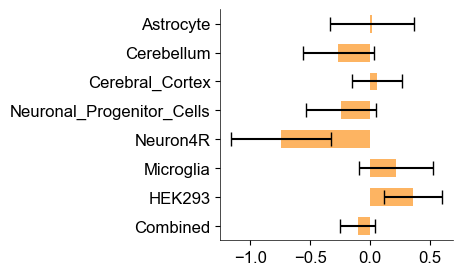

[<Figure size 300x300 with 1 Axes>, <Axes: >]

In [6]:
# horizontal_bar_graph(x_original=[output[key][0] for key in output.keys()], yticks=[key for key in output.keys()], xerr_original=[output[key][1] for key in output.keys()])

In [20]:
def plot_pvalues(ax, pval_list, bar_xlist, bar_toplist, bold_list = None, pval_star = False, pval_cutoff = 0.05, \
	pval_sci = True, fontsize = 15):
	'''
	pval_list = [0.03, 0.014, 0.62, ...]
	bold_list = [True, True, False, ...]
	'''
	prop.set_size(fontsize)
	if bold_list == None:
		bold_list = [False] * len(pval_list)
	
	ymin, ymax = ax.get_ylim()
	pval_height = (ymax - ymin) / 35

	for i, element in enumerate(pval_list):
		if pval_star == False:
			if element >= pval_cutoff:
				label = "n.s."
			else:
				if pval_sci == True:
					label = '{:0.1e}'.format(element)
				else:
					label = str(round(element, 2))
		else:
			print(element)
			if element >= pval_cutoff:
				label = "n.s."
			elif element < 0.0001:
				label = "****"
			else:
				label = "*" * (int('{:0.1e}'.format(element).split("-")[1]) - 1)
		if bold_list[i] == False:
			fontweight = 'normal'
		else:
			fontweight = 'bold'
		ax.text(bar_xlist[i], bar_toplist[i] + pval_height, label, fontweight = fontweight, fontproperties = prop, \
			ha = "center", va = "bottom")
	
	return


def bar_graph(
    xticks, y, color, output=None, y_err=None, y_lerr=None, y_uerr=None, title=None, ylim=None, xlim=None, ylabel=None, y_invert=False, xlabel=None,
    barWidth=0.618, pval_list=None, pval_cutoff=np.inf, pval_color="black", pval_sci=False, pval_star=False, figsize=None, fontsize=16, sci_tick=False,
    log=False, xtick_rotation=0, xtick_align_ha="center", xtick_align_va="center", bold=False,
    xaxis_pos=None, tick_bins=None, bottom=None, capsize=5, group_ranges=None, group_labels=None
):
    """
    Modified function to add group labels below xticks.
    
    Additional parameters:
    - group_ranges: List of tuples defining the range of bars in each group (e.g., [(0, 2), (3, 5)]).
    - group_labels: List of strings defining group names (e.g., ["Group A", "Group B"]).
    """

    # plt.figure(figsize=(barWidth*1.5*len(y)*3, 0.5*barWidth*3*len(y)*3))
    prop.set_size(fontsize)
    xtick_label = [item[0] for item in xticks]
    xtick_pos = [item[1] for item in xticks]

    if isinstance(pval_color, str):
        pval_color = [pval_color] * len(y)
    if isinstance(bold, bool):
        bold = [bold] * len(y)
    if figsize is not None:
        fig, ax = plt.subplots(nrows=1, ncols=1, figsize=figsize)
    else:
        fig, ax = plt.subplots(nrows=1, ncols=1)
    if y_err is not None:
        plt.bar(xtick_pos, y, width=barWidth, color=color, yerr=y_err, log=log, tick_label=xtick_label, bottom=bottom, capsize=capsize)
    elif y_lerr is not None and y_uerr is not None:
        asymmetric_error = np.array(list(zip(y_lerr, y_uerr))).T
        plt.bar(xtick_pos, y, width=barWidth, color=color, yerr=asymmetric_error, log=log, tick_label=xtick_label, bottom=bottom, capsize=capsize)
    else:
        plt.bar(xtick_pos, y, width=barWidth, color=color, log=log, tick_label=xtick_label, bottom=bottom)
    plt.xticks(rotation=xtick_rotation, ha=xtick_align_ha, va=xtick_align_va, fontproperties=prop)
    plt.yticks(fontproperties=prop)
    
    if group_ranges and group_labels:
        for (start, end), label in zip(group_ranges, group_labels):
            # Calculate the midpoint of the group range
            mid = (start + end) / 2

            # Draw a line connecting the bars in the group
            ax.plot(
            [start - 0.4, end + 0.4],
            [-0.25, -0.25],
            color="black",
            transform=ax.get_xaxis_transform(),
            clip_on=False,
            linewidth=1,
        )

            # Add the group label below the line
            ax.text(
            mid,
            -0.3,
            label,
            ha="center",
            va="top",
            fontsize=fontsize,
            transform=ax.get_xaxis_transform(),
        )


    if ylim is not None:
        plt.ylim(ylim)

    if pval_list is not None:
        if y_err is not None:
            bar_toplist = [a + b for a, b in zip(y, y_err)]
        elif y_uerr is not None:
            bar_toplist = [a + b for a, b in zip(y, y_uerr)]
        else:
            bar_toplist = y
        plot_pvalues(ax, pval_list, xtick_pos, bar_toplist, bold_list=bold, pval_star=pval_star, pval_cutoff=pval_cutoff, pval_sci=pval_sci, fontsize=fontsize)

    if title is not None:
        plt.title(title, fontproperties=prop)
    if xlim is not None:
        plt.xlim(xlim)
    else:
        plt.xlim(-0.5, len(xticks) - 0.5)
    if xlabel is not None:
        plt.xlabel(xlabel, fontproperties=prop)
    if ylabel is not None:
        plt.ylabel(ylabel, fontproperties=prop)
    if y_invert:
        plt.gca().invert_yaxis()
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)
    if sci_tick:
        plt.ticklabel_format(axis="y", style="sci", scilimits=(0, 3))
    if xaxis_pos is not None:
        ax.spines["bottom"].set_position(("data", xaxis_pos))
    if tick_bins is not None:
        plt.locator_params(nbins=tick_bins, axis="y")
    if output is not None:
        fig.savefig(output, bbox_inches="tight")
    plt.show()
    plt.close()

    return [fig, ax]


0.6835616199544788
0.6526079957680692
0.7892750511460669
0.01646356990209141
0.4385878617296159
0.6610006600116922


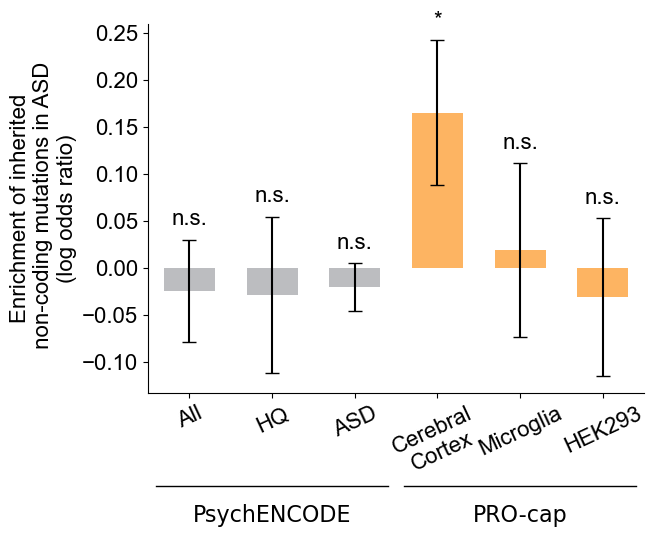

[<Figure size 640x480 with 1 Axes>,
 <Axes: ylabel='Enrichment of inherited\n non-coding mutations in ASD\n(log odds ratio)'>]

In [23]:
color_list = ['#BCBDC0' if i < 3 else '#fdb462' for i in range(len(output))]
group_ranges = [(0, 2), (3, 5)]  # Indices for Group A and Group B
group_labels = ["PsychENCODE", "PRO-cap"]
# Call the `bar_graph` function with the updated color list
bar_graph(
    xticks=[(key, index) for index, key in enumerate(output)],
    y=[output[key][0] for key in output.keys()],
    y_err=[output[key][1] for key in output.keys()],
    pval_list=[output[key][2] for key in output.keys()],
    ylabel="Enrichment of inherited\n non-coding mutations in ASD\n(log odds ratio)",
    pval_star=True,
    pval_cutoff=0.05,
    xtick_rotation=25,
    xtick_align_va="top",
    group_ranges=group_ranges,
    group_labels=group_labels,
    output="/fs/cbsuhy01/storage/yz2676/data/ABC/data/ASD_Transmitted_enrichment.pdf",
    color=color_list  # Pass the dynamic color list here
)


In [11]:
grant_dic = {"PsychENCODE_All": ["PsychENCODE_All"], "PsychENCODE_HQ": ["PsychENCODE_HQ"], "PsychENCODE_ASD": ["PsychENCODE_ASD"], "Cerebral_Cortex": ["CHTN22", "HN21"], "Microglia": ["Microglia"], "Astrocyte": ["SC3"], "HEK293": ["HEK293"]}#, "Progenitor": ["LUHMES.Li"]}#, "HEK293": ["HEK293"]}

In [4]:
### calculate fraction of damaging variants in each group
# all_var = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Enrichment_analysis_new/UCSF_DNV_ExcludeCoding_damaging.txt", sep="\t", header=0)
enh_var = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/Enrichment/UCSF_DNV_ExcludeCoding_damaging_enhancer_updated.txt", sep="\t", header=0)
all_var_ssc = all_var[all_var["SampleID"].str.startswith("SS") | all_var["SampleID"].str.startswith("SP")]
# enh_var = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Week8_429/CHTN13_CHTN22_HN21_LUHMES.Li_Microglia_Neuron4R_SC2_SC3/promoter.v43.coding/alpha.1/UCSF_DNV_ExcludeCoding_damaging_enhancer.txt", sep="\t", header=0)
# enh_var = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/Enrichment/UCSF_DNV_ExcludeCoding_damaging_enhancer_updated.txt", sep="\t", header=0)
# construct a case/control only variants set: #uploaded_variation is in format chr_pos_ref/alt
case_var = set(all_var_ssc[all_var_ssc["Pheno"] == "case"]["#Uploaded_variation"])
control_var = set(all_var_ssc[all_var_ssc["Pheno"] == "control"]["#Uploaded_variation"])
case_only = case_var - control_var
control_only = control_var - case_var

# rare damaging variants are defined as 1) not appear in gnomAD - rare 2) SNV with CADD>12 or Indel with phyloP>=2 - damaging
# v3.1 rare variants - gnomAD_AF_genome <= 0
enh_var_rare = enh_var[(enh_var["gnomAD_AF_genome"]<=0) & (enh_var["SampleID"].str.startswith("SS") | enh_var["SampleID"].str.startswith("SP"))]
# enh_var_rare = enh_var[(enh_var["gnomADg_AF"]<=0) & enh_var["SampleID"].str.startswith("SS")]
enh_var_damage = enh_var_rare[((enh_var_rare["TYPE"]=="SNV") & (enh_var_rare["CADD_PHRED"]>=12)) | ((enh_var_rare["TYPE"]=="Indel") & (enh_var_rare["phyloP100way"]>=2))]
# enh_var_damage = enh_var_rare[((enh_var_rare["CADD_RAW"]>=1))]

# load in different enhancer file and calculate the enrichment of variants in each file
output = {}
for enh_typ in grant_dic:
    if "psych" in enh_typ.lower():
        continue
    # enh_elements = pd.concat([pd.read_csv("/fs/cbsuhy02/storage/yz2676/ASD/pints/stringent/"+enh_acron+"/all_peaks_element_200bp_e.bed", sep="\t", dtype=str) for enh_acron in grant_dic[enh_typ]])
    enh_elements = pd.concat([pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Week8_429/"+enh_acron+"/promoter.v43.coding/all_peaks_element_200bp_e.bed", sep="\t", dtype=str) for enh_acron in grant_dic[enh_typ]])
    sample_elements = enh_elements.apply(lambda x: x["chr"] + ":" + x["start"] + "-" + x["end"], axis = 1).unique().tolist()
    element_var = enh_var_damage[enh_var_damage["Overlapped_elements_enhancer"].isin(sample_elements)]
    enhancer_var = enh_var_rare[enh_var_rare["Overlapped_elements_enhancer"].isin(sample_elements)]
#     print(element_var)
    x1 = element_var[element_var["#Uploaded_variation"].isin(case_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
    n1 = enhancer_var[enhancer_var["#Uploaded_variation"].isin(case_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
    x2 = element_var[element_var["#Uploaded_variation"].isin(control_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
    n2 = enhancer_var[enhancer_var["#Uploaded_variation"].isin(control_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
    p = bino2test(x1, n1, x2, n2)
    print(enh_typ, x1, n1, x2, n2, p)
    output[enh_typ] = [x1/n1, x2/n2, p]

/tmp/ipykernel_496809/2766024081.py:3: DtypeWarning: Columns (21) have mixed types. Specify dtype option on import or set low_memory=False.
  enh_var = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/Enrichment/UCSF_DNV_ExcludeCoding_damaging_enhancer_updated.txt", sep="\t", header=0)


Cerebral_Cortex 248 1289 140 812 0.25036768346624905
Microglia 159 1270 81 854 0.030292519381435734
HEK293 141 835 99 631 0.5397347399214929


In [12]:
### calculate fraction of damaging variants in each group
# enh_var = pd.read_csv("/local/storage/NetFlow_ASD/Week8_429/CHTN13_CHTN22_HN21_LUHMES.Li_Microglia_Neuron4R_SC2_SC3/promoter.v43.coding/UCSF_Transmitted_ExcludeCoding_damaging_enhancer.txt", sep="\t", header=0)
# all_var = pd.read_csv("/local/storage/NetFlow_ASD/Week8_429/UCSF_Transmitted_ExcludeCoding_damaging.txt", sep="\t", header=0)
# all_var_ssc = all_var[all_var["SampleID"].str.startswith("SP")]
# construct a case/control only variants set: #uploaded_variation is in format chr_pos_ref/alt
case_var = set(all_var[all_var["Pheno"] == "case"]["#Uploaded_variation"])
control_var = set(all_var[all_var["Pheno"] == "control"]["#Uploaded_variation"])
case_only = case_var - control_var
control_only = control_var - case_var

# rare damaging variants are defined as 1) not appear in gnomAD - rare 2) SNV with CADD>12 or Indel with phyloP>=2 - damaging
# v3.1 rare variants - gnomAD_AF_genome <= 0
enh_var_rare = enh_var[(enh_var["gnomADg_AF"]<=0)]# & enh_var["SampleID"].str.startswith("SP")]
# enh_var_damage = enh_var_rare[((enh_var_rare["TYPE"]=="SNV") & (enh_var_rare["CADD_PHRED"]>=12)) | ((enh_var_rare["TYPE"]=="Indel") & (enh_var_rare["phyloP100way"]>=2))]
enh_var_damage = enh_var_rare[((enh_var_rare["CADD_PHRED"]>=12))]

# load in different enhancer file and calculate the enrichment of variants in each file
output = {}
for enh_typ in grant_dic:
    if "psych" in enh_typ.lower():
        continue
    # enh_elements = pd.concat([pd.read_csv("/fs/cbsuhy02/storage/yz2676/ASD/pints/stringent/"+enh_acron+"/all_peaks_element_200bp_e.bed", sep="\t", dtype=str) for enh_acron in grant_dic[enh_typ]])
    enh_elements = pd.concat([pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Week8_429/"+enh_acron+"/promoter.v43.coding/all_peaks_element_200bp_e.bed", sep="\t", dtype=str) for enh_acron in grant_dic[enh_typ]])
    sample_elements = enh_elements.apply(lambda x: x["chr"] + ":" + x["start"] + "-" + x["end"], axis = 1).unique().tolist()
    element_var = enh_var_damage[enh_var_damage["Overlapped_elements_enhancer"].isin(sample_elements)]
    enhancer_var = enh_var_rare[enh_var_rare["Overlapped_elements_enhancer"].isin(sample_elements)]
#     print(element_var)
    x1 = element_var[element_var["#Uploaded_variation"].isin(case_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
    n1 = enhancer_var[enhancer_var["#Uploaded_variation"].isin(case_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
    x2 = element_var[element_var["#Uploaded_variation"].isin(control_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
    n2 = enhancer_var[enhancer_var["#Uploaded_variation"].isin(control_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
    p = bino2test(x1, n1, x2, n2)
    print(enh_typ, x1, n1, x2, n2, p)
    output[enh_typ] = [x1/n1, x2/n2, p]

Cerebral_Cortex 14947 93314 6721 42284 0.5667153426451248
Microglia 9347 90687 4298 40877 0.2530787937111014
Astrocyte 4399 30576 2032 13851 0.43176065332201863
HEK293 1034 5254 423 2298 0.19710200536324785


In [6]:
enh_var_rare

,locus,ref,alt,qual,filters,num_alleles,SampleID,fam_id,child_GT,father_GT,mother_GT,father_id,mother_id,chr,pos,#Uploaded_variation,start,end,Consequence,CADD_PHRED,phyloP100way,phastCons100way,gnomADg_AF,Variant_Classification,sex,Pheno,TYPE,Overlapped_elements_enhancer
5348,chr1:1274964,C,T,828.26,[],2,SP0146228,SF0146227,0/1,0/0,0/1,SP0147209,SP0146226,chr1,1274964,1_1274964_C/T,1274963,1274964,upstream_gene_variant,1.652,-1.044,0.0,-inf,NaN,male,control,SNV,chr1:1274567-1275012
5349,chr1:1274964,C,T,828.26,[],2,SP0146228,SF0146227,0/1,0/0,0/1,SP0147209,SP0146226,chr1,1274964,1_1274964_C/T,1274963,1274964,regulatory_region_variant,1.652,-1.044,0.0,-inf,NaN,male,control,SNV,chr1:1274567-1275012
12753,chr1:2358383,C,T,1105.50,[],2,SP0168898,SF0168898,0/1,0/0,0/1,SP0169695,SP0168896,chr1,2358383,1_2358383_C/T,2358382,2358383,intron_variant,0.605,-1.100,0.0,-inf,NaN,female,case,SNV,chr1:2358349-2359051
12754,chr1:2358383,C,T,1105.50,[],2,SP0168898,SF0168898,0/1,0/0,0/1,SP0169695,SP0168896,chr1,2358383,1_2358383_C/T,2358382,2358383,intron_variant&non_coding_transcript_variant,0.605,-1.100,0.0,-inf,NaN,female,case,SNV,chr1:2358349-2359051
12755,chr1:2358383,C,T,1105.50,[],2,SP0168898,SF0168898,0/1,0/0,0/1,SP0169695,SP0168896,chr1,2358383,1_2358383_C/T,2358382,2358383,downstream_gene_variant,0.605,-1.100,0.0,-inf,NaN,female,case,SNV,chr1:2358349-2359051
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13879957,chr22:50756454,C,T,825.54,[],2,SP0232451,SF0232451,0/1,0/1,0/0,SP0232728,SP0232450,chr22,50756454,22_50756454_C/T,50756453,50756454,regulatory_region_variant,2.277,-inf,-inf,-inf,NaN,male,case,SNV,chr22:50756425-50757158
13879958,chr22:50756454,C,T,825.54,[],2,SP0232451,SF0232451,0/1,0/1,0/0,SP0232728,SP0232450,chr22,50756454,22_50756454_C/T,50756453,50756454,regulatory_region_variant,2.277,-inf,-inf,-inf,NaN,male,case,SNV,chr22:50756337-50756826
13879997,chr22:50806900,G,A,871.07,[],2,SP0141709,SF0141709,0/1,0/1,0/0,SP0141799,SP0142376,chr22,50806900,22_50806900_G/A,50806899,50806900,intergenic_variant,4.378,-inf,-inf,-inf,NaN,female,case,SNV,chr22:50806892-50807611
13879998,chr22:50806900,G,A,871.07,[],2,SP0141709,SF0141709,0/1,0/1,0/0,SP0141799,SP0142376,chr22,50806900,22_50806900_G/A,50806899,50806900,intergenic_variant,4.378,-inf,-inf,-inf,NaN,female,case,SNV,chr22:50806857-50807559


In [24]:
enh_var.groupby(enh_var["SampleID"].str[:4]).size()

SampleID
KOR-     8569
SP00     6639
SP01    28422
SP02    22115
SS00      358
SSC0    62709
SSC1    22966
STAR      575
dtype: int64

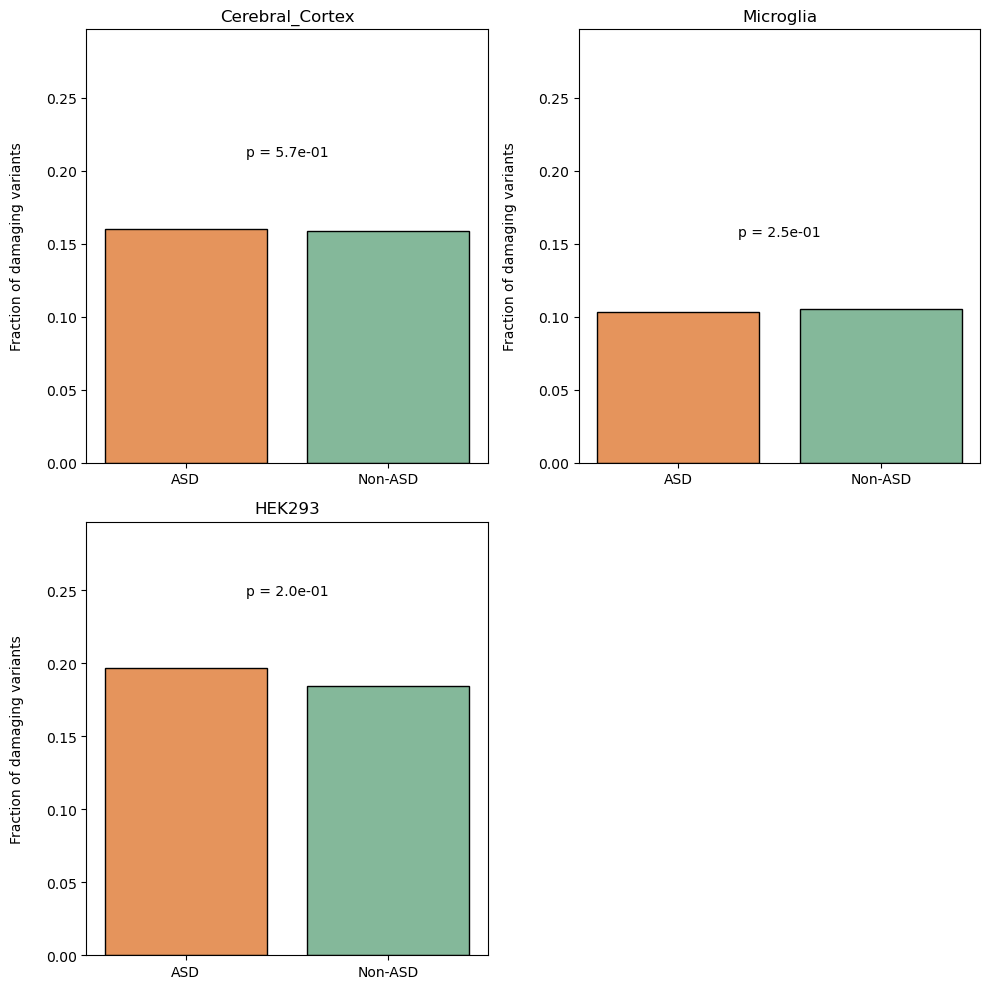

In [10]:
categories = list(output.keys())
values1 = [output[cat][0] for cat in categories]
values2 = [output[cat][1] for cat in categories]
p_values = [output[cat][2] for cat in categories]

# Colors for bars
colors = ["#E5945C", "#84B89A"]

fig, axes = plt.subplots(2, 2, figsize=(10, 10))  # 2 rows, 2 columns
axes = axes.flatten()

# Plot each category
for i, ax in enumerate(axes):
    if i < len(categories):
        # Plot bars
        bars = ax.bar(["ASD", "Non-ASD"], [values1[i], values2[i]], color=colors, edgecolor="black")
        
        # Add p-value annotation
        max_height = max(values1[i], values2[i])
        ax.text(0.5, max_height + 0.05, f"p = {p_values[i]:.1e}", ha="center", fontsize=10)

        # Add labels and title
        ax.set_title(categories[i], fontsize=12)
        ax.set_ylabel("Fraction of damaging variants\n", fontsize=10)
        ax.set_ylim(0, max(max(values1), max(values2)) + 0.1)

    else:
        ax.axis('off')  # Turn off any unused subplots

# Adjust layout
plt.tight_layout()
plt.show()

In [ ]:
enh_var = pd.read_csv("/local/storage/NetFlow_ASD/Week8_429/UCSF_Transmitted_ExcludeCoding_damaging.txt", sep="\t", header=0)
# construct a case/control only variants set: #uploaded_variation is in format chr_pos_ref/alt
case_var = set(all_var[all_var["Pheno"] == "case"]["#Uploaded_variation"])
control_var = set(all_var[all_var["Pheno"] == "control"]["#Uploaded_variation"])
case_only = case_var - control_var
control_only = control_var - case_var

# rare damaging variants are defined as 1) not appear in gnomAD - rare 2) SNV with CADD>12 or Indel with phyloP>=2 - damaging
# v3.1 rare variants - gnomAD_AF_genome <= 0
psychENCODE_enh_var = var_merge_psych[(var_merge_psych["gnomAD_AF_genome"]<=0) & ((var_merge_psych["TYPE"]=="SNV") & (var_merge_psych["CADD_PHRED"]>=12)) | ((var_merge_psych["TYPE"]=="Indel") & (var_merge_psych["phyloP100way"]>=2))]
enh_var_damage = enh_var[(enh_var["gnomADg_AF"]<=0) & (((enh_var["TYPE"]=="SNV") & (enh_var["CADD_PHRED"]>=12)) | ((enh_var["TYPE"]=="Indel") & (enh_var["phyloP100way"]>=2)))]
all_var_damage = all_var[(all_var["gnomADg_AF"]<=0) & (((all_var["TYPE"]=="SNV") & (all_var["CADD_PHRED"]>=12)) | ((all_var["TYPE"]=="Indel") & (all_var["phyloP100way"]>=2)))]


b = all_var_damage[all_var_damage["#Uploaded_variation"].isin(case_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
d = all_var_damage[all_var_damage["#Uploaded_variation"].isin(control_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
print(b,d)

# load in different enhancer file and calculate the enrichment of variants in each file
output = {}
for enh_typ in grant_dic:
    if "psych" in enh_typ.lower():
        enh_elements = pd.concat([pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Yutong_output/Enrichment/"+enh_acron+"_expanded.txt", sep="\t", header=0, dtype=str) for enh_acron in grant_dic[enh_typ]])
    else:
        enh_elements = pd.concat([pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/Week8_429/"+enh_acron+"/promoter.v43.coding/all_peaks_element_200bp_e.bed", sep="\t", dtype=str) for enh_acron in grant_dic[enh_typ]])
    sample_elements = enh_elements.apply(lambda x: x["chr"] + ":" + x["start"] + "-" + x["end"], axis = 1).unique().tolist()
    if "psych" in enh_typ.lower():
        element_var = psychENCODE_enh_var[psychENCODE_enh_var["Overlapped_element"].isin(sample_elements)]
    else:
        element_var = enh_var_damage[enh_var_damage["Overlapped_elements_enhancer"].isin(sample_elements)]
#     print(element_var)
    a = element_var[element_var["#Uploaded_variation"].isin(case_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
    c = element_var[element_var["#Uploaded_variation"].isin(control_only)][["chr", "pos", "ref", "alt", "SampleID"]].drop_duplicates().shape[0]
    print(enh_typ, a, c)
    OR, pval = fisher_exact([[a, b-a], [c, d-c]], alternative = "greater")
#     # table = [[a, b-a],
#     #          [c, d-c]]
#     # OR, pval, dof, expected = chi2_contingency(table)
    SE_log_OR = np.sqrt(1/a + 1/(b-a) + 1/c + 1/(d-c))
    print(enh_typ, OR, np.log(OR), SE_log_OR, pval)
    # print(enh_typ, np.log(OR), SE_log_OR, pval)
    output[enh_typ] = [np.log(OR), SE_log_OR, pval]


#### Variant linked-enhancers gene expression difference

In [ ]:
var = pd.read_csv("../input_data/mutation/UCSF_DNV_ExcludeCoding_damaging_enhancer.txt", sep="\t", header=0)
var

In [ ]:
file = pd.read_csv("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/Yingying_linkage.txt", sep="\t")
file
###annotate cell type
### distribution

#### Jesse's ABC results

In [4]:
ref_ABC = pd.read_csv("../Validation_results/AllPredictions.AvgHiC.ABC0.015.minus150.ForABCPaperV3.txt.gz", sep="\t")
len(list(ref_ABC["CellType"].unique()))

KeyboardInterrupt: 

In [ ]:
### cortex: ENCFF086IIR.bed.gz; ENCFF644DYV.bed.gz
### cerebellum: ENCFF982LFX.bed.gz; - very different input data
### astrocyte: ENCFF553YSD.bed.gz;
cortex = pybedtools.BedTool("../Validation_results/ENCFF086IIR.bed.gz").to_dataframe(disable_auto_names=True, header=None)
cortex.columns = cortex.iloc[0]
cortex = cortex.drop(cortex.index[0])
cortex.rename(columns={"#chr":"chr"},inplace=True)
cortex

In [ ]:
my_predictions = pd.read_csv("../ABC_output/Predictions/Cerebral_cortex/pints/EnhancerPredictions.txt", sep="\t")
# cortex.columns = cortex.iloc[0]
# cortex = cortex.drop(cortex.index[0])
my_predictions

In [ ]:
overlap = my_predictions[["TargetGene"]].drop_duplicates().merge(cortex[["TargetGene"]].drop_duplicates(),how="inner")
len(overlap)/len(cortex[["TargetGene"]].drop_duplicates())

#### Combine all EG-linkage results

In [ ]:
### linkage results without Microglia
samples = {"Astrocyte":["SC3_200bp_e.bed"], "Cerebellum":["CHTN13_v43_coding_200bp_e.bed"], "Cerebral_cortex":["CHTN22_v43_coding_200bp_e.bed", "HN21_v43_coding_200bp_e.bed"], "Excitatory_neurons":["/fs/cbsuhy02/storage/yz2676/ASD/pints/Neuron_4R/all_peaks_element_200bp_e.bed"], "Neuronal_stem_cell":["LUHMES.Li_v43_coding_200bp_e.bed"]}
df_mapping = []
for sample in samples.keys():
    df_mapping.append(pd.read_csv("../ABC_output/Predictions/"+sample+"/pints/EnhancerPredictions.txt", sep="\t"))
output = pd.concat(df_mapping)
output.to_csv("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/yutong_linkage.txt", sep="\t", header=True, index=None)

df_ori_ref = []
for sample in samples.keys():
    if sample != "Excitatory_neurons":
        df_ori_ref.append(pd.concat([pd.read_csv("../candidate_regions/"+sample+"/"+samples[sample][i], sep="\t", header=None, dtype=str) for i in range(len(samples[sample]))]))
    else:
        df_ori_ref.append(pd.read_csv(samples[sample][0], sep="\t", header=None))
ori_ref = pd.concat(df_ori_ref)
ori_ref.rename(columns={0: "chr", 1: "start", 2: "end"}, inplace=True)
ori_ref.to_csv("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/yutong_ref.txt", sep="\t", header=True, index=None)

### Comparisons of two EG-linkage files

#### Extract relevant EG-linkage from GeneHancer data

In [3]:
tissue = pd.read_table("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/GeneHancer/GeneHancer_AnnotSV_tissues_v5.20.txt")
# tissue["tissue"].drop_duplicates().to_csv("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/GeneHancer_tissue_types.txt", sep="\n", index=None)
tissue = tissue[tissue["tissue"].isin(["astrocyte", "Astrocytes", "neuronal stem cell", "neural stem progenitor cell", "H9 neural progenitor cells", "Cortex neurosphere", "neuron", "H9 neuron cells", "GM23338 bipolar neurons"])]
tissue = tissue.drop(columns=["category"])

element = pd.read_table("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/GeneHancer/GeneHancer_AnnotSV_elements_v5.20.txt")
element = element.merge(tissue, on="GHid", how="right").rename(columns={"is_elite": "enh_is_elite", "element_start": "start", "element_end": "end"})
# element = element[element["enh_is_elite"] == 1]
element["chr"] = element["chr"].apply(lambda x: "chr" + str(x))
element["Enhancer"] = element.apply(lambda row: f"{row['chr']}:{row['start']}-{row['end']}", axis=1)

gene = pd.read_table("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/GeneHancer/GeneHancer_AnnotSV_gene_association_scores_v5.20.txt")
gene = gene.merge(element, on="GHid", how="right").rename(columns={"is_elite": "association_is_elite", "symbol": "Gene"})
gene = gene[gene["association_is_elite"] == 1]
gene = gene[gene["regulatory_element_type"] == "Enhancer"]
gene.to_csv("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/GeneHancer_linkage.txt", index=False, sep="\t", header=True)

/tmp/ipykernel_3684753/3205763.py:1: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  tissue = pd.read_table("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/GeneHancer/GeneHancer_AnnotSV_tissues_v5.20.txt")
/tmp/ipykernel_3684753/3205763.py:6: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  element = pd.read_table("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/GeneHancer/GeneHancer_AnnotSV_elements_v5.20.txt")


In [2]:
def join_columns(row):
    base = row['Enhancer']
    values = row['Linked_genes'].split(',')
    return [f"{base}-{v}" for v in values]

In [3]:
yutong_linkage = pd.read_table("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/yutong_linked_enhancers.txt").dropna()
yutong_linkage["Enhancer"] = yutong_linkage.apply(lambda row: '-'.join((row['chr'], str(row['start']), str(row['end']))), axis=1)

yutong_linkage["EG-linkage"] = yutong_linkage.apply(join_columns, axis=1)
yutong_linkage = yutong_linkage.explode("EG-linkage").reset_index(drop=True)

# unique_values = set()
# yutong_linkage["Linked_genes"].apply(lambda x: unique_values.update(x.split(",")))
# unique_values_list_yutong = list(unique_values)
# unique_values_list_yutong

In [4]:
yingying_linkage = pd.read_table("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/yingying_linked_enhancers.txt").dropna()
yingying_linkage["Enhancer"] = yingying_linkage.apply(lambda row: '-'.join((row['chr'], str(row['start']), str(row['end']))), axis=1)

yingying_linkage["EG-linkage"] = yingying_linkage.apply(join_columns, axis=1)
yingying_linkage = yingying_linkage.explode("EG-linkage").reset_index(drop=True)

# unique_values = set()
# yingying_linkage["Linked_genes"].apply(lambda x: unique_values.update(x.split(",")))
# unique_values_list_yingying = list(unique_values)

In [5]:
genehancer_linkage = pd.read_table("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/GeneHancer_linked_enhancers.txt").dropna()
genehancer_linkage["Enhancer"] = genehancer_linkage.apply(lambda row: '-'.join((row['chr'], str(row['start']), str(row['end']))), axis=1)
genehancer_linkage

genehancer_linkage["EG-linkage"] = genehancer_linkage.apply(join_columns, axis=1)
genehancer_linkage = genehancer_linkage.explode("EG-linkage").reset_index(drop=True)
# unique_values = set()
# genehancer_linkage["Linked_genes"].apply(lambda x: unique_values.update(x.split(",")))
# unique_values_list_genehancer = list(unique_values)

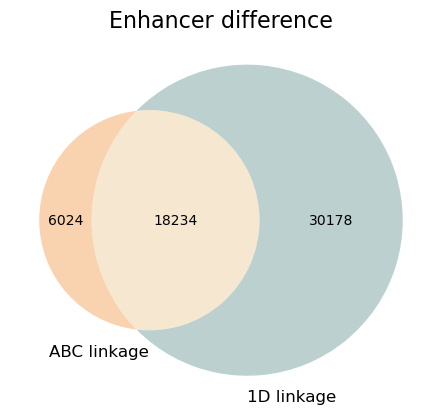

In [20]:
venn2([set(yutong_linkage["Enhancer"].drop_duplicates()), set(yingying_linkage["Enhancer"].drop_duplicates())], ('ABC linkage', '1D linkage'),set_colors=("#F28F3B", 
                             "#588B8B"))

# Display the plot
plt.title('Enhancer difference', fontsize=16)
plt.show()

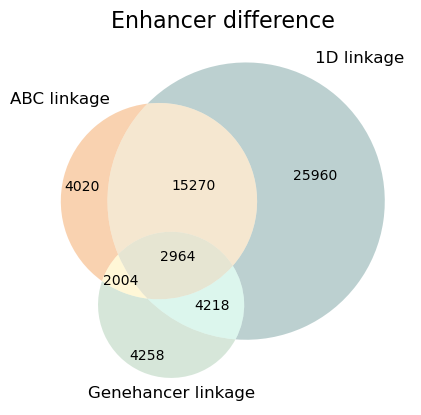

In [40]:
venn3([set(yutong_linkage["Enhancer"].drop_duplicates()), set(yingying_linkage["Enhancer"].drop_duplicates()), 
       set(genehancer_linkage["Enhancer"].drop_duplicates())], ('ABC linkage', '1D linkage', 'Genehancer linkage'),
       set_colors=("#F28F3B", "#588B8B", "#99C2A2"))

# Display the plot
plt.title('Enhancer difference', fontsize=16)
plt.show()

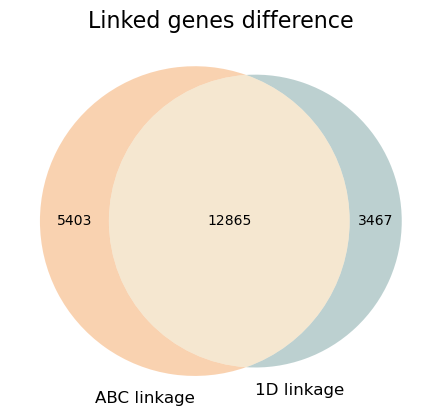

In [22]:
venn2([set(unique_values_list_yutong), set(unique_values_list_yingying)], ('ABC linkage', '1D linkage'),
      set_colors=("#F28F3B", "#588B8B"))

# Display the plot
plt.title('Linked genes difference', fontsize=16)
plt.show()

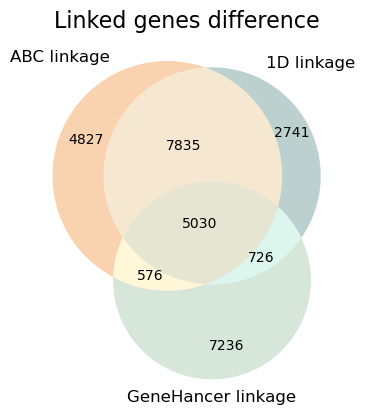

In [46]:
venn3([set(unique_values_list_yutong), set(unique_values_list_yingying), set(unique_values_list_genehancer)], ('ABC linkage', '1D linkage', 'GeneHancer linkage'),
      set_colors=("#F28F3B", "#588B8B", "#99C2A2"))

# Display the plot
plt.title('Linked genes difference', fontsize=16)
plt.show()

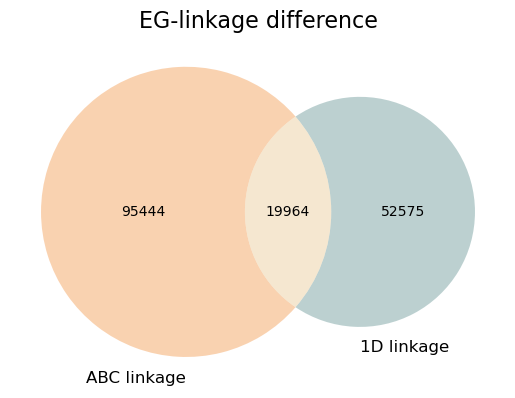

In [7]:
venn2([set(yutong_linkage["EG-linkage"]), set(yingying_linkage["EG-linkage"])], ('ABC linkage', '1D linkage'),
      set_colors=("#F28F3B", "#588B8B"))

# Display the plot
plt.title('EG-linkage difference', fontsize=16)
plt.show()

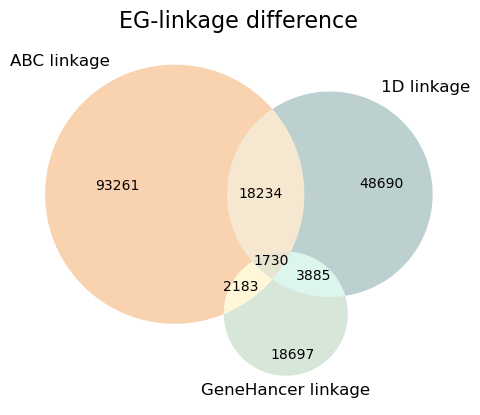

In [8]:
venn3([set(yutong_linkage["EG-linkage"]), set(yingying_linkage["EG-linkage"]), set(genehancer_linkage["EG-linkage"])], ('ABC linkage', '1D linkage', 'GeneHancer linkage'),
      set_colors=("#F28F3B", "#588B8B", "#99C2A2"))

# Display the plot
plt.title('EG-linkage difference', fontsize=16)
plt.show()

#### TADA output

In [4]:
def merge_elements(row):
    x = row['Overlapped_elements_x']
    y = row['Overlapped_elements_y']
    
    if pd.isna(x) and pd.isna(y):
        return np.nan
    elif pd.isna(x):
        return y
    elif pd.isna(y):
        return x
    else:
        return f"{x},{y}"
    
def merge_genes(row):
    x = row['Linked_genes_x']
    y = row['Linked_genes_y']
    
    if pd.isna(x) and pd.isna(y):
        return np.nan
    elif pd.isna(x):
        return y
    elif pd.isna(y):
        return x
    else:
        return f"{x},{y}"

In [4]:
### merge EG-linkage datasets
# ABC_EG_linkage = pd.read_table("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/yutong_linked_enhancers.txt")
# yingying_EG_linkage = pd.read_table("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/yingying_linked_enhancers.txt")
# GeneHancer_EG_linakge = pd.read_table("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/GeneHancer_linked_enhancers.txt")

# merged_linkage = ABC_EG_linkage.merge(yingying_EG_linkage, on=["chr", "start","end"], how="inner")
# merged_linkage['Overlapped_elements'] = merged_linkage.apply(merge_elements, axis=1)
# merged_linkage["Linked_genes"] = merged_linkage.apply(merge_genes, axis=1)
# merged_linkage.drop(columns=["Overlapped_elements_x", "Overlapped_elements_y", "Linked_genes_x", "Linked_genes_y"], inplace=True)
# merged_linkage.to_csv("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/ABC+1D_linked_enhancers.txt", index=False, sep="\t")

# merged_linkage = ABC_EG_linkage.merge(GeneHancer_EG_linakge, on=["chr", "start","end"], how="inner")
# merged_linkage['Overlapped_elements'] = merged_linkage.apply(merge_elements, axis=1)
# merged_linkage["Linked_genes"] = merged_linkage.apply(merge_genes, axis=1)
# merged_linkage.drop(columns=["Overlapped_elements_x", "Overlapped_elements_y", "Linked_genes_x", "Linked_genes_y"], inplace=True)
# merged_linkage.to_csv("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/ABC+GH_linked_enhancers.txt", index=False, sep="\t")

# merged_linkage = yingying_EG_linkage.merge(GeneHancer_EG_linakge, on=["chr", "start","end"], how="inner")
# merged_linkage['Overlapped_elements'] = merged_linkage.apply(merge_elements, axis=1)
# merged_linkage["Linked_genes"] = merged_linkage.apply(merge_genes, axis=1)
# merged_linkage.drop(columns=["Overlapped_elements_x", "Overlapped_elements_y", "Linked_genes_x", "Linked_genes_y"], inplace=True)
# merged_linkage.to_csv("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/GH+1D_linked_enhancers.txt", index=False, sep="\t")

# ABC_1D_linkage = pd.read_table("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/ABC+1D_linked_enhancers.txt")
# merged_linkage = ABC_1D_linkage.merge(GeneHancer_EG_linakge, on=["chr", "start","end"], how="inner")
# merged_linkage['Overlapped_elements'] = merged_linkage.apply(merge_elements, axis=1)
# merged_linkage["Linked_genes"] = merged_linkage.apply(merge_genes, axis=1)
# merged_linkage.drop(columns=["Overlapped_elements_x", "Overlapped_elements_y", "Linked_genes_x", "Linked_genes_y"], inplace=True)
# merged_linkage.to_csv("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/Combined_linked_enhancers.txt", index=False, sep="\t")

In [3]:
ABC_TADA_output = pd.read_table("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/TADA_output/TADA_output_updated/FuScaled_ABC.txt")
ABC_fdr = ABC_TADA_output[ABC_TADA_output["fdr"]<=0.05]
print("ABC:", len(ABC_fdr))

yingying_TADA_output = pd.read_table("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/TADA_output/TADA_output_updated/FuScaled_1D.txt")
yingying_fdr = yingying_TADA_output[yingying_TADA_output["fdr"]<=0.05]
print("1D:", len(yingying_fdr))

GH_TADA_output = pd.read_table("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/TADA_output/TADA_output_updated/FuScaled_GH.txt")
GH_fdr = GH_TADA_output[GH_TADA_output["fdr"]<=0.05]
print("GeneHancer:", len(GH_fdr))

ABC_1D_output = pd.read_table("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/TADA_output/TADA_output_updated/FuScaled_ABC+1D.txt")
ABC_1D_fdr = ABC_1D_output[ABC_1D_output["fdr"]<=0.05]
print("ABC+1D:", len(ABC_1D_fdr))

ABC_GH_output = pd.read_table("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/TADA_output/TADA_output_updated/FuScaled_ABC+GH.txt")
ABC_GH_fdr = ABC_GH_output[ABC_GH_output["fdr"]<=0.05]
print("ABC+GH:", len(ABC_GH_fdr))

GH_1D_output = pd.read_table("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/TADA_output/TADA_output_updated/FuScaled_GH+1D.txt")
GH_1D_fdr = GH_1D_output[GH_1D_output["fdr"]<=0.05]
print("GH+1D:", len(GH_1D_fdr))

combined_output = pd.read_table("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/TADA_output/TADA_output_updated/FuScaled_combined.txt")
combined_fdr = combined_output[combined_output["fdr"]<=0.05]
print("combined:", len(combined_fdr))

only_coding_output = pd.read_table("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/TADA_output/FuScaled_only_coding.txt")
coding_fdr = only_coding_output[only_coding_output["fdr"]<=0.05]
print("coding:", len(coding_fdr))

ABC: 78
1D: 118
GeneHancer: 62
ABC+1D: 110
ABC+GH: 93
GH+1D: 129
combined: 121
coding: 57


In [4]:
def subselect_asd_ls(TADA_df, known_ls):
    """
    Return a dataframe with FDR<=0.05 and Gene name (Hugo_Symbol) is in the known ASD list
    """
    return TADA_df[(TADA_df["fdr"]<=0.05) & (TADA_df["Hugo_Symbol"].isin(known_ls))]

# ABC_asd = subselect_asd_ls(ABC_TADA_output, sfari_asd_ls)
# yingying_asd = subselect_asd_ls(yingying_TADA_output, sfari_asd_ls)
# GH_asd = subselect_asd_ls(GH_TADA_output, sfari_asd_ls)
# ABC_1D_asd = subselect_asd_ls(ABC_1D_output, sfari_asd_ls)
# ABC_GH_asd = subselect_asd_ls(ABC_GH_output, sfari_asd_ls)
# GH_1D_asd = subselect_asd_ls(GH_1D_output, sfari_asd_ls)
# combined_asd = subselect_asd_ls(combined_output, sfari_asd_ls)
# coding_asd = subselect_asd_ls(only_coding_output, sfari_asd_ls)

siwei_ls = pd.read_csv("/fs/cbsuhy02/storage/yz2296/Burden_test_for_Autism/Paper/SFARI_GeneList/Siwei_GeneList.txt", sep="\t", header=None)[0].to_list()

ABC_asd = subselect_asd_ls(ABC_TADA_output, siwei_ls)
yingying_asd = subselect_asd_ls(yingying_TADA_output, siwei_ls)
GH_asd = subselect_asd_ls(GH_TADA_output, siwei_ls)
ABC_1D_asd = subselect_asd_ls(ABC_1D_output, siwei_ls)
ABC_GH_asd = subselect_asd_ls(ABC_GH_output, siwei_ls)
GH_1D_asd = subselect_asd_ls(GH_1D_output, siwei_ls)
combined_asd = subselect_asd_ls(combined_output, siwei_ls)
coding_asd = subselect_asd_ls(only_coding_output, siwei_ls)

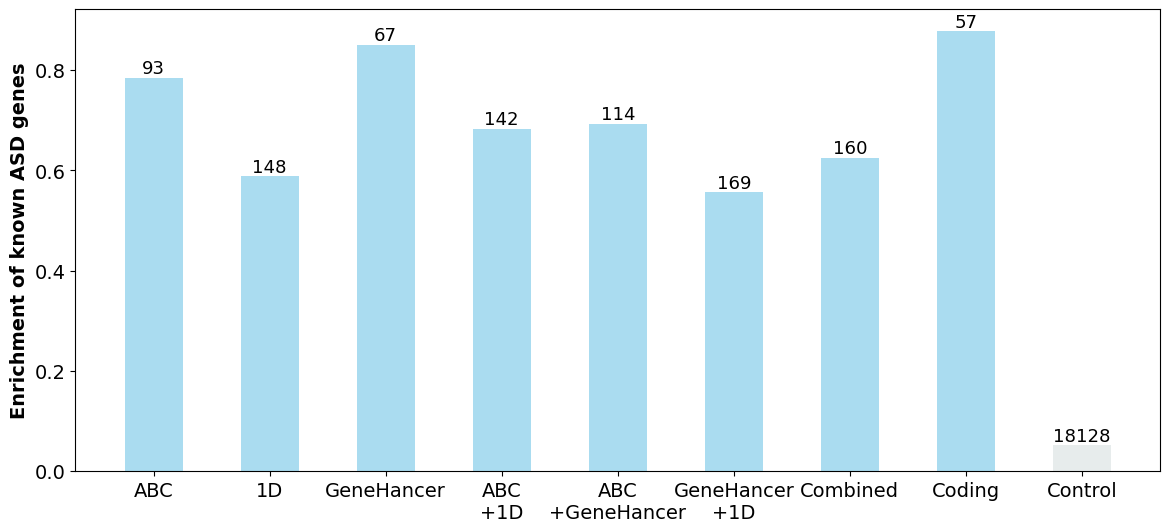

In [19]:
data = [len(ABC_asd)/len(ABC_fdr), len(yingying_asd)/len(yingying_fdr), len(GH_asd)/len(GH_fdr), len(ABC_1D_asd)/len(ABC_1D_fdr), len(ABC_GH_asd)/len(ABC_GH_fdr), len(GH_1D_asd)/len(GH_1D_fdr), len(combined_asd)/len(combined_fdr), len(coding_asd)/len(coding_fdr), len(sfari_high_conf)/len(ABC_TADA_output)]
categories = ['ABC', "1D", "GeneHancer", 'ABC\n+1D', "ABC\n+GeneHancer", "GeneHancer\n+1D", "Combined", "Coding", "Control"]
identified_asd_genes = [len(ABC_fdr), len(yingying_fdr), len(GH_fdr), len(ABC_1D_fdr), len(ABC_GH_fdr), len(GH_1D_fdr), len(combined_fdr), len(coding_fdr), len(ABC_TADA_output)]

# Plotting the barplot with error bars that represent the confidence intervals
plt.figure(figsize=(14, 6))
colors = ["skyblue"]*(len(categories)-1)+["#dee5e5"]
bars = plt.bar(categories, data, width=0.5, alpha=0.7, color=colors, capsize=10)

# Add value labels on top of each bar
index = 0
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval, identified_asd_genes[index], ha='center', va='bottom', fontsize=13)
    index+=1

# Add a title and labels
plt.title('')
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.ylabel('Enrichment of known ASD genes', fontsize=14, fontweight="bold")

# Show the plot
plt.show()

In [5]:
def p_value_to_asterisks(p_value_list):
    """ 
    """
    output = []
    for p_val in p_value_list:
        if p_val > 0.05:
            output.append("n.s.")
        elif 0.01 < p_val <= 0.05:
            output.append("*")
        elif 0.001 < p_val <= 0.01:
            output.append("**")
        elif 0.0001 < p_val <= 0.001:
            output.append("***")
        else:
            output.append("****")
    return output

p_value_abc = bino2test(len(ABC_asd),len(ABC_fdr),len(coding_asd),len(coding_fdr))
p_value_yingying = bino2test(len(yingying_asd),len(yingying_fdr),len(coding_asd),len(coding_fdr))
p_value_gh = bino2test(len(GH_asd),len(GH_fdr),len(coding_asd),len(coding_fdr))
p_value_combined = bino2test(len(combined_asd),len(combined_fdr),len(coding_asd),len(coding_fdr))
p_values = p_value_to_asterisks([p_value_abc,p_value_yingying,p_value_gh,p_value_combined])

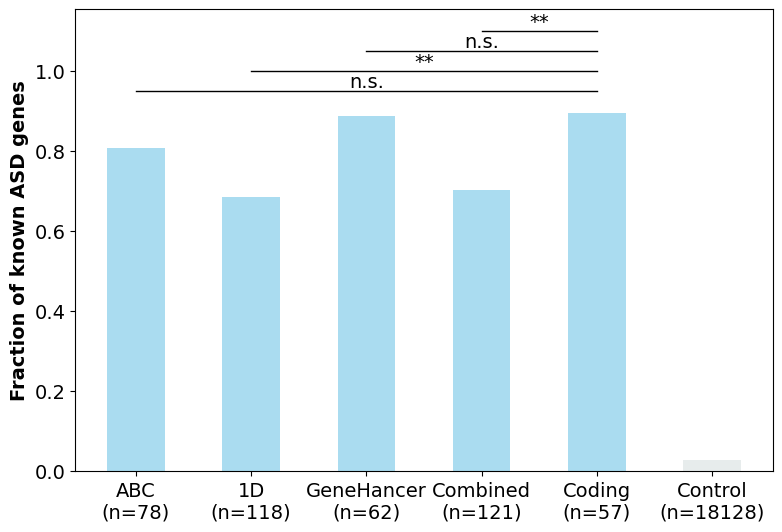

In [7]:
data = [len(set(ABC_asd["Hugo_Symbol"]))/len(set(ABC_fdr["Hugo_Symbol"])), len(yingying_asd)/len(yingying_fdr), len(GH_asd)/len(GH_fdr), len(combined_asd)/len(combined_fdr), len(coding_asd)/len(coding_fdr), len(siwei_ls)/len(ABC_TADA_output)]
categories = ['ABC\n(n='+str(len(ABC_fdr))+')', "1D\n(n="+str(len(yingying_fdr))+")",\
               "GeneHancer\n(n="+str(len(GH_fdr))+")", "Combined\n(n="+str(len(combined_fdr))+")",\
               "Coding\n(n="+str(len(coding_fdr))+")", "Control\n(n="+str(len(ABC_TADA_output))+")"]
identified_asd_genes = [len(set(ABC_fdr["Hugo_Symbol"])), len(yingying_fdr), len(GH_fdr), len(combined_fdr), len(coding_fdr), len(ABC_TADA_output)]

# Plotting the barplot with error bars that represent the confidence intervals
plt.figure(figsize=(9, 6))
colors = ["skyblue"]*(len(categories)-1)+["#dee5e5"]
bars = plt.bar(categories, data, width=0.5, alpha=0.7, color=colors, capsize=10)

# # Add value labels on top of each bar
# index = 0
# for bar in bars:
#     yval = bar.get_height()
#     plt.text(bar.get_x() + bar.get_width()/2, yval, identified_asd_genes[index], ha='center', va='bottom', fontsize=13)
#     index+=1

# Adding horizontal line and significance stars
for x in range(0,4):
    y = 0.95 + 0.05*x
    plt.plot([x, 4], [y, y], lw=1, c="black")
    plt.text((x+4) * .5, y, p_values[x], fontsize=14, ha='center', va='bottom', color="black")

# Add a title and labels
plt.title('')
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.ylabel('Fraction of known ASD genes', fontsize=14, fontweight="bold")

# Show the plot
plt.show()

In [8]:
### calculate enrichment of ASD genes in each linkage dataset
ABC_output = calc_enr(len(ABC_asd), len(ABC_fdr), len(siwei_ls), len(ABC_TADA_output))
yingying_output = calc_enr(len(yingying_asd), len(yingying_fdr), len(siwei_ls), len(ABC_TADA_output))
GH_output = calc_enr(len(GH_asd), len(GH_fdr), len(siwei_ls), len(ABC_TADA_output))
ABC_1D_output = calc_enr(len(ABC_1D_asd), len(ABC_1D_fdr), len(siwei_ls), len(ABC_TADA_output))
ABC_GH_output = calc_enr(len(ABC_GH_asd), len(ABC_GH_fdr), len(siwei_ls), len(ABC_TADA_output))
GH_1D_output = calc_enr(len(GH_1D_asd), len(GH_1D_fdr), len(siwei_ls), len(ABC_TADA_output))
combined_output = calc_enr(len(combined_asd), len(combined_fdr), len(siwei_ls), len(ABC_TADA_output))
coding_output = calc_enr(len(coding_asd), len(coding_fdr), len(siwei_ls), len(ABC_TADA_output))

enrichment_groups = {"ABC": ABC_output, "1D": yingying_output, "GeneHancer": GH_output, \
                     "ABC+1D": ABC_1D_output, "ABC+GeneHancer": ABC_GH_output, \
                    "GeneHancer+1D": GH_1D_output, "Combined": combined_output, "Coding": coding_output}
coding_output
# [enr, np.log(enr), SE_log_enr, pval, z, conf_intervals]

[31.741270985683386,
 3.4576177579538587,
 0.0629743389583415,
 0.0,
 54.905185431817344,
 (28.055657965985734, 35.91105526764242)]

0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0


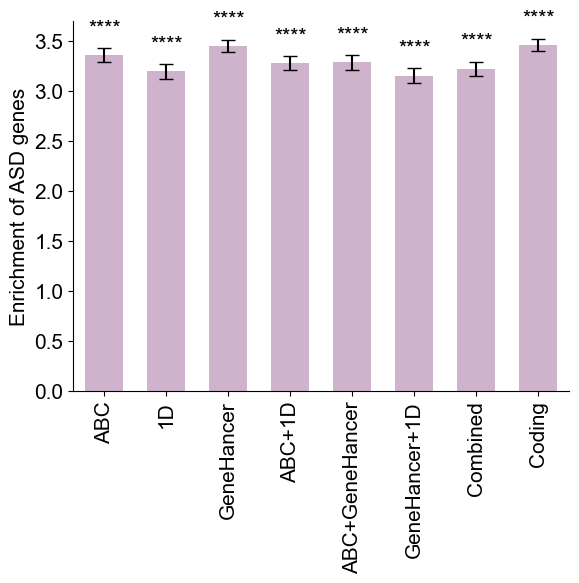

[<Figure size 640x480 with 1 Axes>, <Axes: ylabel='Enrichment of ASD genes'>]

In [9]:
bar_graph(xticks=[(key, index) for index, key in enumerate(enrichment_groups)], y=[enrichment_groups[key][1] for key in enrichment_groups.keys()], y_err=[enrichment_groups[key][2] for key in enrichment_groups.keys()], pval_list=[enrichment_groups[key][3] for key in enrichment_groups.keys()], ylabel="Enrichment of ASD genes", pval_star=True, pval_cutoff=0.05, xtick_rotation=90, xtick_align_va="top", color="#CFB3CD")

In [6]:
# the enrichment/fraction of ASD genes in each linkage dataset excluding coding genes
ABC_not_coding_fdr = ABC_fdr[~ABC_fdr["Hugo_Symbol"].isin(coding_fdr["Hugo_Symbol"])]
yingying_not_coding_fdr = yingying_fdr[~yingying_fdr["Hugo_Symbol"].isin(coding_fdr["Hugo_Symbol"])]
GH_not_coding_fdr = GH_fdr[~GH_fdr["Hugo_Symbol"].isin(coding_fdr["Hugo_Symbol"])]
ABC_1D_not_coding_fdr = ABC_1D_fdr[~ABC_1D_fdr["Hugo_Symbol"].isin(coding_fdr["Hugo_Symbol"])]
ABC_GH_not_coding_fdr = ABC_GH_fdr[~ABC_GH_fdr["Hugo_Symbol"].isin(coding_fdr["Hugo_Symbol"])]
GH_1D_not_coding_fdr = GH_1D_fdr[~GH_1D_fdr["Hugo_Symbol"].isin(coding_fdr["Hugo_Symbol"])]
combined_not_coding_fdr = combined_fdr[~combined_fdr["Hugo_Symbol"].isin(coding_fdr["Hugo_Symbol"])]
len(yingying_not_coding_fdr)

62

In [7]:
ABC_not_coding_asd = subselect_asd_ls(ABC_not_coding_fdr, siwei_ls)
yingying_not_coding_asd = subselect_asd_ls(yingying_not_coding_fdr, siwei_ls)
GH_not_coding_asd = subselect_asd_ls(GH_not_coding_fdr, siwei_ls)
ABC_1D_not_coding_asd = subselect_asd_ls(ABC_1D_not_coding_fdr, siwei_ls)
ABC_GH_not_coding_asd = subselect_asd_ls(ABC_GH_not_coding_fdr, siwei_ls)
GH_1D_not_coding_asd = subselect_asd_ls(GH_1D_not_coding_fdr, siwei_ls)
combined_not_coding_asd = subselect_asd_ls(combined_not_coding_fdr, siwei_ls)

# ABC_not_coding_asd = subselect_asd_ls(ABC_not_coding_fdr, sfari_asd_ls)
# yingying_not_coding_asd = subselect_asd_ls(yingying_not_coding_fdr, sfari_asd_ls)
# GH_not_coding_asd = subselect_asd_ls(GH_not_coding_fdr, sfari_asd_ls)
# ABC_1D_not_coding_asd = subselect_asd_ls(ABC_1D_not_coding_fdr, sfari_asd_ls)
# ABC_GH_not_coding_asd = subselect_asd_ls(ABC_GH_not_coding_fdr, sfari_asd_ls)
# GH_1D_not_coding_asd = subselect_asd_ls(GH_1D_not_coding_fdr, sfari_asd_ls)
# combined_not_coding_asd = subselect_asd_ls(combined_not_coding_fdr, sfari_asd_ls)
len(yingying_not_coding_asd)

25

In [11]:
p_value_abc = bino2test(len(ABC_not_coding_asd),len(ABC_not_coding_fdr),len(coding_asd),len(coding_fdr))
p_value_yingying = bino2test(len(yingying_not_coding_asd),len(yingying_not_coding_fdr),len(coding_asd),len(coding_fdr))
p_value_gh = bino2test(len(GH_not_coding_asd),len(GH_not_coding_fdr),len(coding_asd),len(coding_fdr))
p_value_combined = bino2test(len(combined_not_coding_asd),len(combined_not_coding_fdr),len(coding_asd),len(coding_fdr))
p_values = p_value_to_asterisks([p_value_abc,p_value_yingying,p_value_gh,p_value_combined])

p_value_abc_combined = bino2test(len(ABC_not_coding_asd),len(ABC_not_coding_fdr),len(combined_not_coding_asd),len(combined_not_coding_fdr))
p_value_abc_combined

0.6664919200915598

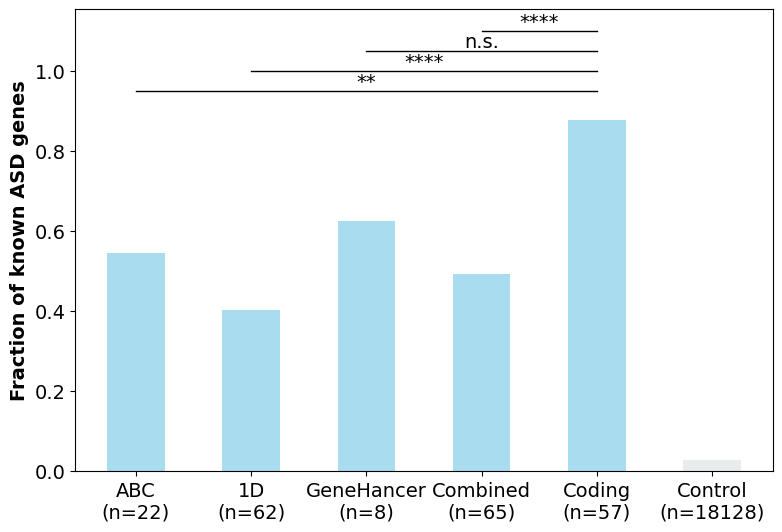

In [12]:
data = [len(set(ABC_not_coding_asd["Hugo_Symbol"]))/len(set(ABC_not_coding_fdr["Hugo_Symbol"])), len(yingying_not_coding_asd)/len(yingying_not_coding_fdr), len(GH_not_coding_asd)/len(GH_not_coding_fdr), len(combined_not_coding_asd)/len(combined_not_coding_fdr), len(coding_asd)/len(coding_fdr), len(siwei_ls)/len(ABC_TADA_output)]
categories = ['ABC\n(n='+str(len(ABC_not_coding_fdr))+')', "1D\n(n="+str(len(yingying_not_coding_fdr))+")",\
               "GeneHancer\n(n="+str(len(GH_not_coding_fdr))+")", "Combined\n(n="+str(len(combined_not_coding_fdr))+")",\
               "Coding\n(n="+str(len(coding_fdr))+")", "Control\n(n="+str(len(ABC_TADA_output))+")"]
identified_asd_genes = [len(set(ABC_not_coding_asd["Hugo_Symbol"])), len(yingying_not_coding_fdr), len(GH_not_coding_fdr), len(combined_not_coding_fdr), len(coding_fdr), len(ABC_TADA_output)]

# Plotting the barplot with error bars that represent the confidence intervals
plt.figure(figsize=(9, 6))
colors = ["skyblue"]*(len(categories)-1)+["#dee5e5"]
bars = plt.bar(categories, data, width=0.5, alpha=0.7, color=colors, capsize=10)

# # Add value labels on top of each bar
# index = 0
# for bar in bars:
#     yval = bar.get_height()
#     plt.text(bar.get_x() + bar.get_width()/2, yval, identified_asd_genes[index], ha='center', va='bottom', fontsize=13)
#     index+=1

# Adding horizontal line and significance stars
for x in range(0,4):
    y = 0.95 + 0.05*x
    plt.plot([x, 4], [y, y], lw=1, c="black")
    plt.text((x+4) * .5, y, p_values[x], fontsize=14, ha='center', va='bottom', color="black")

# Add a title and labels
plt.title('')
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.ylabel('Fraction of known ASD genes', fontsize=14, fontweight="bold")

# Show the plot
plt.show()

In [16]:
ABC_output = calc_enr(len(ABC_not_coding_asd), len(ABC_not_coding_fdr), len(siwei_ls), len(ABC_TADA_output))
yingying_output = calc_enr(len(yingying_not_coding_asd), len(yingying_not_coding_fdr), len(siwei_ls), len(ABC_TADA_output))
GH_output = calc_enr(len(GH_not_coding_asd), len(GH_not_coding_fdr), len(siwei_ls), len(ABC_TADA_output))
ABC_1D_output = calc_enr(len(ABC_1D_not_coding_asd), len(ABC_1D_not_coding_fdr), len(siwei_ls), len(ABC_TADA_output))
ABC_GH_output = calc_enr(len(ABC_GH_not_coding_asd), len(ABC_GH_not_coding_fdr), len(siwei_ls), len(ABC_TADA_output))
GH_1D_output = calc_enr(len(GH_1D_not_coding_asd), len(GH_1D_not_coding_fdr), len(siwei_ls), len(ABC_TADA_output))
combined_output = calc_enr(len(combined_not_coding_asd), len(combined_not_coding_fdr), len(siwei_ls), len(ABC_TADA_output))
coding_output = calc_enr(len(coding_asd), len(coding_fdr), len(siwei_ls), len(ABC_TADA_output))

enrichment_groups = {"ABC": ABC_output, "1D": yingying_output, "GeneHancer": GH_output, \
                     "ABC+1D": ABC_1D_output, "ABC+GeneHancer": ABC_GH_output, \
                    "GeneHancer+1D": GH_1D_output, "Combined": combined_output, "Coding": coding_output}
ABC_output

[19.35029354207436,
 2.9627075894937676,
 0.1994506749998502,
 6.520963631610626e-50,
 14.854337241505915,
 (13.089252188091338, 28.60620719838422)]

6.520963631610626e-50
1.0954366675624287e-61
5.431131865955032e-29
2.6117916214756763e-128
3.756237280791547e-89
3.5174393679343265e-80
3.857833947861192e-102
0.0


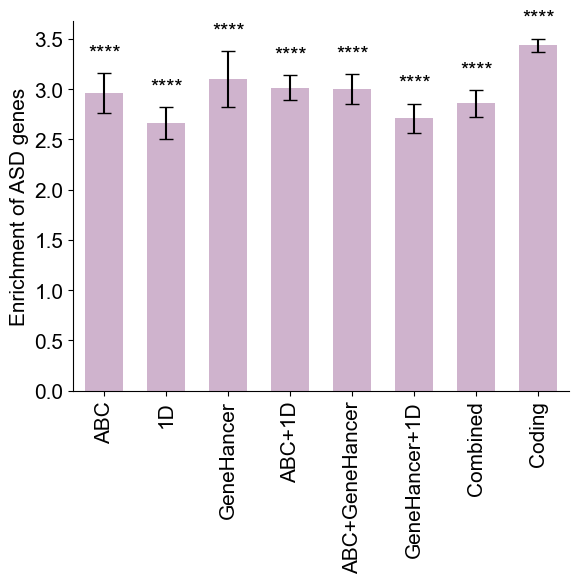

[<Figure size 640x480 with 1 Axes>, <Axes: ylabel='Enrichment of ASD genes'>]

In [15]:
bar_graph(xticks=[(key, index) for index, key in enumerate(enrichment_groups)], y=[enrichment_groups[key][1] for key in enrichment_groups.keys()], y_err=[enrichment_groups[key][2] for key in enrichment_groups.keys()], pval_list=[enrichment_groups[key][3] for key in enrichment_groups.keys()], ylabel="Enrichment of ASD genes", pval_star=True, pval_cutoff=0.05, xtick_rotation=90, xtick_align_va="top", color="#CFB3CD")

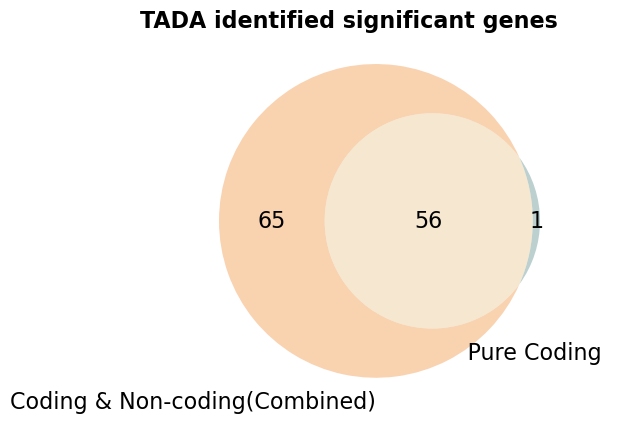

In [20]:
venn = venn2([set(combined_fdr["Hugo_Symbol"].drop_duplicates()), set(coding_fdr["Hugo_Symbol"].drop_duplicates())], ('Coding & Non-coding(Combined)', '     Pure Coding'), set_colors=("#F28F3B", 
                             "#588B8B"))

# Display the plot
for text in venn.set_labels:
    text.set_fontsize(16)  # Adjust the number as per your font size preference

for text in venn.subset_labels:
    if text:  # Ensure it's not None
        text.set_fontsize(16) 

plt.title('TADA identified significant genes        ', fontsize=16, fontweight="bold")
plt.show()

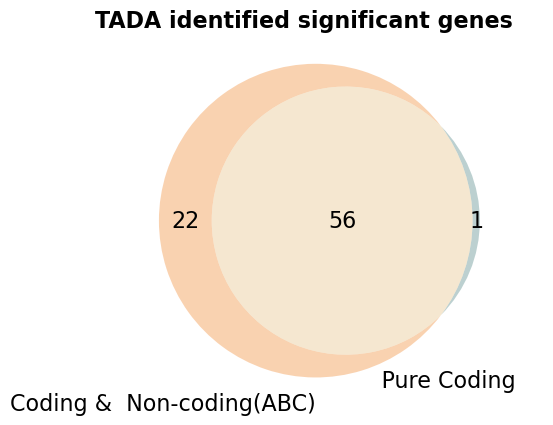

In [21]:
venn = venn2([set(ABC_fdr["Hugo_Symbol"].drop_duplicates()), set(coding_fdr["Hugo_Symbol"].drop_duplicates())], ('Coding &  Non-coding(ABC)', '     Pure Coding'), set_colors=("#F28F3B", 
                             "#588B8B"))

# Display the plot
for text in venn.set_labels:
    text.set_fontsize(16)  # Adjust the number as per your font size preference

for text in venn.subset_labels:
    if text:  # Ensure it's not None
        text.set_fontsize(16) 

plt.title('TADA identified significant genes    ', fontsize=16, fontweight="bold")
plt.show()

In [31]:
known_ABC = ABC_not_coding_fdr[ABC_not_coding_fdr["Hugo_Symbol"].isin(siwei_ls)]
len(known_ABC)

12

In [41]:
new_ABC = ABC_not_coding_fdr[~ABC_not_coding_fdr["Hugo_Symbol"].isin(siwei_ls)]
new_ABC

,gene_id,Hugo_Symbol,LOEUF,pLI,bf.dn.ptv,bf.in.ptv,bf.dn.misb,bf.in.misb,bf.dn.misa,bf.in.misa,bf.dn.em,bf.in.em,bf,fdr,pval
1919,ENSG00000095739,BAMBI,1.241,2.138100e-04,1.000000,1.000000,1.000000,1.000000,1.0,1.000000,47.755366,7.366837,351.805996,0.013524,3.313511e-05
2690,ENSG00000104447,TRPS1,0.111,1.000000e+00,1.000000,1.000000,1.000000,1.000000,1.0,1.165948,203.505690,1.549019,367.546485,0.011604,2.704386e-05
6907,ENSG00000136738,STAM,0.372,8.504800e-01,5.135297,1.009128,1.000000,1.000000,1.0,1.000000,1.000000,6537.348819,33877.656030,0.000164,1.276001e-07
8605,ENSG00000148482,SLC39A12,0.763,8.341300e-07,1.597076,1.012860,1.000000,1.000000,1.0,1.000000,1.000000,87.938078,142.249894,0.047205,2.143946e-04
8792,ENSG00000150347,ARID5B,0.110,1.000000e+00,10.678954,1.000000,1.000000,0.760324,1.0,1.341876,1.000000,13.349263,145.444502,0.046264,2.073531e-04
9193,ENSG00000153956,CACNA2D1,0.245,9.998900e-01,6.228395,1.000000,12.090242,1.360064,1.0,1.051552,1.000000,2.088056,224.876278,0.026530,8.561459e-05
10452,ENSG00000163531,NFASC,0.215,9.999900e-01,1.000000,0.826093,1.000000,1.000000,1.0,1.415586,1.000000,738.872450,864.041738,0.004958,9.480756e-06
11806,ENSG00000168916,ZNF608,0.165,9.999900e-01,9.030267,1.000000,1.000000,1.006927,1.0,1.008066,2.112419,31.277936,605.627702,0.005729,1.129854e-05
12356,ENSG00000171604,CXXC5,0.420,8.885600e-01,1.000000,1.000000,1.000000,1.000000,1.0,1.024518,2.043621,113.348207,237.320152,0.022486,6.718658e-05
15510,ENSG00000196387,ZNF140,1.699,1.167900e-06,1.000000,1.000000,1.000000,1.000000,1.0,1.059745,1.000000,25963.287299,27514.461724,0.000202,1.688386e-07


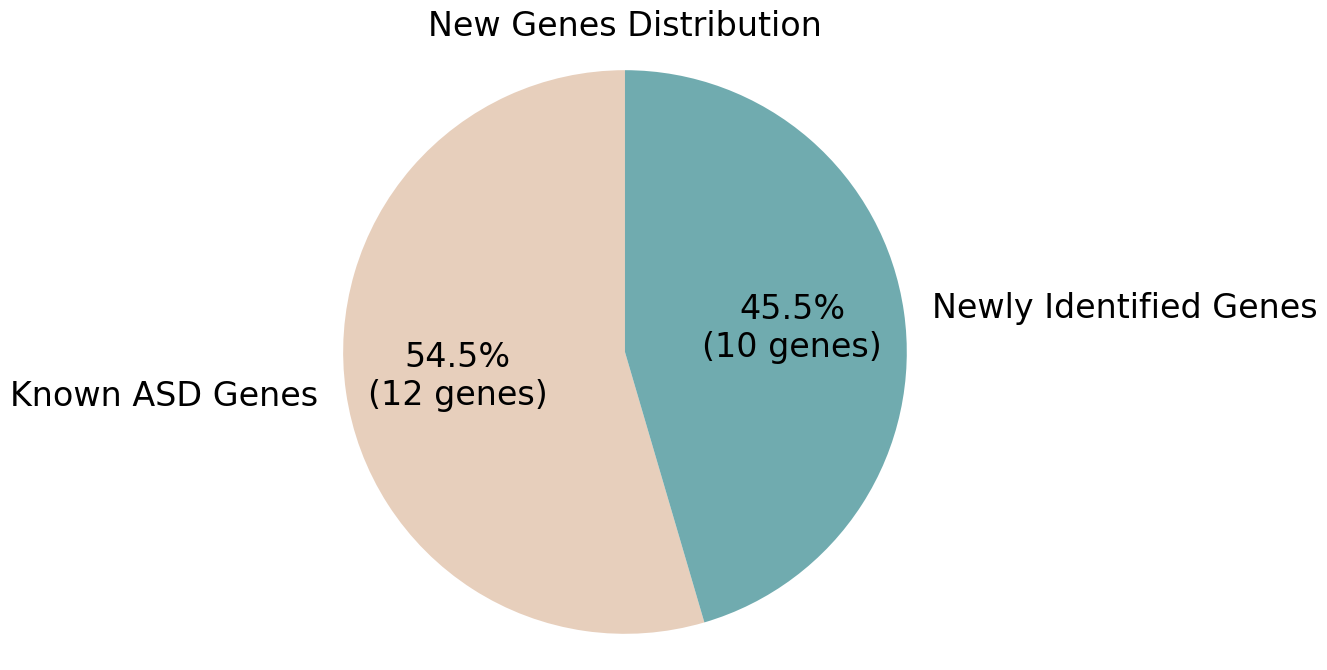

In [42]:
# labels = ['Known ASD Genes', 'Newly Identified Genes']
# sizes = [len(known_ABC)/(len(new_ABC)+len(known_ABC))*100, 100-len(known_ABC)/(len(new_ABC)+len(known_ABC))*100]

# colors = ['#E7CFBC','#70ABAF']

# # Define a function to annotate with both percentage and gene count
# def annotate_pie(pct, allvals):
#     absolute = allvals.pop(0)
#     return f"{pct:.1f}%\n({absolute} genes)"

# # Pie chart with gene counts and percentages
# plt.figure(figsize=(8,8))
# plt.pie(sizes, labels=labels, autopct=lambda pct: annotate_pie(pct, [len(known_ABC), len(new_ABC)]), 
#         startangle=90, colors=colors, textprops={"fontsize":24})
# plt.axis('equal')  # Ensure pie is drawn as a circle
# plt.title('New Genes Distribution', fontsize=24)

# plt.show()
# Correcting to ensure the right part corresponds to exactly 10 genes

# Define a function to annotate with both percentage and gene count
def annotate_pie(pct, allvals):
    total = sum(allvals)
    # Calculate the absolute number of genes based on the total and pct
    absolute = int(round(pct/100.*total))
    return f"{pct:.1f}%\n({absolute} genes)"

# Pie chart with gene counts and percentages
plt.figure(figsize=(8,8))
plt.pie(sizes, labels=labels, autopct=lambda pct: annotate_pie(pct, [known_gene_count, new_gene_count]), 
        startangle=90, colors=colors, textprops={"fontsize":24})

plt.axis('equal')  # Ensure pie is drawn as a circle
plt.title('New Genes Distribution', fontsize=24)

plt.show()


In [14]:
coding_not_abc_fdr = coding_fdr[~coding_fdr["Hugo_Symbol"].isin(ABC_fdr["Hugo_Symbol"])]
coding_not_abc_fdr
coding_not_abc_fdr.isin(siwei_ls)

,gene_id,Hugo_Symbol,LOEUF,pLI,bf.dn.ptv,bf.in.ptv,bf.dn.misb,bf.in.misb,bf.dn.misa,bf.in.misa,bf,fdr,pval
997,False,False,False,False,False,False,False,False,False,False,False,False,False


In [38]:
combined_fdr[combined_fdr["Hugo_Symbol"] == "JUN"]

,gene_id,Hugo_Symbol,LOEUF,pLI,bf.dn.ptv,bf.in.ptv,bf.dn.misb,bf.in.misb,bf.dn.misa,bf.in.misa,bf.dn.em,bf.in.em,bf,fdr,pval


In [25]:
yingying_fdr[yingying_fdr["Hugo_Symbol"] == "JUN"]

,gene_id,Hugo_Symbol,LOEUF,pLI,bf.dn.ptv,bf.in.ptv,bf.dn.misb,bf.in.misb,bf.dn.misa,bf.in.misa,bf.dn.em,bf.in.em,bf,fdr,pval
13401,ENSG00000177606,JUN,1.02,0.05962,1.0,1.0,1.0,1.0,1.0,1.130541,4.829483,91.797123,501.205781,0.010019,0.000041


In [28]:
coding_not_combined_fdr = coding_fdr[~coding_fdr["Hugo_Symbol"].isin(combined_fdr["Hugo_Symbol"])]
coding_not_combined_fdr

,gene_id,Hugo_Symbol,LOEUF,pLI,bf.dn.ptv,bf.in.ptv,bf.dn.misb,bf.in.misb,bf.dn.misa,bf.in.misa,bf,fdr,pval
997,ENSG00000100346,CACNA1I,0.202,1.0,1.0,1.0,6.02026,15.495567,1.0,1.347446,125.69964,0.048482,0.000161


In [17]:
from gprofiler import GProfiler

# Initialize the g:Profiler object
gp = GProfiler(return_dataframe=True)

# List of your genes
genes = ABC_not_coding_fdr["Hugo_Symbol"].tolist()
bg_genes = ABC_fdr["Hugo_Symbol"].tolist()
# genes = combined_not_coding_fdr["Hugo_Symbol"].tolist()
# bg_genes = combined_fdr["Hugo_Symbol"].tolist()
pure_coding_genes = coding_fdr["Hugo_Symbol"].tolist()

# Perform GO enrichment analysis
results = gp.profile(organism='hsapiens', query=genes)
results
results[results["source"].str.startswith("GO:BP")]
# results[results["description"].str.startswith("Factor")]
# results["native"].drop_duplicates().to_csv("/fs/cbsuhy01/storage/NetFlow_ASD/EG_linkage/combined_not_1d_fdr.txt", sep="\n", index=None)

,source,native,name,p_value,significant,description,term_size,query_size,intersection_size,effective_domain_size,precision,recall,query,parents
3,GO:BP,GO:0061337,cardiac conduction,0.004475,True,"""Transfer of an organized electrical impulse a...",95,22,4,21031,0.181818,0.042105,query_1,[GO:0008016]
6,GO:BP,GO:0045892,negative regulation of DNA-templated transcrip...,0.006267,True,"""Any process that stops, prevents, or reduces ...",1333,22,9,21031,0.409091,0.006752,query_1,"[GO:0006351, GO:0006355, GO:1902679]"
7,GO:BP,GO:0000122,negative regulation of transcription by RNA po...,0.006716,True,"""Any process that stops, prevents, or reduces ...",986,22,8,21031,0.363636,0.008114,query_1,"[GO:0006357, GO:0006366, GO:0045892]"
8,GO:BP,GO:1902679,negative regulation of RNA biosynthetic process,0.006830,True,"""Any process that stops, prevents or reduces t...",1347,22,9,21031,0.409091,0.006682,query_1,"[GO:0010558, GO:0032774, GO:0051253, GO:2001141]"
9,GO:BP,GO:0042391,regulation of membrane potential,0.006917,True,"""Any process that modulates the establishment ...",433,22,6,21031,0.272727,0.013857,query_1,[GO:0065008]
12,GO:BP,GO:1901843,positive regulation of high voltage-gated calc...,0.010433,True,"""Any process that activates or increases the f...",4,22,2,21031,0.090909,0.500000,query_1,"[GO:1901387, GO:1901841]"
14,GO:BP,GO:0051253,negative regulation of RNA metabolic process,0.013448,True,"""Any process that stops, prevents, or reduces ...",1463,22,9,21031,0.409091,0.006152,query_1,"[GO:0010605, GO:0016070, GO:0045934, GO:0051252]"
19,GO:BP,GO:0045934,negative regulation of nucleobase-containing c...,0.026179,True,"""Any cellular process that stops, prevents, or...",1588,22,9,21031,0.409091,0.005668,query_1,"[GO:0006139, GO:0019219, GO:0031324, GO:0051172]"
21,GO:BP,GO:0086002,cardiac muscle cell action potential involved ...,0.031436,True,"""An action potential that occurs in a cardiac ...",50,22,3,21031,0.136364,0.060000,query_1,"[GO:0086001, GO:0086003]"
24,GO:BP,GO:1901387,positive regulation of voltage-gated calcium c...,0.036445,True,"""Any process that activates or increases the f...",7,22,2,21031,0.090909,0.285714,query_1,"[GO:1901021, GO:1901385, GO:2001259]"


In [12]:
results_bg = gp.profile(organism='hsapiens', query=bg_genes)
results_bg
results_bg[results_bg["source"].str.startswith("GO")]

,source,native,name,p_value,significant,description,term_size,query_size,intersection_size,effective_domain_size,precision,recall,query,parents
1,GO:BP,GO:0007399,nervous system development,1.406327e-27,True,"""The process whose specific outcome is the pro...",2531,117,66,21031,0.564103,0.026077,query_1,[GO:0048731]
3,GO:BP,GO:0048731,system development,1.413720e-24,True,"""The process whose specific outcome is the pro...",3973,117,76,21031,0.649573,0.019129,query_1,"[GO:0007275, GO:0048856]"
6,GO:BP,GO:0007275,multicellular organism development,1.652806e-23,True,"""The biological process whose specific outcome...",4643,117,80,21031,0.683761,0.017230,query_1,"[GO:0032501, GO:0048856]"
11,GO:BP,GO:0048856,anatomical structure development,1.038530e-18,True,"""The biological process whose specific outcome...",5899,117,83,21031,0.709402,0.014070,query_1,[GO:0032502]
19,GO:BP,GO:0032502,developmental process,9.509504e-17,True,"""A biological process whose specific outcome i...",6453,117,84,21031,0.717949,0.013017,query_1,[GO:0008150]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
776,GO:BP,GO:0051216,cartilage development,4.286262e-02,True,"""The process whose specific outcome is the pro...",213,117,8,21031,0.068376,0.037559,query_1,"[GO:0001501, GO:0048513, GO:0061448]"
779,GO:BP,GO:0008366,axon ensheathment,4.509273e-02,True,"""Any process in which the axon of a neuron is ...",156,117,7,21031,0.059829,0.044872,query_1,[GO:0007272]
780,GO:BP,GO:0007272,ensheathment of neurons,4.509273e-02,True,"""The process in which glial cells envelop neur...",156,117,7,21031,0.059829,0.044872,query_1,"[GO:0007399, GO:0009987]"
788,GO:BP,GO:0060079,excitatory postsynaptic potential,4.967956e-02,True,"""A process that leads to a temporary increase ...",107,117,6,21031,0.051282,0.056075,query_1,"[GO:0060078, GO:0099565]"


In [13]:
results_coding = gp.profile(organism='hsapiens', query=pure_coding_genes)
results_coding
results_coding[results_coding["source"].str.startswith("GO")]

,source,native,name,p_value,significant,description,term_size,query_size,intersection_size,effective_domain_size,precision,recall,query,parents
10,GO:BP,GO:0007399,nervous system development,6.719915e-11,True,"""The process whose specific outcome is the pro...",2531,55,30,21031,0.545455,0.011853,query_1,[GO:0048731]
17,GO:BP,GO:0071824,protein-DNA complex organization,1.497950e-09,True,"""Any process in which macromolecules aggregate...",915,55,19,21031,0.345455,0.020765,query_1,[GO:0043933]
18,GO:BP,GO:0007275,multicellular organism development,1.899258e-09,True,"""The biological process whose specific outcome...",4643,55,37,21031,0.672727,0.007969,query_1,"[GO:0032501, GO:0048856]"
20,GO:BP,GO:0006325,chromatin organization,2.566549e-09,True,"""The assembly or remodeling of chromatin compo...",816,55,18,21031,0.327273,0.022059,query_1,[GO:0071824]
25,GO:BP,GO:0048731,system development,5.689144e-09,True,"""The process whose specific outcome is the pro...",3973,55,34,21031,0.618182,0.008558,query_1,"[GO:0007275, GO:0048856]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
497,GO:BP,GO:0010720,positive regulation of cell development,4.337640e-02,True,"""Any process that increases the rate, frequenc...",450,55,8,21031,0.145455,0.017778,query_1,"[GO:0045597, GO:0048468, GO:0060284]"
503,GO:BP,GO:1901362,organic cyclic compound biosynthetic process,4.615176e-02,True,"""The chemical reactions and pathways resulting...",4264,55,25,21031,0.454545,0.005863,query_1,"[GO:1901360, GO:1901576]"
505,GO:BP,GO:0042592,homeostatic process,4.684550e-02,True,"""Any biological process involved in the mainte...",1712,55,15,21031,0.272727,0.008762,query_1,[GO:0008150]
507,GO:CC,GO:0034703,cation channel complex,4.892933e-02,True,"""An ion channel complex through which cations ...",207,56,5,22097,0.089286,0.024155,query_1,[GO:0034702]


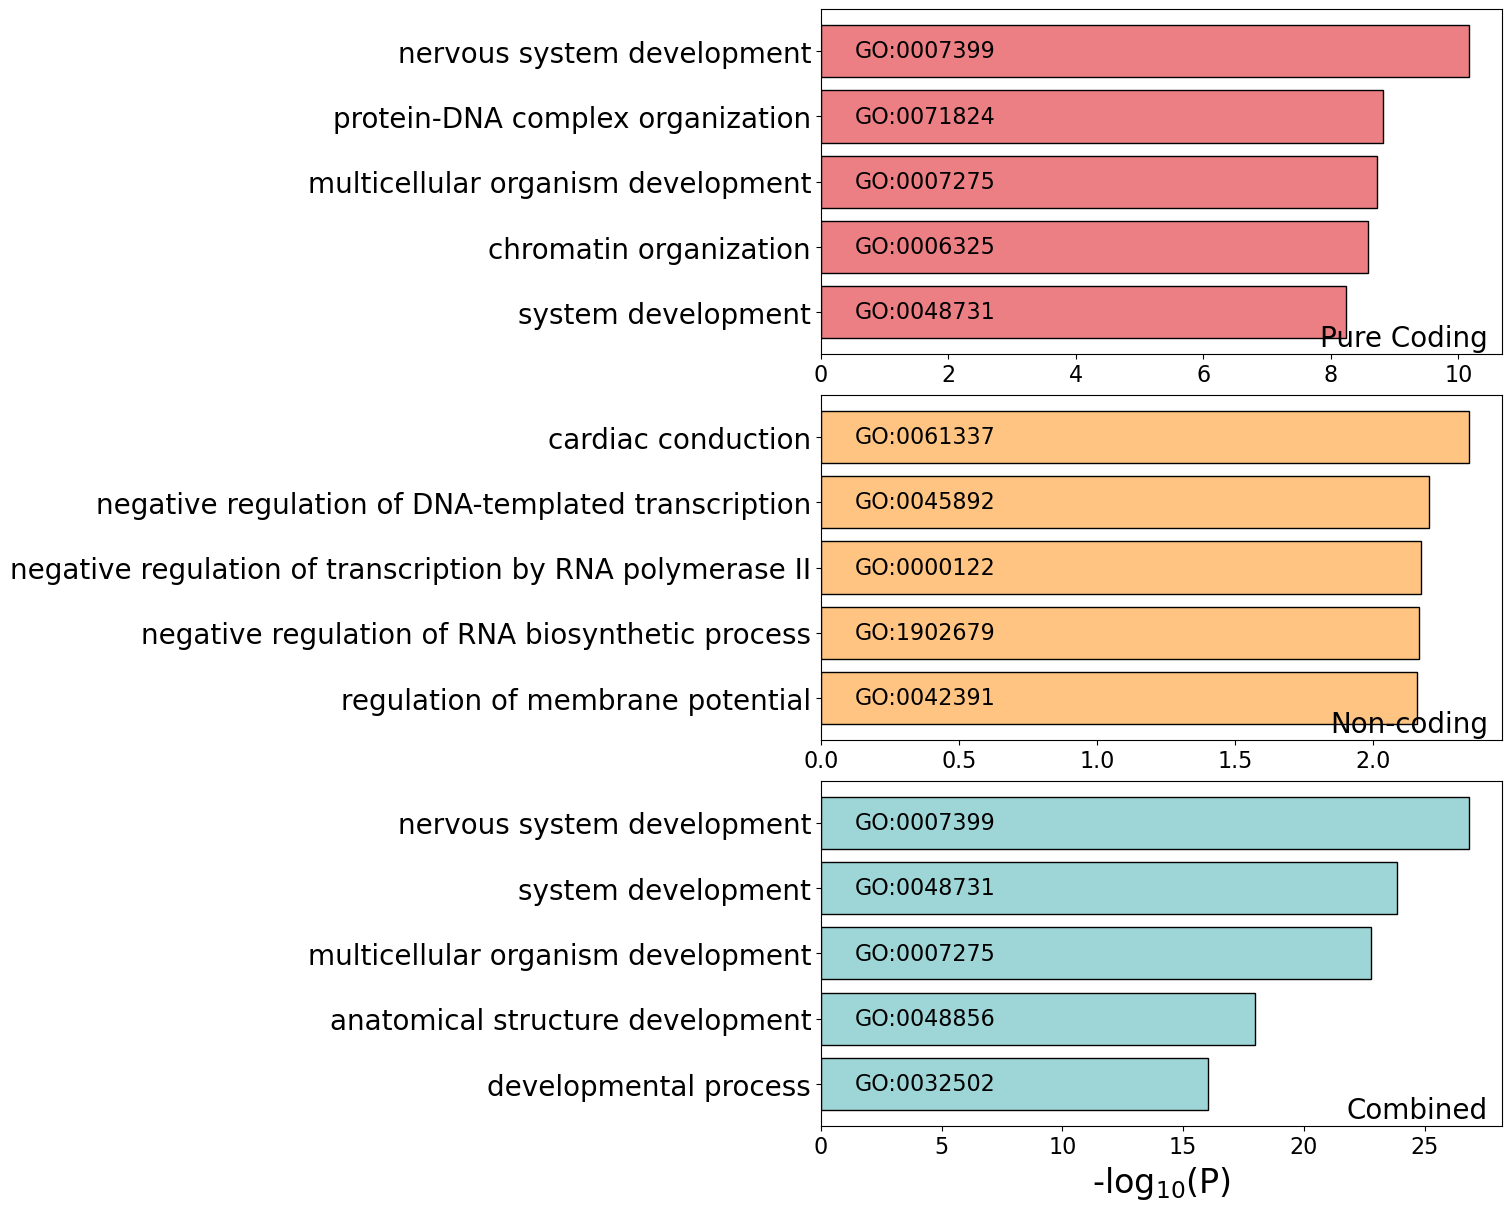

In [25]:
data_noncoding = results[results["source"].str.startswith("GO:BP")][["native", "name", "p_value"]].head(5)

data_coding = results_coding[results_coding["source"].str.startswith("GO")][["native", "name", "p_value"]].head(5)

data_all = results_bg[results_bg["source"].str.startswith("GO")][["native", "name", "p_value"]].head(5)

# Create a function to plot each category
def plot_go_terms(ax, df, category, color, show_xlabel=False):
    df['log_p'] = -np.log10(df['p_value'])
    df_sorted = df.sort_values('log_p', ascending=False)  # Sort by highest value
    bars = ax.barh(df_sorted['name'], df_sorted['log_p'], color=color, edgecolor='black')  # Add border

    # Get the x-axis limits and define a fixed fraction for placing GO terms (e.g., 5% of the x-axis)
    x_min, x_max = ax.get_xlim()
    text_x_pos = x_min + 0.05 * (x_max - x_min)  # Set GO term text at 5% of the x-axis range
    
    # Move GO term inside the bars, starting at 5% of the x-axis range
    for i, (_, go_term) in enumerate(zip(df_sorted['log_p'], df_sorted['native'])):
        ax.text(text_x_pos, i, go_term, va='center', ha='left', color='black', fontsize=16)  # Use text_x_pos for consistent alignment

    if show_xlabel:
        ax.set_xlabel(r'-log$_{10}$(P)', fontsize=24)  # Change x-axis label fontsize
    # ax.set_title(category, fontsize=16)  # Change title fontsize
    ax.text(x_max-0.02*(x_max-x_min), len(df_sorted)-0.6, category, va='center', ha='right', fontsize=20)
    ax.tick_params(axis='x', labelsize=16)  # Change x-axis ticks fontsize
    ax.tick_params(axis='y', labelsize=20)  # Change y-axis ticks fontsize
    ax.invert_yaxis() 

# Initialize the plot
fig, axs = plt.subplots(3, 1, figsize=(15, 12), constrained_layout=True)

# Plot each dataframe
plot_go_terms(axs[0], data_coding, 'Pure Coding', '#EB7F83')
plot_go_terms(axs[1], data_noncoding, 'Non-coding', '#FFC482') 
plot_go_terms(axs[2], data_all, 'Combined', '#9ED6D8', show_xlabel=True)  

# Display the plot
plt.show()


### Network propagation